# 04. Selección del modelo final y las 59 predicciones

**Reto AgroCebada FIRA 2026.** Este notebook explica, paso a paso, por qué entregamos el modelo que entregamos y genera las predicciones de las 59 parcelas ocultas.

No es un experimento nuevo ni una búsqueda de modelos. **Reúne lo que ya existe, aplica una decisión registrada antes de conocer el último resultado y la documenta.**

| | |
| --- | --- |
| **Modelo de entrega** | **E_JK = ½·J + ½·K**: promedio del modelo regional de Jared (J) y de MIX corregido con el contraste de verdor frente a las vecinas (K) |
| **Referencia declarada** | **MIX** = ½·media municipal + ½·interpolación de vecinas |
| **Error esperado** | RMSE ≈ 0.47–0.49 t/ha, no el 0.4757 de la validación cruzada. Por el azar de qué parcelas quedaron ocultas, en un conjunto como el de las 59 puede caer entre ≈0.35 y ≈0.63 |
| **Por qué E_JK** | Superó a MIX en las cinco evaluaciones con el margen más estable, aunque pequeño (0.003–0.017 t/ha); combina dos modelos cuyo orden cambia entre evaluaciones |
| **Qué limita al modelo** | La información disponible, no el algoritmo. El municipio explica ≈69 % de la variación, y de lo que queda recuperamos ≈7 % |

Cada sección sigue el formato **pregunta → comprobación → resultado → decisión y límite**. Las cifras se recalculan aquí desde archivos guardados con SHA-256. Un `assert` detiene el notebook si alguna no coincide con lo registrado.

In [1]:
# @title Preparación de Colab: tres bibliotecas, sin descargar datos { display-mode: "form" }
"""Preparación explícita de Colab y descarga verificada, sin cambiar cálculos científicos.

Este módulo usa la biblioteca estándar hasta que se solicita preparar Colab o descargar
el ZIP. Se incrusta completo en el notebook para no depender de un clon del proyecto.
"""

from __future__ import annotations

import hashlib
import importlib
import importlib.metadata as metadata
import os
import re
import subprocess
import sys
import tempfile
from pathlib import Path


REQUERIDOS_AUDITORIA = ("numpy", "pandas", "matplotlib")
MODULOS_DISTRIBUCIONES = {
    "numpy": "numpy", "pandas": "pandas", "matplotlib": "matplotlib",
    "pyshp": "shapefile", "shapely": "shapely", "pyproj": "pyproj", "gdown": "gdown",
    "pillow": "PIL", "python-dateutil": "dateutil", "beautifulsoup4": "bs4",
    "scikit-learn": "sklearn", "pysocks": "socks", "typing-extensions": "typing_extensions",
}


class ReinicioColabRequerido(RuntimeError):
    """Una instalación cambió una biblioteca que ya estaba cargada en la sesión."""

    def __init__(self, cambios: list[str], modulos_cargados: list[str]):
        self.cambios = cambios
        self.modulos_cargados = modulos_cargados
        super().__init__(
            "Las versiones se prepararon, pero ya había módulos cargados que cambiaron: "
            + ", ".join(modulos_cargados)
            + ". En Colab selecciona Entorno de ejecución > Reiniciar sesión y después "
            "Ejecutar todas. No se reinicia ni se mata la sesión automáticamente."
        )


def _perfil_fijado(perfil: str) -> dict[str, str]:
    versiones = {}
    for nombre, version in re.findall(
        r"^([A-Za-z0-9_-]+)==([^\s;]+)", perfil, flags=re.MULTILINE,
    ):
        clave = nombre.lower().replace("_", "-")
        if clave in versiones:
            raise ValueError(f"Paquete repetido en el perfil: {nombre}")
        versiones[clave] = version
    if not versiones:
        raise ValueError("El perfil de uv no contiene versiones fijadas.")
    return versiones


def versiones_requeridas(
    perfil: str, nombres: tuple[str, ...] = REQUERIDOS_AUDITORIA,
) -> dict[str, str]:
    """Lee las versiones de las raíces realmente utilizadas en esta auditoría."""
    fijadas = _perfil_fijado(perfil)
    faltantes = [nombre for nombre in nombres if nombre not in fijadas]
    if faltantes:
        raise ValueError("Faltan paquetes del cuaderno en el perfil uv: " + ", ".join(faltantes))
    return {nombre: fijadas[nombre] for nombre in nombres}


def _version_o_ausente(nombre: str, consultar_version) -> str | None:
    try:
        return consultar_version(nombre)
    except metadata.PackageNotFoundError:
        return None


def _modulo_cargado(nombre: str, modulos) -> bool:
    raiz = MODULOS_DISTRIBUCIONES.get(nombre, nombre.replace("-", "_"))
    return any(clave == raiz or clave.startswith(raiz + ".") for clave in modulos)


def _comprobar_importaciones(versiones: dict[str, str]) -> None:
    """Prueba importaciones y operaciones pequeñas; no entrena ni lee datos del reto."""
    for nombre, esperada in versiones.items():
        modulo = importlib.import_module(MODULOS_DISTRIBUCIONES.get(nombre, nombre))
        version_cargada = getattr(modulo, "__version__", None)
        if version_cargada is not None and str(version_cargada) != esperada:
            raise ReinicioColabRequerido([], [nombre])
    import numpy as np
    import pandas as pd

    if not np.isclose(np.array([1.0, 3.0]).mean(), 2.0):
        raise RuntimeError("No pasó la comprobación mínima de NumPy.")
    if pd.DataFrame({"x": [1, 2]}).shape != (2, 1):
        raise RuntimeError("No pasó la comprobación mínima de pandas.")


def _avisar_incompatibilidad_numba(informar) -> None:
    """Aviso acotado: este notebook no usa ni modifica Numba."""
    try:
        requisitos = metadata.requires("numba") or []
        from packaging.requirements import Requirement

        numpy_version = metadata.version("numpy")
        for texto in requisitos:
            requisito = Requirement(texto)
            if requisito.name.lower() != "numpy":
                continue
            if requisito.marker is not None and not requisito.marker.evaluate():
                continue
            if numpy_version not in requisito.specifier:
                informar(
                    f"Aviso del entorno de Colab: Numba declara {requisito}, pero NumPy es "
                    f"{numpy_version}. Este cuaderno no usa Numba ni lo actualiza. "
                    "La verificación cubre sus bibliotecas, no todos los paquetes de Colab."
                )
    except (metadata.PackageNotFoundError, ImportError):
        return


def preparar_colab(
    perfil: str, *, en_colab: bool, habilitar: bool = True,
    consultar_version=metadata.version, modulos=None, ejecutar=subprocess.check_call,
    informar=print, verificar_importaciones=None,
) -> dict:
    """Instala solo raíces distintas/faltantes en Colab, con dependencias restringidas por uv.

    Las funciones inyectables permiten probar instalación, versiones y reinicio sin red.
    En local no se llama a pip ni se modifica el entorno: lo prepara uv.
    """
    esperadas = versiones_requeridas(perfil)
    instaladas = {
        nombre: _version_o_ausente(nombre, consultar_version) for nombre in esperadas
    }
    cambios = [f"{nombre}=={version}" for nombre, version in esperadas.items()
               if instaladas[nombre] != version]
    if not en_colab:
        informar("Entorno local: no se instala nada desde el cuaderno; se utiliza uv.")
        return {"estado": "local_sin_instalar", "cambios": [], "instaladas": instaladas,
                "reinicio_requerido": False}

    informar("Preparación de Colab: Python y paquetes se comprobarán antes de leer datos.")
    informar("Plan: " + (", ".join(cambios) if cambios else "sin instalaciones necesarias"))
    if cambios and not habilitar:
        raise RuntimeError(
            "El perfil difiere y PREPARAR_COLAB está desactivado. Actívalo y vuelve "
            "a ejecutar esta celda, o prepara manualmente las versiones impresas."
        )

    fijadas = _perfil_fijado(perfil)
    modulos = sys.modules if modulos is None else modulos
    cargados_antes = {nombre for nombre in fijadas if _modulo_cargado(nombre, modulos)}
    versiones_antes = {
        nombre: _version_o_ausente(nombre, consultar_version) for nombre in cargados_antes
    }
    if cambios:
        with tempfile.TemporaryDirectory(prefix="agrocebada-colab-perfil-") as carpeta:
            restricciones = Path(carpeta) / "perfil-uv-constraints.txt"
            restricciones.write_text(perfil, encoding="utf-8")
            comando = [sys.executable, "-m", "pip", "install", "--only-binary=:all:",
                       "--disable-pip-version-check", "--constraint", str(restricciones),
                       *cambios]
            informar("Se instala únicamente el plan; dependencias necesarias limitadas por uv.")
            try:
                ejecutar(comando)
            except (subprocess.CalledProcessError, OSError) as error:
                raise RuntimeError(
                    "No se pudo preparar el perfil binario. No se ejecutará la auditoría "
                    "con otras versiones. Revisa el error de pip y reinicia la sesión "
                    "si la instalación quedó a medias."
                ) from error

        importlib.invalidate_caches()
        cargados_cambiados = sorted(
            nombre for nombre in cargados_antes
            if versiones_antes[nombre] != _version_o_ausente(nombre, consultar_version)
            or any(cambio.startswith(nombre + "==") for cambio in cambios)
        )
        if cargados_cambiados:
            raise ReinicioColabRequerido(cambios, cargados_cambiados)

    instaladas = {
        nombre: _version_o_ausente(nombre, consultar_version) for nombre in esperadas
    }
    divergentes = [nombre for nombre, version in esperadas.items()
                  if instaladas[nombre] != version]
    if divergentes:
        raise RuntimeError("El perfil no coincide tras prepararlo: " + ", ".join(divergentes))
    comprobar = _comprobar_importaciones if verificar_importaciones is None else (
        verificar_importaciones
    )
    comprobar(esperadas)
    # Evita inspeccionar el entorno verdadero en pruebas con proveedores de versiones inventados.
    if consultar_version is metadata.version:
        _avisar_incompatibilidad_numba(informar)
    informar("Perfil requerido e importaciones comprobados; no se garantiza todo el entorno Colab.")
    return {"estado": "colab_instalado" if cambios else "colab_existente", "cambios": cambios,
            "instaladas": instaladas, "reinicio_requerido": False}


def validar_dataset(ruta: Path, sha256_esperado: str, bytes_esperados: int) -> Path:
    """Rechaza tamaño o huella incorrectos antes de que se abra el ZIP."""
    ruta = Path(ruta)
    if not re.fullmatch(r"[0-9a-f]{64}", sha256_esperado) or bytes_esperados <= 0:
        raise ValueError("Contrato de identidad del dataset inválido.")
    if not ruta.is_file():
        raise FileNotFoundError(f"No existe el archivo de entrada: {ruta}")
    if ruta.stat().st_size != bytes_esperados:
        raise ValueError(f"Tamaño incorrecto de {ruta.name}: se esperaban {bytes_esperados} bytes.")
    huella = hashlib.sha256()
    with ruta.open("rb") as archivo:
        for bloque in iter(lambda: archivo.read(1024 * 1024), b""):
            huella.update(bloque)
    if huella.hexdigest() != sha256_esperado:
        raise ValueError(f"SHA-256 incorrecto de {ruta.name}; no se usará este archivo.")
    return ruta


def obtener_dataset(
    destino: Path, *, file_id: str | None = None, sha256_esperado: str,
    bytes_esperados: int, permitir_descarga: bool, descargar=None,
) -> Path:
    """Usa caché validada o descarga explícita a temporal; publica solo bytes verificados.

    Una copia local incorrecta nunca se sustituye silenciosamente. Una descarga rechazada
    queda en cuarentena para diagnóstico; no se cambian permisos, cuentas ni credenciales.
    """
    destino = Path(destino).expanduser()
    if destino.exists():
        return validar_dataset(destino, sha256_esperado, bytes_esperados)
    if not permitir_descarga:
        raise FileNotFoundError(
            "No está el ZIP original. En local, coloca DataSet.zip en data/raw/ o indica "
            "RUTA_DATASET. La descarga solo se habilita explícitamente."
        )
    if file_id is None or not re.fullmatch(r"[A-Za-z0-9_-]{10,}", file_id):
        raise ValueError(
            "Falta el ID de Drive del ZIP original autorizado. Configura ID_DRIVE_DATASET "
            "(no el ID del notebook), o proporciona una copia local verificada."
        )
    if not re.fullmatch(r"[0-9a-f]{64}", sha256_esperado) or bytes_esperados <= 0:
        raise ValueError("Contrato de identidad del dataset inválido.")
    destino.parent.mkdir(parents=True, exist_ok=True)
    descriptor, nombre_temporal = tempfile.mkstemp(
        prefix=destino.name + ".", suffix=".part", dir=destino.parent,
    )
    os.close(descriptor)
    temporal = Path(nombre_temporal)
    try:
        if descargar is None:
            import gdown

            descargar = gdown.download
        resultado = descargar(
            id=file_id, output=str(temporal), quiet=False, use_cookies=False,
        )
        if resultado is None:
            raise RuntimeError("Drive no entregó un archivo descargable.")
        validar_dataset(temporal, sha256_esperado, bytes_esperados)
        # Mismo directorio/sistema de archivos: la creación del enlace publica el
        # archivo completo y falla atómicamente si otra ejecución ganó la carrera.
        # No usamos exists() + replace(), que permitiría sustituir una aparición
        # concurrente entre ambas operaciones.
        try:
            os.link(temporal, destino)
        except FileExistsError:
            validar_dataset(destino, sha256_esperado, bytes_esperados)
        except OSError as error:
            raise RuntimeError(
                "Este destino no permite publicar mediante enlace atómico sin reemplazo. "
                "Usa una carpeta local de la sesión; no se sobrescribirá otro archivo."
            ) from error
        temporal.unlink()
        return destino
    except Exception as error:
        if temporal.exists():
            cuarentena = temporal.with_suffix(".rechazado")
            os.replace(temporal, cuarentena)
            detalle = f" Archivo recibido conservado para revisión en {cuarentena.name}."
        else:
            detalle = ""
        raise RuntimeError(
            "La descarga no quedó publicada como DataSet.zip: comprueba enlace, permisos, "
            "cuota y coincidencia de tamaño/SHA-256." + detalle
        ) from error


In [2]:
PREPARAR_COLAB = True
import importlib.util
import sys
try:
    EN_COLAB = importlib.util.find_spec("google.colab") is not None
except ModuleNotFoundError:
    EN_COLAB = False
if sys.version_info[:2] != (3, 13):
    raise RuntimeError("Este lector requiere Python 3.13 en local y Colab.")
REQUIREMENTS_COLAB = "affine==3.0.1\n    # via rasterio\nattrs==26.1.0\n    # via\n    #   affine\n    #   rasterio\nbeautifulsoup4==4.15.0\n    # via gdown\ncertifi==2026.7.22\n    # via\n    #   pyproj\n    #   rasterio\n    #   requests\ncharset-normalizer==3.5.2\n    # via requests\nclick==8.5.0\n    # via rasterio\ncloudpickle==3.1.2\n    # via joblib\ncolorama==0.4.6 ; sys_platform == 'win32'\n    # via tqdm\ncontourpy==1.4.0\n    # via matplotlib\ncycler==0.12.1\n    # via matplotlib\nfilelock==4.0.12\n    # via gdown\nfonttools==4.66.1\n    # via matplotlib\ngdown==5.2.2\nidna==3.20\n    # via requests\njoblib==1.6.0\n    # via scikit-learn\nkiwisolver==1.5.1\n    # via matplotlib\nmatplotlib==3.11.2\nnarwhals==2.26.0\n    # via scikit-learn\nnumpy==2.4.4\n    # via\n    #   agrocebada-uv\n    #   contourpy\n    #   matplotlib\n    #   pandas\n    #   rasterio\n    #   scikit-learn\n    #   scipy\n    #   shapely\npackaging==26.3\n    # via matplotlib\npandas==2.2.3\n    # via agrocebada-uv\npillow==12.3.0\n    # via matplotlib\npyparsing==3.3.3\n    # via\n    #   matplotlib\n    #   rasterio\npyproj==3.8.0\npyshp==3.1.6\npysocks==1.7.1\n    # via requests\npython-dateutil==2.9.0.post0\n    # via\n    #   matplotlib\n    #   pandas\npytz==2026.5\n    # via pandas\nrasterio==1.5.2\nrequests==2.34.2\n    # via gdown\nscikit-learn==1.9.1\n    # via agrocebada-uv\nscipy==1.18.0\n    # via\n    #   agrocebada-uv\n    #   scikit-learn\nshapely==2.1.2\nsix==1.17.0\n    # via python-dateutil\nsoupsieve==2.10\n    # via beautifulsoup4\nthreadpoolctl==3.7.0\n    # via scikit-learn\ntqdm==4.70.1\n    # via gdown\ntyping-extensions==4.16.0\n    # via beautifulsoup4\ntzdata==2026.5\n    # via pandas\nurllib3==2.8.0\n    # via requests\n"
VERSIONES = {'numpy': '2.4.4', 'pandas': '2.2.3', 'matplotlib': '3.11.2'}
assert hashlib.sha256(REQUIREMENTS_COLAB.encode()).hexdigest() == '8f18975fe344552700b5efe887bc0ede3128554a73f1457649652b35eb9cd95e'
preparacion = preparar_colab(REQUIREMENTS_COLAB, en_colab=EN_COLAB, habilitar=PREPARAR_COLAB)
print(preparacion["estado"])

Entorno local: no se instala nada desde el cuaderno; se utiliza uv.
local_sin_instalar


In [3]:
import base64
import hashlib
import importlib.metadata as metadata
import io
import json
import platform
import zlib
from datetime import datetime, timezone
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

FECHA_EJECUCION_UTC = datetime.now(timezone.utc).isoformat()
assert all(metadata.version(k) == v for k, v in VERSIONES.items())
print("Python:", platform.python_version(), "| Ejecución UTC:", FECHA_EJECUCION_UTC)
display(pd.DataFrame([{"biblioteca": k, "version": v} for k, v in VERSIONES.items()]))
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

Python: 3.13.13 | Ejecución UTC: 2026-10-12T04:46:41.338478+00:00


,biblioteca,version
0,numpy,2.4.4
1,pandas,2.2.3
2,matplotlib,3.11.2


In [4]:
# @title Insumos incrustados: tamaño y SHA-256 verificados antes de leerlos { display-mode: "form" }
INSUMOS_INCRUSTADOS = {'metadatos': {'ruta_local': 'data/exp_10_verificacion_contraste_vecinal/metadatos.csv', 'bytes': 13917, 'sha256': '9882c9793559084a98ddebd3a08137baec766f83df1191a29a6485077e925424', 'uso': 'metadatos', 'bytes_zlib_base64': 'eNqNm9uOHraRhO/zFH6AAcEzm5eCIiRarKUg673ZG2OgNRIFsmQkEbB5+/2Kh3Fke0jZgGTZ/vmTfaiu6u55/fvv//T2P1//4e2btw/ffv74/t37n95/enj59s1//Peb794+/N/3Pz786/sff/fiDy+/9z48vHz88NPnD/zy+PHh1Zvv/vzqzYtvX7/S/1ly6dm74LPlGKzbQwzVW+NfWU2pthDWKfHh5V/f/+Xj418/P/7GMc1i9M6iL/pM6xzTa2zmWvD8p2w+rXPSw3+9//iXz+8/fH7HMX/686vfv3758vXbNw+llmTNZd9Dyj0Hzoi+lxyc8ceeYtlXyccHWenBRZ7F9XvVTSqPKy7m3q2E7us6ppxf1ENOrviWLeVc63iRL8HlyHk++7yOqZdjeiouNyzju5d9Iw/wGKYG3zPm2YZpXxjmF8fUEHJ3zXhAqCkEHVOb766GyIVStXWKnW9TY6nOeoklR/w0HlV8cr5UIqFxi3VOf3j5+fHzP3/46Yd33/zvD9/88f3HT3/79I/HXx1YamsO5/iUeGTVvRJfoogKqfjc53nBn+/VfDUXWhjhE5PuVZrHabXWHmrYx4Qvj/n38LFoIbhSeg8h8fXjbbXI8aHzL5Mtx4dLKPeWuiuhNvMxRmVE79jLxV587Lhgn5NunvfReZkl+RaHrbFwdqGnmsmJso7JF9OEVB15U417hZFZRLJu2EO0TJSuc27xbDwrFcIQm6Y4zGPkPsEQrZawj6nPm7hZsOj4YGup+jbDJ+dMhmL8XsJ+UrtcJZPVtaXmU8Cgw9v4TCcnLrBiOVxiObXqXYoxkeCpzAeRG45ga6AXl1zn9CNeJD2ggBstkWN6E0FTk6teOAQqzVOif3j14/sP7x8/fvrmf7jPPx9/fVLqxbXEXSogqgDkgdwR49aUuccycQzHh2FkA0uBzCrASdPKhbcSfqSIzysA4yWQsXDky5OeVmayN+sEco382edlH9LtYJ/iQUqHkXwjUOooEE3xZ96IPmtluSte4hikqi5kP+I3jVe1GJvzBHEnG3xc55QvrvPv8Qe21+oy5cAAv5ELeBxgLBkbU8i2gS+YbKoqHvDKGUsMpChEkSOW8Hi0/aJ2uAmhQikgBQXDqg41AfBcjtiJFNJtXDukUwNzXfcyJx8bqW1EnQNu8DsAv87oz9+DdwcH4OHNAL7oHtiYgA5BZq3LqMk/X3bDBKXSeBKZNEoLGEgkF2sRx68MSAfwbZXK5LBrj7HEWSwTSQQ6AS7WV+lOl4htls3hBOCk+1xGjFQMQpaT72GHWjojryXgyUUDZ2Lhn2c1AcG70JsSsx+UjyU3U8gwLddXkZx2IR1cDuRVDFxpHVO+rlZW8pHki/AhSltcGeAbtAm0CA2nrwOPEIxXwGzjUnCTMN+WAAegD2APu8qldkS97o1iGXPNEAoTeNZYi8CdJ9a+kzHZ0UTJwFtgXGfUxUrwnauCvkpCrghOhwiOlHwXJm0sNjIpFzkrBFEm23Uy+zPtyyWpgEBiQx/Glb2pKZFggGstuobFjg/C6dAsLtUKf+lBBcc4Qgn0hRbty8Tn8ylRaUFHwK1GP20SsGziDP7els3pCAyxE8CKkuDLLJAEjvNtAHF+skn+iqKkYoJ5yF9vfRSlIiZAnSIV4r7OhT1APaIr1UNnLbaRmZWC4IrJLFSTFXa5Hr0k7gr1LTzHlzK8BBOCZ7cAJyCEVsDk9vAd+fTIQe8+/YaX9CaobKFUpmGeBPw5BYtBZ/PCiWwPbx4/Pr57xEY/PSo3v338+zDWi7+//8evjUXk42tyAmJUlYZCUz0cIAXVAeJt936jfo06RaFsXbJjUD8C2CU4MdzENlEq/pAX3aD3uDqDz6kMXgLyqKBjMsJxnxEeXnz48dOHT//6NeJYSlJyGCUKxTiDOKDmANZNdWs5H/L02wj2RVCSY0mfhL1yk5EbiUilTljNInMrBMqFTxCGDu/DkTDz4FvY1aCmYIeRZfuYm8yTeQLlsuXJrskyTCyOgvCsO5JK+QqyBeenUkPU+yRJqTlqEZQUKFjH1EvJAVmcAgjHcZVxDMEolmsSIOuUdiMmmLgXkorYjiPLuAu2SVQPM9vH2Nk0fKmDmMApkPKDE6CHq4NFdpAI2bmO6c9GTqtUFVgfGF5RwKoPMMdKiiFegLW0yWO9CTs+BW6ANZ3aNB4EiQXvUefQ4u2lGp5PBK/STb21hhbyo1R5RBwwHRE1WHmfcaPDQ7xQfdGseQQebzRpInxFKj7d5YTMhdIGuFfJjrBEBxHvIE85ht0tqflr5bN5CIV+62TmlM8Ga8fwPOypftbys6e+qDUdSzixNZgJWSg3kewUQswLSMLB1gH1kpMQcWGdSScOig+zJxJxN4bfxbNeehSQNpC8UmrKYG9kOapc7icfMfo6xW56A1IMuzGeMPK6ql8CVBCMYTcU6gWBSWZoUpM0BILD4loZZxslLK5Tmj+zAcIcOclvUJFYJgOU/42aVyFPy7rtEL3GtzmJ1Sb0ziMZgRbVX2Ri2aZt8VpRklPfSaA76glxTw1skoR9k752aUmQh5iAasL3pZUCPIZzMlbvT6qlnbHXq2eIf/SkKNsWqltzUZTAFDrrlIOSI0q4PrEun84uHbUKJA4iOsYf1xn1KDpgz1B88o7PDB1HmAQSCoAiG+s27g12I+KFwCPnapzGrfAAL9BqW223MxXm3tnpQmnAvyLFIx9AW73xKVL6WXJEbl/T6NVE+Rl54HuQqqRSIfiXf+wYt0VNGSfQBxfIHR1D1GeVS8mEXUbszIWL+isFd1CT40xnyVTKSGg4fLdXKA6/iU2wPLg0sYI88KONZkpBx2fFr2x3Qyx9JVbiD3StxBKgaZNUxcGzYvCSDsvbBMKzZS0r7IZ9IVATLyG0FNgM/Jv03TqjHCVYIOz4mGTbDJiSFEGQZC6ZnrxUn49/1A2IC1UQm2u76wRkZaCLKNz11U49CKgPaYhHkxTToEBVTVMyCXpXtptPLYjemodlikfziIksHZnaK7WllBC3Uc+BG6QFCDsEQh7xVrmE4i1KgWxm2C9kAYJRHYkk6ZZn57UorZq6/37V1n5qQ3BtiifpTBmlRo/yDEN0ak/m3jZV6De0JRxwJ1QONjkKotoZmmagM/wT0+3pAHClw5aT4JVQCwPgUKGKVqqS2NQ6Ix9a2klTFWoeCUOELVYJrMBhkCQw8X2RU7iCSCStuFIgYmcbsI9OBIHTut9Q2y9dM6JE7UR1b+OsZN3EepPaBRhqH9MuhBspDWiD2hB3W91N6olkKQw37LZKP5PcTL46z0XQt1KdCn6CxBnYL4jbmdzP3V/KD27tsJ3Y4ZjDTcQJOIO7qG9LaQd/C90oXoBExCJlDYvQXq2q3VlWYzL4c+eX+BSVlFxTB3C6ivcQ0W3UprDPucRvETIkC1ADqepxDknqNEAgHtYh6dwXRy04lQ0Keh5NtKqyDVgUNf9XWdSg5Vxbc4pDlKVASi/CTJojb9C1Hc6wzrk0IJqASipTbfm8ZgbcUC1ydbXDOuYSxK2IS+ISQg62OxmQV2PaJD5Xy5Ucf66ojT5IQ0wEtR/0eQ9OOvW0A2V6kdxwGcSRBbGoSZTVRh+NECzdowZegKjluI7pl2MAOWpsjklttDl2Rc7An6kI+GtZ5Tp+k5iGEgLfPs/evHo9TnGdCJrlo3AJXxRqlkOwLIVwdEy9j0OmF/UXV2EMmsCdclJiFS0+GMNsEgGjMHGRK1OTeh1zmCUnhK9TR54abZrFUJJQRIJfoZ+ttA5nopsTDwK/gZa2ZkNiZA7A60BeStsw5ca7cVMFHtB5wN6MOuUjd5KA3bc5kd0Wi4kIQrmrGn8CFs3vxO3Cz0AV2lldQeXQL009Lg0WhhxBtkGgEx6qG6mCPW9bTXgdN+cCEbIwm6SGVSi5UPq8kyh8/RDZqhvtF/l8HIhQIRn4hXxdpRIufWnnfcmOqqqtBuagYJqLDdAAp1hKfs/14I5nYqMBHmxXArYuCRja7KX0ojbxOuYc0ipIAtORBnNchBZAGlsoBSC0ZfbzLA7xBwkp6leozzSbXka1iuoS9ac8vYziUBIadqE9rSgi17TdQ4yD6mnM+zY3TNYcLecBNXOeoUUPLkgUcMV9yimquTOGURip3s71iJDEtNRLg+Vs37fb5AjLoIbRGuorTSkova9kF8vefrJn1UpWZ5qyT4D0OIGdsCxUCUK+bNP2w/4KokbDnAqDl7iSYEJWECuJcLE2ZXFI/mu6rWRZki4HTAV0nIWiRakn9VIoyOs9KdwWK5D3oTbJhImlEABCmoOxbtqdg3CZzIEVVX08sqlIbI96JUzuCEG49mrLhMtkrsmWkixUcPwz3IR1vMtJAYDq3td5XsNVAgsIQ9pSN9FRs6k9VAJxh7gsK+7SJXqBTahAoo5HNQKn9NGYXX08yEpaoXcex1HrKCq+AKl7Vh8USdwoauKznd6eF6UkYdZoAPSzNi6iQWrX7kiCIvmni5wZseSNAz5VYfLohtSk6TBUErJlcbuoX1eEusaeUh/mF0OKSeWryfub4eRLD8KEtWrUKvTGMteY7qokN/RdX0Uin9fTWtCc0qshY6N/DEwMzeG9SueuejmefFTxKiy24t48cco0FVNXmhxYzflwnMiJpzkPkUpAzKrgsY3SQCqh4Ffg5jOhiGpYhLGoAlEb5ZeSjOynGqO/LWyrlPMx6kICDFAlNdJHHWjaoNLwC9jaLqqHBj9XIGXkIDJm4l1CWnYtOyEPnx50aEBQzIgLxDL1J9U5uvUa5RD6qpz7GpfOGZDpTMJSnYLZPcASjpypushmjbl/1ZRKSy/Ee0S89TSInyYISnSIOoRuHlb8VwBVNhUO+PjMgt40ee++EwLbUYfpm7qjBEht4IkWp5TX1EnirgMWpNRqI2iM8PwZbfRRqjpe0c8ziB6UHLEPo97yqRzHyVRBpw0NTROnHKwSGwSzYd/8dJF8OiSoxStU6BrsT/lfKC54ywNYKxOv87ZYx3qm73xqNs9ER2FCkNMSc9jn1GcLrXof2gkxYhgAHoUWSgcV6UgYoGGThnLegWg6hqBAhjU/B0sJdga4cL2klYJ1zKmBBntDJxH/LfY5pu0tmkb11G1tfK4zbhNjrUKpxqtv52cdidp9JeCytPNy0WXeJt0lO5hFcdPZ4Y+dZzYgI2vZY51z20Gr+nJN10Wa531QCMCoFjTj2sQJ9UYb0KVwuZi1uDZ3IBFmxek2XrV6pVFNF0+VsepaNXQYsVfTkGaaMNlq9XDlhxfPTJyVdPJzbbOTAWOAdGgUGKQo1+evG5RokkDQ46Yyt5MQulC+0c8GNLdt63mqhDkcDlUP0NKUT0UcyGIhiMzv69y2KHkQ5xQtWpW+ep3gZiMItBy6b3NbCbauyVJXLqXV1qPCOS1Lmzrs+zq3RpqHNkRRwT51JcISCYd2LtrrXac0f+EwVVs8Yzl66m0SW8PspoFI2qZp4aq3qY9aUAHTplauY2dWCAH1WBW/XaO3aAzklceA3hAnRbvxamfsYVlohy4wNQOpHLSi2ue4WNSHcpfnKsjqz7T8NaUtmgIHtVxHV3tchyLrtPEEQdoI3E7NYNxUtWoRu8Zjc3TRtdkD00RYLMRrl20HLUJxClIEMZqn8uuq4rDpmOKmiL+cu/1yl5gENnSA93FmE1cRUkHteqlP5r2tAUtaZy2BEMKzL4jkIzGaGklbULRbI80POgRu9hjCblMWp40/cbO1+UP2H7ZtvDT0kEphMmfgU8AFUxXM7LtYuPYoi9NCPbU2TGqGteYjTdRkHROPulrLfMjWrtb00ubaqtPUtv8MvHYaYZA9lOqohG6zg5LzqI/ECiGXltA6Ddy0vQ/2ojSB+1kevX4GQb9oFLmvcYFeTSH1syTSSmk2KCW3nRY3+pjFr3PqcXdjbJdqgUU/ajC7nEWNOSyDYF9HnElDVot+7B2Z+jlzHRoKoDVRtZq2c45DN+20qmuNIvITuSHTwKfpJ0L67lXYbcfBSwgLAgjeeQxg1WSUCsuy3cb55djtixET/F9bn1p9JrbCbMBoIhq1/5A2+h+nbvopBM3Px+LtbKpTy+CXVTuqT1Kvx9M9rGnJQ0JCYnX9eILmZeSmtm6Wh/ulwwDiarGgQhXK6jDgINQEQUtBSLs70M/Lv6loLcLEnXqb7WPonKi7pjBxh36/NX7JOoQMb6DMTrytkUKJm7OWVdcp9brGmcf2vNdKs4i81jiTVtCROFCG0p/81G7mQR5hUUppSRO5oXcdGgwLBxpq+d3/A4gAwGA='}, 'k1': {'ruta_local': 'data/exp_10_verificacion_contraste_vecinal/variables_197.csv', 'bytes': 31992, 'sha256': '445aca6ddd1602d3db9b4035673f22b274a82cfc7e90a605bc34e7ba67561d9c', 'uso': 'k1', 'bytes_zlib_base64': 'eNqNXduSHMdxffdX6AN2O6oq6/rIoBgybYtUyPKLXxhrCKbggAAGCTisv/c5WdVd2du93bMD7iwOljM11VmZJ6/9/e9/+tOP//b9H3784cenP3799OHdh18+fH769scf/uU/fvjLj0//99Pfn/6B/z58+vL+519fPv70y9f/+vjh3ctfXyb07vOvv77/+QOgf/Xbv3/mX9Z/2f/lJzx9fPnpvz98+vDl829P//v+3YdPn3/76ef3n//+/suvH94ZbPyOedfX/zLf/N3LL1++/vryG17+3fsv5u9/e/ntywt/8cv7f/rmD9/+5Jx/+vbl4y9fP+Lby6en7374y5+/++GbP37/HT9xiqlFt3gXawy+tvoUfHa1AKpZJBfvn2JYpInbvhRJoT7hy/dHCU8+xvF+4enbv334+dPL376+nLxhqSG4pQaX+Oql4Q1bDqUuxTv8U6xO8EtLbfbrDFlqlCCu5MbvqaQHIXyi8acUrDqPVcvTv3/49PPXDx+/vsOi//Tn737//bfffv/jD08pJ6llia55iS16rDi4lqLHS7fYJCRsiCxeJMS5PCKhlrTtWnx6jkutrjY3Hj49PacFrxlyWqETJOjDS8OaZSw2Xl7SmppfAi4sLmDL3OGMy5sWrq8m31x+krg4SYnPqeyurbmo2WxPur6ozeMDJ1dilRhz1ovqkl9iwFu7iAXjCuLlW/bYzcjvRCSEieB3Fl9Sq3n+yhK9K7ICsZ0gPqx/ijdSmG8W3AQvVSCG3OXKa4plQgqzdy1CFnV92PVSwvoggqft78XjorqlhZZwelIsDhcO8kEsCnZixfIZVPXhM6+tG4suOyF8tebsfWxLqbiEPgsEGGvOeLEl+4B9llyfkluwOU0aRD2Lw+afQZ6nO8YNSu1BKOnDC5bs2lhyvd7nHFLG0U343NivooKRnCwuZaiewo8cM/bGnBTIWoSwBIjns4dE4DW2gxUIYRf9hFI9xbxb/2Qe83WH29O3X1++fnn/y/t3v/vr+9/9M9Tr/3z+7eWw7pRLWXC4nQikJHOvBZ+FmtJLcpA7CQuOx/r07LGGEqA0xyMqBGGVCdVTbOxq5s6OA45lX+5qcbliZ7zq0CDc1VQcTnjOuXnKYA5LbjGaw5VVRxkk8xILRN38EhCo/ImkM0TWPyq748BBHndLthq0horPnVJrUGHYQZWCnKiRPK6Wl5opBRGfJqWKQ5cE+wIkxWgQXIUFIoDDK1RtkCkANTsJG+BPkKgPj1f0YYiBv7FRDSdmSZCc6kIINIp837jgpLvQcAIz1OxSCkD+AOWKH55lgYFxEJfGP+I6VFNaoQDDcAIVffiE/8I4VtjdG/XlAjQ4XgVWLeixwmGKi28QKVhRLKthPxNUVKj9O5FS20RgCyES1UHyCi8Nvwsg8cFAR2CeLF1xGSuONyLrJcMCQEthb72afR5X7HKDoYywH085YYH+KfPwO5U8GIfs1hVTPKEPYvMbdIaM3cwU0WG9/J31qrjcMIcOUpmh3SieFbQIagsnOuFiwHpWiBOfW23R8BAY7Fzxb9tXUUhSnUg4g4ZYqpVdj31++wxhZ2pYsLIC6+dK16QxUvhwulryKolJ/FSk5xCkuIJqgcm4hO9BFMJv1YyDxu8hnCDDXJU6SQHU+fW2RpCkXKQ48Tg0qqXwevwQgs8KiQSHSp5nCMLsUjH8yS04+m2uG9cAUC7Z7v0RyfpQJiDrUbqxUFKyIxERsCRJ/eLDvC6OQlUz9vsp4cxmKpTxFbmvDkIjBvIQkRrmL4knBGI0oXCCiD46F01jxe2S3gmvOjQIDhJEn4IAVQrtnh0JKujqk4AtQ1DMdh6RZ9qtOo0udObD2KCkyvrHmoN7+u7vHz5+ePn0+Xf/iX3+8nJcN7T4UgR7zFNNIwDBwN7jgGFz8alxzLCtTewyj8gkqGoxx1UO/vIq4/BUR/qNg+p4oPX0gBuB2EAlwqBnUvYU4s7PwXUnQzSnB9sBfTWNUomEcN3DhPwZNKw8VeZK98KNFcLRgRWn5SuSOneCAsfRzDi0MKNKnSCFUYpSpozVzK1KTw3aXSrO11h+AJIzSONGlOoJMvm0mvf1+sqVTPId6LhEcMUQsnqRhdod/g50O/wgmHMQJBnffV0SKPD+aT0J2KU4jEq4MSpgvhni6dSYiF5V8nPYD/hmsIL4yGQROMXzS6kGrrmB4lNdarG/lIBEOGH733mNNH14foSVYEKZ2X2yGhx+WQbJgdNYQdvVBELRgNKDisEKRrgcuIgeXvhqsrlrcDlctghcCYjfPBCwPSTACW7IxHCWzrB1i7PZ4htHqdLThW4GFYPUKXWDZcgLFCaUTYBah/LGFYZPshlAIAIq6qdRhKoW+i8bVCG9UN8wfW3FCt3EM8xIJK1PGAsvFzsNvQjfEyeVDhLdUXgwjTYFijLUVgstealGW8sJAt0E96duyhoU8jFoHPadgqwXtr3AF1rgaFGqknrsDbxM4FomKCt4eepmiNs5SYBwbJ+eG0yRDY4EQrDwaXs2IQ+6yH6sqL29gRBIECu8I1QXTgo3ECIOswPxZHgCdguHNvF7Tj20AV9pflVCpRkxhaE6gYYlwUfeNLm4tyMxvnNcMgXYfVEPGEwbViXVEqB+NKJh2Ri3jnEXvyNoOFTSqrnSQHACDZLOoHFZA7npcHvkwu0puSrDwYaFFHpQROiGRchgrs33g0I6ESCtWJJRUglX1YauCqMjLk2kphPEXGmZvFJuDA3EvmJHcMJrc/AdqEYzxA+sCPzIUw1h22EP0vwBwgnvaG4PdAoglw2UTpChMlUDjZMh175OFRBecFbQSXDSMpxdELBGRywpK6+McUxD5xSSRIh8wekDmgM7s163eBlqgSsaqIpBgBsssAoarByUE2xy8KHvBFziZOnCAUkMY8x4UXoE6DIG4cbbj7Wmx4IWEG3IOlwWmECXwjCHDtQvgG9BGyWlCTCV9jBE2r4ajfqeO1aCOZeXzgkOINwlnDNosej7NRIqfeELezr4sJ88oTxU/H6GMPoJR6fVAcbyIGSCgMHIfbkk0lDanpQvR4h0JfPPISc6WbjUuZE8gErUTq70mTGeZhhiIOLEKJeWziBLbYbzJPVSAKUK38xxZXnE+nA8l0zWnEEWCnUvIzIR9NmHxmN0ROh3NtptEEFawvooNLxo3dphcOXCXgTJjJZqRD9VNbgx8Yx6zwBrhVKRxEDCjmOdQAyQBamuKz1+jw9jY5ezn7Q1uutIeYRrB1kF5/JNDwzPEF45QOdkRqpw5hn4BQXK1vUo0GFxHAyI++WVhC4hsQhg6fjilUw4ijCFEc6Hc/jQjITlNoLe+B4Ugfe5IfR2YCKg60EQooMqxCYrhGO2QvQhj9CJQoEifNPE0i6CtoNGwy/ocudpprBcPHgmYCpA33aEGlCzfjjpMz7t1GuwQEDAESbiT5A1EoaPG4aijnLJm0KDaaCyYzRD1Q70H60BfZHIOBgUnnd5n0vCYi0CGYBfNRU32A1DULs4zxFZ2b+fQdAYH/CC6YhC8qAjXG3qBSeGn2AdYcwYe4FSKtvT3t1d3Yx4E9ECgw5wqlyDVNGqkHrANYMrRJGD86gBTGyZ57NPLRurBSHyBXrAXGHGLaD4jDdxBq1qrk33An711QFkHmMpcKsSTkXSAxgCHXF4OzBJHl4vrKoUvz6ZI+jMdpSnv8A6vuB93n0+OYHc8pBAais0HDcDL+VJsBLMNWPN5GnQVRHXolZoQpI9z89nIGMX6fHJUIv4v394+fTy7gUX/pcX2uc/vvyqEvDNrx9+O0oATAtOP4wODlGmVSW35uViVggkOuD0RMYq0t5pPUJGNHA5ZD3c7S50XKAk4J+XRq9fQ8fQk9DEDBfDgic6yDiDNYUGywiirYEG8FODUANDK1QY8Cgg5sHRjgCKtE4rxKj4CbaGaN3cxeQujAt81yXjMONa4FU04AUextAIhCUy0M71Q6uNJ89gq8yUEqNzD0EjJmtjx9BF33z8++ePn/9x5FsgtkySQYgCiSIWhmMNTw60v9DxVD2eXTBZF/xfMCit2swMPHoPpjr1v9DDWCB7Jjnq8xm0+k91noUU3mCLO81JW891Sqavp1ZJoE7hSVVcXRAPjYdBl0K54pzAQS0k2kcIiwfVwBlJZB0FLMkTE42RDUxDFCfYmvkyKdB0E2eCzlygKhhbYAiB+gKEA1wf9KgyvUlSYTOGVN1aBWB8Z6wmwyo0k3SshLAo8z+WM8g6rOPApbtsPKXXw50vsadqeO2wa5CZUEDuVMWBhb5yJV4hr/Lyg3uk9EDYs7Ti4D+BO/QQopQFLp8XXIWoJFz2710ZSn713kPxMQcT1pORb/w2RxOGC4MTHLy6v5CZyoxAZeKPrBqiZ1RsD2JGgzDlB0JLRRnAiCGYUN8LFMFEajpD+mWyRCKVu0AXTkSDgOKDaWoRDgbeDoYZjlWtVYPonhnMLdKTCTHSZSMJsGe41iZeTlUJ3p5SmtmMcIqtKaE4XRiQmkvhwmYuuCIxsWpH4zQBxpwEp4G2gbBoJYrfkzPGtasGrkF3q01iACo2llTTGbTaeW/W2d5Uk2DnLPUA44q5RPWzwLayZ2CfwWfBOc5xgdeyRTnh5QNJkVdlIktyjOcJuCa+Q89leFrObwjY1xGx2fUhCfkuu94YNIZxwE56pQs1NLo3zCh7PbDQ2GJjSkQCzrgJPEEqcQ3iBJwKKrnW+pXgbJ9AK7FM04/J/m3z6BgMCaw2KsU7dWPpmuKqhdIq1bRG3SFV42mqkhRmAjffZSM0/1gDeBSIdekufmXeFOcaFgHbAhrbStmFyLW4bFdgRM8NZt+o49Ixk+RhfuoIrbEjP41dvvIOEpxluDKZuT0/MnuOuTx4MsHDqYZzl4sNqnZ/r/poPwJoDi67Le4i8SkGIcE+QmvG1JySHB8tP6nOLZFPoAqul5/AEoE2UofS+8e1JG9M2xeRAJ8nGQhnF9oL/vd4aNoPfNcg8QxaD42bFQmQxu2A7xxGGH+ossaaLHj+TBCQEIEoCKtbcIVy92/NpkL3nECGXpMQjCh1zjeEIBTdiMo0vuadfIWDl6BccCRwRSGTuZi6s3yCPMNFhxZnOmbACtWSDSs7g9ZMqMzKs3xTxIWdhnuT4f8ljbWCzdTADBiYF1YfGcXBsU3FjccReKZrQl7cH8Ic96PYsDGBBV7DkOd6l9trZEtg+LlTrsxKOdAvaHTPmjy8jUhP40uqu3iOOpk1rNUZjNKwEMiZwpRzaJiYOCNm+caxAcOpTOzlKPBs/Ih+xr4kGASyi9qmRfGd/NCibYiWnMUA/rP+Hmw/uSsYi8FCO8WGNDA0k4biLu46OCQMLbIuC0QopB5nptaqcNPBYpkWraxw2VWSCjlwnSrUawUchHcrVkxNITiDE8r1FFvjQzh3fux0ubA2FVvJmtFS6INFZRzQmIvyISbSNY/mbIBIc7DFZDeq+jywW5N7xAAFTd1rYtNJc4QHaBUNN3OBJdz6vLIwUkwvRz3eyIriwAosqI7M0iOpxr0NRGgbDOKxZK/1ADCqOL6aYcfBLBtSwxkyrLmbTk65qe4C9YDY0mUBaR+mFhKhAseAS1UGQl9Tnxk45+KMIdN6Y1Zwiq2dCKfYrOdSU7Vu6bVX41g2Do1AKQg8azjAzFUzzFSpg7VygxHv9Xmyjkj9MyxiuciXc9uXKqxwgBJQcguHm/WIDPJV+hSQNc/iO/OxT6DnkxTto9iayjXF0CVf5vxc0eIpEPpaNV8OTQmlQjoayMS1KMs7e0CI1LYrNPGs2LElCRR50rypCVj+doRWeWOhyaB25c71CVDheA1wixz68YD4Q7xATEvs5LZzOWj+tONyrCM3vqJiGj82pz2fYjZav56L65wILntcuL+i7iRVpQvwfhzr94aqhIK3TO2IgO04qGzjd6WHsVFdxtiRX49Ju84jhsIwk1YYBqoeMDTXPAsR4Jy7EHCSG7cQZnp9KAKjvSFwjFk8n93WOoBtptko29+pA47IWvlK1T7sUb20R4klhQt9SNA5GHmuF8YzMn7BVB6cYCyOrRCehWYBFuAMmUedRXBufevrPEliHV7CyRanBazssoBbyxrQQnagYZKqpcLjmcRVCzTXz+yGtxrjbLLADp9ha1dFnSlh6OpThkvGl/kR4dc7LQamSLEKpzGGy7oanF/WnJgiaS28TBZ5hkrP0a/5qkBtjP/NBwPFM2jVQIZjVnnQj8BxpWoBoYFDUXuwN2j8F95qU77OCx7SPj5whExO2NRWQr+96fVHam+V/Ciu+wUNNnYRJU1Mp2veCM7Cxg6DMjKRZqD86q1X+1TTZTqaihHvxrx3V2m4GtBxAo+cJRMa0aaLvz0/s9q87T7zY9Ash98tL79t13BW4LME2EyIb1kLOCu7ICo1MDkOKGDOtuqS5T7OqlC1+iwrhsexMdigmJL+DcunmI01DTNRryqqwBmgEKEDhIldjWJmdhwIBRVHgc7/IU50hF7lb9bduiqOAl2l4WHuBlex07cmEYoBvmeiZ87eBpiwneMBKIkxsvDFF0blYZWl6B95YiYzY8MH4uMJMisLNJg4vNJ6rfY9c21MMkKFqRLN2Ccq0cAEIPuvGih+25dzHSHyERa9rI+IT/8ottoqmb067SbuBT3FxI8mwWPvekg0uYVNbj0oHZuqXygmYxmf8mJded19aEcbOI8niC1GHMyqXVVT4XqzTArUCco/9HAOKA7L2RsdJK079GFXwcdqDutm4P0Wz1LI7Yu5HgYNmw3rHpGRstot9s7pgKKDDMbASL/GJlj+xUZHNt1ohoU9hDj5215qiK4WmZAW89HTmikNRRjSWpEaziBbsD8yFU0uyHZq4GiStIadiX/2mDm1RnCpGbFVGoiDPp6eE94yzY0Mj0KrPUuzBKzFi+YhYcMo5AvGNmlGgHkEEL+AVcDllKypKtHq/eGtKcKEkEGeeQCpckFjChyKJIR6amGFoIfOMJtNGH5LuzI/IKjgLYy+eligXrjdtDQL6rM09nmw8ZIhk/WZJTgumfBxVKiU/Lqz5BVkKv7crO1sN1W9UKcsLWeLRuhefKtM1wjLngLbExkRa6K9BEIFr8EkZ70W0RgDGJ851aGeYrZUYt3AcpO5akw2JjhSBWZxFOxD9FgtAT3Jyj6GQHF56/roUMTlnhC3LPSSmMYmJHxmQhBqt0H5FDIx0G3N18kYvHNdHPZTQLZiT+xDceJAOyF3Tto/5ILfxUZYxBl2MXOT1/czEd2uu0K4EdDUEFowS69ZAIFSZPE7tjAxtMW27VJmxZQ2chfDNsWa59no492d4QgMWQUXIEJpNP+KYxrWs6xGtP0E7o7xEoVFOLg6WLOTvdGrrNWItq7kBLIV1nGs8roFhM3f7NCrcDHS2k6BN4dJKer4gsKxUot1kmadubcozdIgOoZMq0xrp15HpOLcov89rH7A1p7fWe7s79rlE4mXVJDLxoIYXTUIxsImOigabiR4J6uxHavsSe/n0ujesEB7QoXBySO0bqc3C5PrLqQMv4++IShV1KpcviiUBhQrdF5UjpNUg4xneHc+5LmV5SHERtjTWNlNVwjrpjW9LiS7I+8DagNDVKDAAqurAzuQi60ePIHAq7DyAG0D4gZ/WGXRMVPgZMNqO8VeVaSuMnpTt1XIdVl+wV6uOFrmsNFsWmLvj5Zr5bDLRrHMMtqQHrsoCpvxt+MSREXDQPCDzqBpTbQGZt3wG2uCN2OcJUIFOpJ8jVc6duZUFmVQmUb2n8nsY2ECqIIJbQiFFzRjApETD/BZm0kLsPv4BMrbn7wFvcCw3nLntTYOihBsICc9UdA7iXXREJgIdQbzw+EOfmZ6iIDKW8TRHNpcEG2TqeKB838GrSctbt6Pv+mhx8aFxPBZZDeVFsnhGrfQXRX44JDwyh6QXU0mIL+zNMVGYNkpsO5Tu3l3cO0lOi0+zWNeB3wt9jHCa00QSY6WyDR7tpUGiw22sADGHJR3EhenjIzV34bOhFPMWuJxjm4b5Fl0U7BgOD2xN4axGnKhrRK2FzFphSO1szyEquzim1i1CzMa4av2dDMOP7NV4QwyMhnMsm9MVMVF5FnHKfLsB+NUCpADeo6JxelBT5KEHmCKcX/J2VoepabcWByvcWfFoNTcxOIpNtxFXayMxYZrwsE6k4DzynBYL90EV2agslBllqwqtQU3J2hQywrzPgbSFoiYoe18SpVFn4Xdx0V/Hkg7QVbvUbb4BXuE3y5rrqUt7AHLjnkg9ckz038+kJv3YEXyMqd75BOEzbDg7y3BRDT+FMvD2NhhbUJZF3ydY8G1ZBmYgEWW0ejL8DH0DiheYH5dHZ9YQpo/GPKYpzG/64DP+JhLBoWr8MFL7/KrZBk5a6FfYpSX5anJTulobIvWGk9WzAcbbCGUbdWRpFPMJJ9mw5K/bITHp2TjCBNPmRXXJJns1meo2ivRhZDVsktUJJZ2iVY8MXgwuY9e05SyoXg9+H/A1qLV2RTL6uTLxHkIbD2j91nZbaep0uY4GAjufM5O22FLiqlHAvYlivAbcrW1KWRQzWQkGI0+g9bESp220Ne3TwbnmuDSRuxiYJZJ+xMqXrcyDAbTpc2HlSK0Ps+IrJQtfu7947NVKgsp2O8G5aHvKAmuCGfEJFd7zRprtc0wFSIpz7kp3IxD3elJielF1alsRSY+uJsa7n0sNDMuwjE8IOXSR2aFSlaN12f1IFfLqgLzgylume0pMNDXYUS2x6fmWBiSR3UAvFut7mspaNs3WKtW5o7noNmmHNdHr6B8ABrqKdStLsSHawNAj5YegFqm3mQLbQdHBDQpgWlX7WeGHpnxt3iCmOJS2cqN/HW/eQwcgJNYecbq0l5UCxFYNHDbaN8jXBHops0mywliCuH41nW8dbwhRPQlIKiQAC2p6sN3dJQOXf/AtwoM7GnpZak9uBNfMQtG7kve1SQfITtoYZyycOdBsF87RuVmvQWQI9WwVzjL2C1hAXpiDiyZorcjJEwmmuJ4ZrIXdoXOX+IgiCNkx1qtUn6lzXGtIEXUPIxT9EFcXhglZeVwakFHh+GA2Q5FFm84bxGWobPBoErs372WnLO8eMOk9lj5ERyLVikYpDyUu55ZSCCMHlQui0J7np/VRmQTTO1o6Cyr+iycxRTs1T+pDX0+qQR9fqg6lIf2rcwlDUymIgUhDt3VgfJNUEqJ8UZthoJCm44NPZ3ArTGuzvPB13k+8WyeL7wdK8DtYtJeBG2vMI21ROaLmQOGHELhCbRVLdqoA70zA3zaQw1FHGWG/DgyQWhlBpSZ+pE7ZM0I0zUaZkHcI60UsKDK/3mEvFozziJbKFocedBLYDJzkYEj5ljEooFADsrbINbELJyI1jI9FbCXTFvMUOqE6H0dEDNYZJTyevF348MqNg0+GASjU/dWmH0PLB6Fl161lII/2bDkCaTR/WBIYXkQWkt5ZXrBN03qYFCZqVpY3cTSGvWC6W8whuEgbo0hBehggQLuf0Tbb2qoE9FRGTgQdJ1AySILR3RSBljHBpVSTrGxaC2aHkT1pnedk74y06Z4oab1olh0FrdEob6LmYY3U7slHXtVdm0XHACRrRJmzICtihPyp5BtY1oX+namPnO2Uc86JYmcOMk2Js370R1uzJQw6uT8+sTeBXr/a7CMtk5dnrqNK2Bq9hRbTdrsceCRu97E5iuOk0/s9Sn9yjfO7mERN+RHtGy7cVac6gdvGXHWQQ4hWndXIVirzVMuMZ1i1itedcJlGzwc90UHa5W8ThnyVMHYzsAO2kqFW6LpdAi9HzUbhC4x99QraeB3zr2kO7khnB1xQEwqaI5XIEV/s0aDfVxs/GOSpujOcloFC5Iic+fsXeHMS4liOpHZzIHrOZFd6bbMaIdcp0uYsuWEIjqcUSvlsnDsCLti4OIFHaKa/fjOQRo2BcB6OJzk1+7kEVrdobKlUjhL9W5oZeP0B+YeqxvxzCDUJYXqhxFCylmPGYXCGTDRakYODXNMllv/LZ9BqyJ001ePNyVala4GOzyovnUarc7vYGwDH740pUcsudnqnTyNOofXbojlvkyKezfe+3pYcPGcmOBYHli1MwacTbOGOGdR2601H6+tUpE50meQiaCOCn5iyUiwP601KMbzj+HqeGXt2GBZJEcO9BatyqJNtVu+t/q5Plmg6qxFWDqTx28avnOZbuc2uOQMWlcWtpSqv2xEZ2gWjNmDAbs1fhKKOm8wqqGU3AdRxV2jHecCaO8I47rGh6ccsw3TJHLKGbSKtkknxeuQUmDxl9cJd5BEDUkkx7L5zG1jmknXyQbxmRQ8IpWx1ZRnldpDyNo7GWZgIqbr5bIWHuIaG0sIeka1cPQpu7bVKYHgY/Ntl9ARMSExN0kzDt/bHWvYn4WTPmA4Uh8I6cRx+miDapBYtKdFOfVm3dSNwl/inMdDycL/OX8na7ip0lHcoHSOrcy5beUbHMbxZvkGdlXoZeBiiuQ+gMPpqQ8c5ZO1qpQV6Zv/m04Q4xA3s1M3Zbkg7JBNjmUV9pIwSgFJAsHGxxHteY0MOPQMtD5zW5KNP8QHobWqqW4VrWxAeaTfmbP0EkftJN9E479snCOtgGcTRT0LDtgCa2+M4riOMJ05EU6WyKw996IKR4vKsIHXyLGbyif3AG/UfFOKeVigVjhiB9obKqafUzgaaXt+Zr4tzqFrHEPIuUlxTmbLvYLxgJmsX5uE/KLznVX/UG65gIGpywXtmVOAJm5gPjCVTvWdt52xDP4cIXM2DVtN4eKti5bSZdazBtffGvoMnAT2J2TN7uqUTZtbxG6KnayXD4HyQQ3S5bgROPcLh3pxFkHPxWcm4th4DDlno17U0WKT8eoMIcFubYjvBpD1txXOLb7TUtUFTm9eIY5oP4HWki7jNaV4tV7P5ZDFNJ0YpFU+9JdxQF3VuDNz83G60+4U4qwMWHjjdD+G2Mqk1UDddqyHrMPrXcMSe+kuQ+gLQ7hYexzjKdgazKrmrANPgeDShIloZwQ+hqd7rhDHXRet2XYrlOQMWou9jJcHdfxWyIIlaByUxtG+oP8asoCygC+Py52FcSvVI/sxtZyMv0veaXUVPztHw+HqsDdSo0QUmQ1rZ5CNWwwWl67nXhUumaFzV4rrDcN8Jba5NkbiqzbRwCHo845BKBnHTKbEQJUz/eJiMykn0LGjndPkLlp2YUWYhJWCl5I+iQ6qdGEazeugfjA7dZE45qH5/VCHqCR310WstTO2XjudYmt552wtpgW8Lu/koFHGelj97LqvF5jHgY6OLD3J6pWGtB/rBwg79KrKFyzQlIAljVLWKLPau5Z4itk4yvC6brrbmVimdNaqvLw3l4EjMy0bOHTH98FsiWl8Uila9KVo9YvtgC7eCrCGh4/QnE4yhmUw+3FTbcAt5JgeplT6rlbWImrpNnSZdmiXEl9vatuVh2WOpvF2FrMaiHwF2KjJupd3MSkB69K2b/akdQVbOOUYW+kYOQHUOLXFBCSEkNdqxefAmJ+rdgSGYiwdhoqOYE9VG1iO2FhtyjNxkeXm2Ce9VwQHMha1Bvj0zDCzA7n24sTauzWdLQtqSsSyOdiMD5IsGY3gTxDr3g1zBR76zRtzXUgeqJJy6dVkNbIFnuMGPMsJtFCypF2Z0wnk+31X7MiWx6A1LjUHuzHEfjM2PnL0LZghb+uRekTSN87gq7wJC3ONdeFQr7beE4BAZlHABsgSORzGQYHzD6s+WMzM+owBiT9BTFuCbDNOyGQuu43xi7xbBau52f8QdOgWdhnCyKFEbrDKttJK/qA3tqh1EpjcoTLjf9zRIzR2lJFtv+7o3cR4CABtO1O8qY0Sf7gS7MTgjQK0cC+xGhnPcCysSvLsgTA1plrYD6s19VYN/gw6lvZTY10HiGpjP3Hr41N6+TSMHHO92Numk/gqVdDOPp1Az4F1C0Z3sQL9QWxNBLVps/JdjbCD6mHoDmvs86dDCSCs2dP9Y9yjLGxcnsFItQFaxD2QrCF0pry2OzOEPsOKTtJ0JntC6IBZnTAcuOJuwoTs7vF6Y55eBMPXZLk2o5BCRab2aX3iVkVYEMNDHsZWJZCn0138beUMh0NS46fYq1Gy3teCBBDnvPdLiLH4OqYs22nJgV4Z9LqJH+o8KrE9TSWdQWtVivHbyq3RSmzudeRTOt+EEwF5xy/WmLG3nHVPnPDcYGg54csz0ZlZpg0LXDmwSTFWz20Ygx0n2PDX1UqNkE+5aEKBj8t5T+L7+KI+j7Nl8h6dTufp2rGr3lRoA4GKKLZUx3QM5kmMSnwkUMBsET9GztpepLsjOXI8IIudexCDwVVbWXBAXgXEB/UtV00jOJy8vC40bRLXlsVGbQebX+kOcEah20+yBOLtcHuWu3Di7yTqgYFoX2HvbeTxBDKFWHPory83M744vpSDluFQJ35uHcTPcJDg8knogXKIV9uvOqQdv/A6XHCGJDirlCMKTb0o05tHaNUmbroXr3vdX99DhdmyClPnQrfY2GRyX24sO7FYKeZ3M2lPEJ15503AGMRfi8XDLorcTrFX0+yH5i53dylhsU3kBLmWc68LbzoZpLAQM+kkstL0fj2MLrT0auIS3tuM0WgrNuc+p3KK2R1e9ctdwbDT4CnobAver+X3DJcmxzBz08bfpAGhyqGW0U6tIEHBiTMjw3nFkrNc/oisiTqzo9VdDG50rNfRlLLvCR44HGTHObJBlPvJ25aFOuM4IZ1BnizEbW3ekV0zC3n1TI61E2S1M7NjiwGTuxp7qj4BcQu+h6Qhzl0mKgOGaqlNQb2Wnx2hRkPDG1YJI/6BKSgNjU0knSBGO8SpUWu4LOxh8yXrGNgfNCqR2KvAoSE6gIVso2Q7rF/jZzXPwp6s2RkmK+ZQjl5Nnou5/Y46TifYKhaml6Fe9UDChkM3BbKj0gv7YtTACFQw1H8fsd3i/nYiJ5AxQHa74tWMPM+GO96nT5tlmHHgrfP4jYMXSr99l9Mbe9Vmh5BrtkjMsOgw2n7ETBTVUeUH6NiK6euN08MBDbxXJ3PH0ivrWbazcAZc05lFdMej7JvkmbcL/Y4F0XYBK2L7q1jmegJZNbQemHw5+k3vaMD5grxNXq//TyxxprrpU49hsfvt20rSGe+sZbMpXCLas7fYEJEyrWFr6nWcLbLhTCd/8v4cqd8UpzTW9XqvyxLeu8O17dnQhmQ02WV3PG/UwN4gHGrXXaYUPW/9w9tYUpQiXJWS607JCvhprdZGVN6Jou58DjbDt7qb43KE1giUyZTWu0FdjvUmZFWwFH3JUPmFIpQDFHKU7t6Zu7qF3ksQJuJt7kAFeJyy113uu15iMlNOzIES4av0akMOpQicxSVFe8g5dmSbKcLwkjC57rdbsrrY+0Ul835MWCUYRU4dSxzi0LGSz6C11DBtg1T9Zdc7b43H2Tx6G4zeWwX6S8LJ3i1m+6PeUU1ryKXfsK8yuDstKKM1NRZzHw4NMhyg9eZpMi9lC1ebWQv7pJhwZL3GuG0eW8bBATh8UVUBXjnYcpxETtRvpoDzZvLeDGTgUMLE2SnjB2RNepu2mnZThQW3ouhdYVxNowoLJ5Fm2UV4bpztzdGVQT0zfv5njgOMu/sNAyrt1W12jtCrbuxxgNv1zUYkcbYXp49JK701xeMEZ1bgw9SzPiOyNmwX2T6BnkVviGdMgzyMrfd7qNuMC9/uekZgzxfeHxC0q3WPBV5tg7LBGaVQMw1XNazUKVPVDDkvokEWDslxa9xI74jCTPIWSaLlOyB7Z2VVxziqd9P3o94wzPFeMszjcfq+8F5RTThlnHKinclw5Nvu5nmvEKOnyyTGNy3tnLDABgrHG1FLd5Z4fzj4R7WyzI937mPGQMZz6tlaqB7bEPvMOU+p2vkbJ9Bahl009P7/FdMElA=='}, 'etiquetas': {'ruta_local': 'data/exp_10_verificacion_contraste_vecinal/etiquetas_138.csv', 'bytes': 1765, 'sha256': 'dd43b5b0468f56eaf5c58b1a055e8b7d8039a3037902564d6e65dce1a3941cc1', 'uso': 'etiquetas', 'bytes_zlib_base64': 'eNpNVM2OmzEIvPdZosjY/JjjqrvaRmqTqtp73v8tarzjwI35ADPA8N3en38fv2+fj/vj8u/j/n77c/u4fz2eX89fbz/ePn8+W6PLuArsfuGrDgBejgZbLnIlBdAVxQ5gJX0uhxzgCxiiqC1AsHeR4xgLtOPhBSbKk1z6VRnAlscnwCz1yZNlb8mlU2QgvfdCrI+SsXtExa6RjqgRKcczgiUbAC9iyB8SvYDXKKMYc9nI5pYFmVYyYpgzniUHxFrio3E+QbMk+9qIoIJQiZKRzwpnhsQOX0G6QENHYmU8UopI7JBBS2OH0gH6KjKPJ/YmBxT2asUu72qQZ8jJWo7K6qIspn4cpRELunayZ5Ywz5dm0cIMiaPXGY8quM5NHCKZRUneyl59k0K+h/gF4nMrUvbCxP1VndqeG2zKp2hfG8NOUVLbrBRAcgX0fXkDYObUaV8bOqHva5sAUdI6QM8yxMXeOoadMibypNjpNV3qPWPWPfWXzSGrA+LRhle7hV7R+QhO0wFiDISHR8zB0dTgVBztU+OTY6XdkcqiEYQVZfbhIZ3zN0ecYqJ1ePl97xZz41wnSZE+7WPD0kmC/EQ9kRpmJX//CxGlwUoRpftyMaN1VHK0RVoUoWVVuueA1texvTrROhMt/0ha5/aKsvwZkcXPiI4jihMyLCYxMAmLt8bxeF4ozS00lJxU9LgvC39MmvHnacdT5jI9f7Lko9yGc67OY0U4RnLNfe3zW/P+D7J+efM='}, 'grupos_celda': {'ruta_local': 'data/exp_04_lluvia_octubre/grupos.csv', 'bytes': 12182, 'sha256': '42c9fbae11f1c0f9335c194358bbd3bf02713b370356d14c1384e62d8994bd3d', 'uso': 'grupos_celda', 'bytes_zlib_base64': 'eNqtWk1v00AQvfMr+gN8mNnvPUYhgiCaVKFcuERLEhUjN47aWoJ/j0vs2KUBuvN66SHNm883b2ejnb9dXy0/zt8tF8tidv+QtnVx2ezLTXko62K6XHz4vLheFjd3zaFef7DFZldt03qz2z/c1eV292bybrrm6Ir35TZVN3Uxuy2rMu3riy/pkB5SMVtcr2aLyeV89mhm2aLu1/13V9qsp8r/tkHGCG3YwYYi2Ab7IY5pk5qH3WG3udjuLt6X+/p7fZ+Kq9Xs7Xw6nS8Xz8zQeqrVMZSg/2Pm3wE9WtLHgEwUB6TiyQxZ9SpmKCJ5jSwxv5Ylcua1YtL0KkXSFm4+d1PhT5auWyvp0FSb+j9wHuBhqMykuq2r+uefvk8fr7Qa6mBZhtNe6E+JcJQd53E6mc7EOWrtCMQjmtmXggZPZKOsIlmdGwUZVH5mbJzIGasgcBYow5k+cZl1Lpf7ERo48qnc3zRl1WzS/g/o+D/HUe68OgegifRZ9KhGT6FhNLr5YQ9oVlHseFTnfMfkI4QmJGmWV1sHJGyjpI45QtXWlO+YulLLMqaOX4ygDeKbnBeNZIcOEfFNHkEHQqpmnbTZbCDHHPIcD9XmSMVVs/tapWL6rbzZp29Nu44/gT75/Lj7mGO1ojqLfRr0P+Asd+1I5rpfbS0EF0Xen/9WjOUQxBVj5YBGe6jRRgMpY52igETOgSHvVp44kYNqrp285u0VEnHtPVS0v8BfFjnGlqAyXfNoRhyWtQA+eGdrIZ4TJqca8x4ArgLaQhwwbYE6TlpDRbOEddxAuTvsRCCF8Q0gjMearqxsTvvFwwkUpq85tm5ZqGVslHz3iNCJQCrIZ9xrbEgZYBq2PDBD7WZIk8kBOxsTVnOFsQVSNjLg1QCCE7DhE4E7AKbJCtv6CBoWihZYAzBhjHJhJK+wHSBicEBXGbi8e+D4dtjxrbEz1GHSZLE7Hbjke4wtOmKV19hxhm3LISJrG0UjX34ctqhLj7O+6RjhlcO8W7lKgFsEYUJhDaCNWM0N9vNLBO/y2EGsMIVkA80pIycLtm87TF0dtq4rxnYY7JYUQ3FdpR+b9GggVYemav88w5++stJ+eM4TfCZ29JzIUCbWtdjQVcyex464ch5oKRfYRdseoDJgjPI0zag1i7RPm3RbtuDHxy6X6e73A6zJXXn/7AHWWWus6KXWziflB1OtSEqTYh2Avmd1YURUpQQkd51TLSB5FzAZeaGMBNvla3wuXbtkvXSyopaOpJaXiL2cS8HncqkP2Ai41PfUynuqtBzrSc7h4GSd5SCkBI+eHE6eR3nueWkH9Fqo0spLQ5XLOzuA+dYDwsJiIpHj3KnphMU5+ag64MjwLNQlDWiLDYCmyWWfvJEfcxzl8kJyaSLj5Fhi0e76C4XbNS8='}, 'base_jared': {'ruta_local': 'data/exp_11_combinacion_modelos/procedencia_jared/base_197_ubicacion.csv', 'bytes': 15744, 'sha256': '0603e7227576a969f1f9e20dd33bfa32dfee5b3f3fdbb45684471a394cd21728', 'uso': 'base_jared', 'bytes_zlib_base64': 'eNq1W9tuG0cMfe9X6AMWA5Jz4fDRcIzERSMFrfvSF2MrG44KWRJsC0j+vrMzs2llXeJd0S+GbMEHHPIcXma51x9uv8x+u/44m86ay9n01z+nN7Pm6vmlvVs3n7erxXyxWaybh6ftZt3M75d37e18uXhs6+fN0/rb918uPl7eooTmanrz+9X04vP1VQfyaXHXLh/WzdXjYrloV+vJX+2mfWmb2cvT+vm2/5bIxoZFjAsTJGNRJuQMgGRUcG4cqgXbROuMix0qkZ+QNWJ9QSV4B1Rk13z5/erD9eXl9Wz6A/Jy225f7jf388nd/eTTYrX+Z/38Ghgl2kYcGzdBa8gXXHTF2vTdYWvfCO0aCWis77AtxQ6bIxabnYy3GaVBcMFkYBez0dwb7emdgEHO8sYpbMT3w4bg3s9uC+/kbOvPox4lVntjO2iEkFnNVJXNR6BvEmy72S7n69fy6/4ngjfInfxiAYzOVpkcc/DF8nG9XH9v//tAiK5J/2jAd0jeSYdkpSChx4FIlOSFOX2J65CoR7KshZT0pIMEw05nG3ZgkoO6hCe++KkmD+BDtDsAAynNCIIh7pgAlAPHUJkQ/BthsjWeTcjxdyX+ztdS4WWgh7w1PnsokM1Irp5rCJNOHy3SEA9BgqHOICkVIPhaWVxQMggpaoQMIwzwNXPDSbWStUbZ0yFUfQzSLCUcMpy5aDOQt5XU7hip/1isHraL5XbernY+p8THTaIBGKScnnxJJsWuEMbB2ZScSrZzNTlhrVr2kN+PosUkd7QJDSR3BJyrdoSKFgef9jQgkmiadzSqYwFZtAFB2YGoGt/UEuue19Fw80jAcO4KqNTHvmeUceElQYNhHw8Ody8nwDCBsTM+lDagZIIqXeARvjsFiITjAAPnXJASVsi5xdfOB52yhRB4eLYKCdCiCdlCH3O28j8mDlG2EFgZMIJylH1QJGEqK8rmYRxk3un4ouwo7sv2/u9l21x+XTys2q/bNPmudn9JjbxPM3qq/7bIN+6wRV63pmcDoqZ5AUaYd2pmRq8MOPy8GW0HqsrCj0I6YleMinFICVGVdKxMOmfHuY6K5/h/YUhiVmYIRN3T4l4Hea6F3ioyDyAoR9cGTWHs3UGdax6zcjiYVc+rzefdufinaAQemihpeox5GmUuDVW9zpWg7b3BgNVCMCUtQwkv982FV5YvaNc0q21hVBXc6OQsh7ILRu30rExAsHZUOCIFI/nCxiLmixapFcnDOEAMhkp8fZ7Z+hspcMouDNr1HEhbIqqMZm0Okh+es/IdX72fB1+v+KR2uWFgij55YRi0ZwSvzBd0pNnsinJBB4qa/RVb7YSFquLQ7k4RlemHyvUSgmb/jAja8SVtPisXEHDqU7kyIKiO0wDqPaV2wSTtoQaU0wKI5nUJoHZJEs2SBKxcgtGLNqBqjUPVW0RW7f6CdvdntfuroJ3wvfaVjvpQzdp8tqId5ZFjoQcTY3kumNvyAPXmBK322C8jp5BjGxTiNNvyAMrnHdXGnCThOCFHkLzM1E3+tgCG2miN010MzuSrLIr5SVSgurLBXjOtqjeqoJ1ZvVMtStp52mlfRYv61aJ210bapQnduKRFzriyPJQv25h6Uuv2Ctqza9Cuc0F7GCbU7qS17zvkdZq5Wbbf5m0H2S4322X6kUB+/JFcKt1oAxhJhEHjJVe5fnM88jC009vte8sHP0NLhIiR64IelmVIll5tO/n+LCgPg6Big8CuvhgAZSGCbf9AT/SwRDQd5o5SY9qu2nn7uEhw3dr05/Ypv2tw8bR4fmlf4QtxYkm2Nrhibd0EpsNefCu4sy75wouJHRFjKI/S+jUTUvQE2qhKxCERP603oqHqpQadC0n/HZqz+VkIhbp8SnaofF3DnGzLyzkUc/UQV+W792jlrBi4wWinpIKOB8mu24kNVKlWG8l+V4X1EotYvRxlNb2PrKmAyIMUcFzn4N1QAZxIGns3r2+hGCb+d3v8HdrOTIqD1ZThCLo3WDBpKhfq0C/OMWhqc/ep9lnUiEM5K0w5/3QVoTQjoXrs6KtFFx3K3jtsJw6IbPXKKrGas4JmhcYwQuNCIe92pGNK8T7XB6V+hMYFvIGMlphbGss6Xu+9yPCmGEBILW82zpVFtPqcHgIOShldmUsqR5fLHGZhUg8VRsQguOq1NEfnnW/qX/pR7Q0Y1QqAVU3ZPqqWE9Vinr4Y0wYd4weKaqcBVvWsLqjCASrNf/8C/SmX1A=='}, 'jared_clima_ventanas_features': {'ruta_local': 'data/exp_11_combinacion_modelos/procedencia_jared/variables_jared/clima_ventanas_features.csv', 'bytes': 100283, 'sha256': 'b4e043387c51ea38bc148455ba797282da6d8f0af4fadcf9ebd4692a8c5d6b08', 'uso': 'jared_clima_ventanas_features', 'bytes_zlib_base64': '...'}, 'jared_clima_anomalias_features': {'ruta_local': 'data/exp_11_combinacion_modelos/procedencia_jared/variables_jared/clima_anomalias_features.csv', 'bytes': 67180, 'sha256': '3066d28c573b7f1a770fb5d4f348001c4e99d159a8184e8638c2c58f34589f33', 'uso': 'jared_clima_anomalias_features', 'bytes_zlib_base64': 'eNrtneuuXMlxZv/Ps9QU8n75OfAAhoHByG/QkFrGQIZlCWMZmMeftTKz2C2xLZLNTZ5zyLJgiSxW7Z35ZVy+iIyM/Kf/+cM//+Z//dM//uZ//+b223//0x9/+PP//Zcf//DnH/78419++O17n/zuvU9+fO+T37//nT/8+G9/2p/+5Y9/+PfHc9eff/ezP//4sz///uef//z3v/1/P/2eP//uZ3/+8Wd//v3PP//p92dUf/zjD//6nwzk//x8WP/xL3/+4U8//uW//Y9//Icf4my3GPq99zrzLH22UeO4tXDPoc+Za045jT5vud1HmPxjnXypjHxL8Z7ybDG2kmdKM91qvvP1klMfaaTeY7v993Cvk18M/ivxLyXVW7inwRN4Sm0lhJpm93shVv+5N34QUwyz+OmoIfA7xhV5WY5+lmLNofXcYi9h5LJ+zgDCZLA5h5xSarw73nlQb6HnUuvgied7DCO0Ftu7lzDX5Ex6LG2EsZ7Xa899tJQZDhPvN8Z0b73MPgavCqOM9bjcun/mWa2mnsaCNZRyixGAQg/FqefOk2+13HsIzQeGBJbxltodiJuPHJH/B9d2z3M4aBaghdzbrYB9B5kcR2UkZcHaCksWIt9ofJZFtdQ+Qxmxgg0rsEEdvZdc+bikmHg8H84YYgKlkZjPXqRU+WaMc/AP4JAWKnHkPJCK2GrIM2xE62ByDZFgHiHtL5bKf5iPeM3W1xP5aYmzsma1KCIL09lLSawTS42wKXr13gKL6JBiZZXWYFiEwGKGFrNAtI1pCu9jmv8WU9biMlDjd4AqKnRrA70tvDyDGEowb23eQy+pMz5UCJW+9ftsKQFOC6hED/XW21LOxiKoYzXdSrljHyIqPcpEF+pSLl7beo0z5BJzB4Rwj7PnzFfEgBdPPmKwfYTIsBhgT0sF62joOS/L/GBu+DBYgDzQcMzCaHN9WFgqrFUcTjeWBSn/FHzgGGu5XbUU0VNsEzaC+WK4fG+pqeWZY2amGJOFKIaFX0XXLtWB0YllIi0Ni8bMJijuB3aFg8WZEbD5zZZTxW0yJj5isQpSgkWt7Q7wmAkEM/lvt8wQWTdMI0LHIEDLn8U6BjPD+DCAWx73hp1qLF5jucOyf83fTH4AZqEWp8G0mRRSMhCjsj8KiRlhqTpf1F4tSDuaAsYFAT9PQ3AKQPcweWg+3ysTu5pLw4hjLJGABSmzZ+q8OFUgUjt4eqjIMk4jInrYOD6bLKpWH20NgL/MLipVEDFe31GEgTVNDBqINPc1jT2WgLBMBoyqoViY1C2jBYlUACfy05gpa6bQKnv4EFZoIJmIaJkY9sCQcRgZeenj3vE8WPaQGXGJiigIiSVTUFyWAkUFLOWYlNrkHFCRCGxo0mA0pa6PXDtEmdkexQXPmipvGknDUrb0IMDYnaQJQjPXtxgQRoFZjoCPiwtMvBpjwvJkXeECjheBi2j0tvSQt3ZWXklGmaezXIuI/2MOGqDSar4hH/foupRjGdbXAnKFTeGDit6OtKVT6L4allsQXyeWk5F8LphhPsG8CswYLwKzfGEwY30DktnK02ReJpk5PNX8MsnM9TZgy7WEynMqg+18kuCnuH1YN+yodsKtynf4UyLGYyKGTwOeCgnFUIAeA4dVVT6pFd7RJqs00maczL/XTd4mM1osfkDwpDy8JczsZ4Gg18mXAts5TLLKxFkwBh0n/7coJ9QGQJjDGAs86BFrKKHlcZPBtSqinUDaP0MuIY+pbggWfy4sfjNqXi8JfjrxxIdb5b6+K9mFRxa5T4ZC3WJH6AjL+1Qc+M0mnQ3gkTSEKkrST8DZlTZEFPhghWDBvHsiYMi8ogUwGwaxkycCjQvD1xBlBXnClfnVNFIm+Kj8LCiOhC1T3PboinEL8syKrSC+8gwwgSaCBsNlbDW7NPBshJUI+8GmR2Ada5iA2DYuUmsXBKj50aaI/ogghHABNsnD+wI1lYmwRZWAEWy5GgpE7mgIE+hhpw+ac+cDGT1R+onnALQGgSYgItBgGRAPgjeeCvlGVddveSmRIo9Y0lQfRL6IIEpqeN9LR7jHrQwjgYby8OTE7G+gtXSNGKSKUG5+SZI8RkKBeTdEPhOnhU2AwfDAAF9n+qGaQgnmQYJqNBHR2F0mos4Fq7EYGkzEONMRQaICHhYJXcCXtd2JEYyLOBPzagEWBoUwik+U64J2z40qIlEJIA1piEk2qqydLD1D7fnnfOTXJ0U0kaCDKGS9WrvBqhiZdWwDAWcjCEdiNGEIfF0jNADBCg1HRxQXN6qECqJqeMY6ETIr3DfiqxiQvaHsKHL1pkXgHxkTgQma028FbefLGDdWz2FXYa0tq4tMsfPljSqCwaSLiltWTELg1jWCLNQSug0r0mN6Z2JFM4u5YcUqNwJKrB4WdaeWjOABCiE0tj2oGp+zTASPkeVaMSchG4uHckUCvLkjKVAgZEaxu4sfT+AYjKuN+0adD/VX+BohMUtaHKGoYnERauQNi5C35mAAkgLjYrJQDxfVn6hej2pN3wWq2J7PABWF/hRQgwYACE0aJ3MvsQBqxS4D59QAj5xdqARVinlgLWvqPbPweWJEh+YXogJZSLcS74Gn5Cb4QBg3AYBV8AHOGAPPtPVWYWWbF/lK2MjFd/CSOYbtTEYb8fx2OWxsN785KZKIq4FABZlJzzufVpIogDTvxf32vFBtpoYjI8ahpoVgXCyJeVSYwflthNWkzeegkPP4SbwFE8FemyXqogrHzKxa8ds4571KOFh8UtMAm6PekooT7LrVyYw3pQBC3FBCQMbKTkMX9FWssHnKIF3C8dxq157jNlZ205xQLsxt4DDhWNl578E1OKrzN1+0cj9RToLLQViQNlje4lQsPwArmFm3tXM/ycQbdC4KwXFVOhupBFNBOOrO45Wp8FVHm2s8iTwFz+x/GQ+qFBaFLjGY9cU5LfIR03oR6EPnRGzTFlYYqqmOsKpp7Xa49SB1woOvddP5DWS56rDwbbXME0VVWdVOJTJP+VYRsQVpVvxDBbEYodhQfjcLGo7aXOhE7YJWgQcnFbZAJfDVyCgPU2g3QYFcQHYAFTGpMm7WCkFGkYJ8CHK0spR8hk82+YgUt20EEYwqVx2y1ThPNk9Jz0pccXybWI3sjxxLxoCuZJ60uiujyGKMfevrlBAMc87pwcokadWkMZLFL06enFUOOe9c+tocMTFfeQCKbu6wbQOA7KOvwILEQJkOrzJWYgCyz15kEnIIZHWxZ36DxmKZisQKu6hFhS3KnW5VKIqcQz7OEItWVTqlgYDqnh0ibEOWegF/ljFtXgXVlKUsgrTCHWQMnMxUNpl9PWx1qTgDZs33Kkm1TGkvRYbkLVABDjVC8GdUrncEoPoh+NnwoZQtWWhuR3Z3Ln9/VhRapAm1bI+cM5HcbDJbuHp2/wibOtza0WKx1GkHI0GWOkylJj+uW/2lqh9U/1Jeq/5jyF6l/o8krEVBx71NPcMi96gbwQ1LggIJanWHg3nwDRTZXal2hxrDEVh0dHi5/+LuDdJuIIlehC1uyBWqLU1wq2AF+ioX3J/AATngbwvXbAjAoIlqH6LFCmUMiLs0rNU8/r+offpWoAj97I/wFzwab8ex1K3/wZ3d2sfysFvVUVP1jx+6ZatbNljlJ1ok4oeou9rioJ+OazMhG/C920RWbDIavS0KqyPlQdoIw6ESh1YB4ss6Kx7wUcIKQK9eWImDN6ppvGUK8EpNQBzhNuodyeYVvB4CEFbOhPfogrrRMdF3HAYFi8MXVQfHkeNde4Dko9d41LXnXFUYg/tO8PxIrHRmLGMldo4yAEsYUFPmZZamLVQDT60gbzIDxOZJH3Q3fisvcN5nO6+ZBeAZqPWubzB9lUXY7T/zDcsATNYjslTN7FDbXNXAQ9gZHPHB3u2OVipgh/CeOtO9eD2YgDGVkRgQLszyiJlkF+5FytjXb4lOWl6BCjKXT6xablOqDOfubromKUl3B71sP7k4+C1206Ast7+GFrPENTPnNKX3qVr8UaQEg7EhDEFQtxXkz0BY8OnZOKGvdJX5IeiTW8KOzg3h2daGbjQdFLaDdZd1pQ2ze/R7hx0l40vBJK5f2+wLJ4ygoBJ+3neyCukCZ7wFxnEeqi+HQ6+IbUD5kCqZv1up8Itp6cnmVDyM0I4Yk7ULBkAdx2LStmvjUatN//ndWYjs1uvJ/0WZKhOE1CAP4IoXmjCIhP9xjzuhySh/uZvnSgY9hEHwQrRBnqU9sP4gug0NpYLLOeCgl9hatAITc55ATay75BTth9qyskjqNgjAgwfU1RiN7Rw1TsuKIOYF0Y1Hpop02cw4nCgfMdXpmGM1azfH9lJQtmjCtrW6PSZiVC3mKERtEtsxToqsmT8fyxq1kyILRndMyYwoXBi9wZkz+aKAM91x3B7/0TJNa51wultMUQkgLZJLbAmDNyoFUlYNKKBrxSj4lkCLtWDMrUoTY1uQgh5viu4OYBaBlHje6LZX5GbH6u4nQAZQVstXlp8H7VXKQDgPAx71bOTzLnxwsyTrZOucL9ZAnolw7Lw3oLpfH+fy82VnqtFQK1WaUXMaD1B11CwdDKFuRi87fJdSXUR/oVpnt2rLXOlOcy9Uk2wZTFZZFahqnkyFI+t+d+dUMUrDzQ+WQ9efz47pKo4AGwQGWde8iVdEULtZX3U9l1Vv5pYFECG81rHwpXk3yDf3uoz/1GZAvBiktp01XjPB0KJWwx2Kla5ewX+rxSwHAzYLv7Isy79hGdFXA7Kxt1O0EMMcqhHFRhXdWJkeZc1qhfVFKx5MTVs0Nvo2qNbH5bL4O6x+W5hoLGGeeSxiuCIRBZJQwko66x+2g4wmubHZzcQP607UcM8WZAQNzQlOsMoZg42+hGJNXK+Hp8YXR7W1Xw9q39n61wUq1uQ1imrf1WYfBnXu8qsPg7oLef4K1LDyY19AUHP5ftX/i4Hav66gjr399+tArekzJPWr2tQe3raoXm1U03nz5xnVmJ+oXo4qX3myqustAES2R55BhDph3/zATHcAjJE9PABKFlKvvX3ebDKjunNedjZs/WBldZfM84eyUsHD+HLX/cw15GR232JucyKgwjPiikGh7gtTB4/jH5FAN6VT+EOs01aVNaFQO4Uq5iMD/8NKMtv9xQCpd0ff8qA8DqZ8ZXY3L/sw+b+iKv6e8oo7ppnzHXnkUGYy9jE+OglyolzfbuhP8HdLs9xZA8uiVZB4qq3ziMpA6oQGRAAnqGJGYFoN55EGF7rEjenMqwoaqSTIWZhamkScQSxDELcxBScAcvHaLrMGgOmWQ0A0trSBqjt9fJ1vzkVLkxUMHhlQgKLprIUqZKobwll5tPfWRNWRJctjHhXnhKJmRhVXpG2nP6pP9+xAJjgsfnGjisYAQ/VcwAEV+ZyGtcI3N6YImdUq0VKTHaWJqbulnbhKXBamvbpTZI4kzL2vKaaqRrbswh3ko/3h1pW31KxIs8jJLSnVKeVuWVi0HspMiTmG4KGWoCErK2mjJkarjIqnH6zEYrZuzMaqLO/DMFa7WMs+WvYMkJg2xDYz2mQ5TVjBf/SgDurKSFLaZTlIYXfrStns+2RNHO6N9rVnhWDvMNXjQU4/EfQ+0n78lSGZjbbka5MEItPpNrWpB9NtLe8ifqJNw1Il+kBq8qZYecSSRTWfWH5lQ9zvmvNo/grPI2FzyM0hHN8/PgLR+N0gGo7mfwDS8ncgBRF3/TFfoNotqEoh7W1DU8drzwG3UUxYl7iqFc1PuN/Ioz0+wIMxBsy89tvw7FkxM421G+1Y07XPkFcBFS5qIer5iGqdXnETdOm9yrRKDSxzrDtpagLGdLn543A8XrReS9M8sUltFz66BYTOepoFd4Fqn53UsGoIp1CdJFVmgu6mrrQ7bn6VG3ioaGWtVjHcA9OIDeuhmP1jNBmHjHcBYMxLODbIkhFPwZgdqmY2zz7KeHHFVyg/Rk7HeDFBRdU/SflxD6PeW7JEleA4ud7AWu7T7WKYhTWVrGhemwAsUTe1jpFf4owvs9bOzQWYi+uTeLG7u7ytzXMkyiKAJS+tuhweiZyuVoYPuCezPgseYPOAUIX81EdJ6eIUTnfobMcWo1UatQ5QRTOAe9evtsHTh8UmC69d+dfrcNqtS402EExJl7lrVuqu3oMhmcxHlDwYagXf3qwwt23NAH/CROWY7/jL0k3jKjf7edbOIDFWkyo1B1hYz9NPXeqnrPp5InoloiO8Yc+/twa+PqK/4PjnY6+foOuNiGjNnyGj86uJKM99Kv21iMbxdjx+Cm/G4cOSby3d7dAwPcHsGRMIPg8I+yi1lQY7sq2rDopY3rpWG0eMxu8G75me4BDFXO4ssedBJiF/2dkNgmXiftM806LJVT4V15Ejjy25m15W0L2qg4kVaq9WNpx3eu6HAU/+se/dfzNLFnC71R3n41DQOvc+LNHwUMs+C10suV6Hfwga4iknzkpF45ndLdt1aIvVsXZa8Czd24eMohvBybIARpQVmbkOeCtFHgrfB1qsmTZyYbKeqtkOiiH9DaaEP78O0/ErMT2H+P8KUw8gvBpMW5gfg2k5e9IzvrSYql/flpi28GyC8IEmCKV+WhcE/PAT0iv6SuB0j39aZRPQHL+uUGepfTPPGjwVY0sgG6pkax9nXgV4nj1Ju8OHew1ut2Qd9oK0mhQyE536T5A6sOz2767v31mmafIZm5GWTopp9nxuWQ2NNqURU5y5yrwOHh9QGaXow2sstzugFoxGttNJjjsZbV15raaT604+WWwOLWSsOWUr0eqGFJ+NzWgBnpDP8b7gAVR3EaxxnHNhuk5wWjr1OBaw7CSkxn4qAPg4Mvl1ZTTNb773yRjfiXNajuiL+vuHc+JlT4d/MaYYtCemP2GKOa+fj2k5naRS9+x59xzKPP6pROaTi2fElzWN7iMsK0h466/skVW0QfbmGts7BVaJOLpbuf4wpszIg1s+Kx9j2jzU6XGXubdPsaTucxZrTbHp+RSgshZ9nV/rrvk77xT8mHhg5Ic1tZY92kpsrsLcbUwnNr7E1o7egzn/GtZx0xzjcU587PF7N2fq2dEHd1ZtRmNpzOU2pgDJwjT7HBw8PVDTcTgeT5jnjORlzonXPhtzrVOn47Jg9KOUfjea+XVKH+P7Sl/PF1+BIQ39bOrtWt4nzb9OSmt+ktIrEA3zcYI3PAnU5RmT3H6NlJZvU+3D6eT0Wc5pPrPPV7P83p/O6Vrn9ET0clL6zJNenYNKHmAMNkBsdsyJ1lTZyrB5LDbbwMAmfzfn5yn/MWxgUK2F625q9mVb0+qNccvpvjYzmW/Y3cK2KfWE9Fy9Fd9V6Gp8bNK3mqSklcZkGYZ94DVMHpneFs39U0Zgw5S8e+QmDyLaryCudkTnJKptm1bcPExsrp4dQGzzH17ihu6jem+daMUM53XsOZTTggmbSLQ7V3vAfWjXo6DuEEdsaa+PKmVPyYCl59P76VhX69onxrFZAHhyJu+7/PJWJDWdDpSvzJq2LameNGJQ1k+uvuTDqsnp6Vy30Z203WNYN1sajHiOPTDdmnliihWMs50SvHbAfhEtnZp93XhbW+9thiXz0YJuc/QeaWhjH9e33tuzDXxo/uV4Xlv62EmkZyBMR07teuVZ7lJKeSenNlacenRUZmw5tRC8llxTnqePZLJjY0YZLaD1YPsS04Q4e555mqvf8mfxBhOtYfWxan2JqXc02KujWjQbj5gidjb6CwOG/WjYV79bsm/tf/siKejw3B+9WPVzfdL9q6V0XOWgnhnTR/HeyUWts1F9dYdegPI7IB2e5VKj7Q0BUMwESx53RjCk1aB12jx6w4mAeVosp5H3OQHhxJHYMyOtjjMbzmI7llnsFrtPlEnRbBnjhRxoQnsk9O1oZoHPOP1gBHR65MoLd3Bz7zw+kHW0oo51ucjG04t/Yt3f3Sl9gGNgTMhuIGt7AUCje9Be0xNOM0TxHFEB70rTSemb5M8KAAtcHzn9dTQO1G0TspP6IY6nIb04fmrPbZJLEcUJ3KpHFVd7RJsEBpQBaKz/sG/ksD623OwiuXTLttrZDa3byHe8ge2iiu2NLDNJ9pT39Kb9IsfmdzYStG/z7KhQT3HBZ5ckwp/VzG3167EVETyTGVV30XbBnq2CbMWqz+mPxlw24bEsuNsdYrul7EaaRbYWtqaNp0Wxtrx2fy7v+CxbBdpsVwo9Hvu1Ns7xuC4LxJjauduni7NdoVoH2FuXpHsS2Apez6buwlILjIelqatk+VFYWsNuUlTG6oMTMG1ztdzlzc3u316Y9CisCc53QpM91nkbZbUpt8neaiqU9PV4f1vkIGXz9CLq8odokx+WfMTd3GQ16WurmatVNAtSNzdtZV9Xmezx9WsBjYRtJnVayDW7EwXbUHnk9Ph6cV+XmynDc/t6RzZsNCYBWMedcfB2ArZGScnN+zYAFJMvGObm3cGsWhDU5zpCu+zZkh6vT8s1SPVP5Y7+wBsKeCAic5S+PM3otWa0vaGCiF/aG31FfPSxNxpC+i6kdLVS+LJVpe9qIPMbzkG90kLd/qSkFxfqppVIxpDl1dgR05inJ8Vxc6s5vM2da7xBjXikJ1G8XtTzOXXczaw1z9fwIkyQ3n51fY42DU2n6SPu1vwbsYXWaXU29ZKWCBpJxHYPXsOzCb0Z9VwN4//amM9mh8ETQsuKZvuoat4gJmM3pVisjNeVVUY1ct1tTVenUXtc13Gu27B+l78Wu2PaA173H+zYEtY9iJj3ce6K8XIQL/FIiybEdWzc48BWaMXD7jyTM9cBezvmIx2nkrw9O8Ve3ym2pWdRxNX7zfVZVXp1oYkXj/wtpvWZKP08TOdzF//inEl6kqhrSZSdyl4Y0XY68HwQ0jQ+Y7+Zn329zN5rLNZNu1P4ByH9SmIaPzF6is/087WZqPg833w5MY3P3ebrz4znp8u/WPOfVSZXO/z0RPRiol+e/v5aRMuzAPpiOzrf8snR9Gripp8OkH03XQ2+IiUN30ud7vwoSPu+geyz0nq/sN/83Bz9LEua+tPbX7s3Gp7nxS/mT/PJny5GNH7lbbzP6RPxS67pFfWJ+GnL6bndfP3x5hffGv1FTF9Vc81P5VB1Xobp+BYaQ/X42apfn3ujVzuo+EznX53O7+2lpRSgrzzenOcYH1OsO4IXYn+JvdE2nvHoxadGnyzq+n28F8+afGShSZobvQvl1Jb+X8RD1WfLreurS79yxrTlbx7T2OdTTq/GNM/voYHhV9x/Ymq3Vu/Zg5yeoK+eYfAERPSQp1eeeKZg3qK/R8pG9coZ0Em34bmFUvnn0kLqMMJc7/ZqGYgwL275XJgbqlf4ea/O9JLafTlu8zvEgHZdmTtJFVAJT+1XPsvpBPo8LngXjVfhtHMEojXPSywfE440M1c0xbsMiyf8F6Q1MvmRcgJmJG6dIEkFmsq8st8v5/pT/sCnY91kc06zrAO1QYFEkvptZu/GrV4pG3I6TYODzWXmYPy8mLc+CqLyU+8vb78xX+E5nXouBvrgOZ2++za8lnM6PT3S++XrJvmuTka/Rklt4VUmTl97GHWuz/ovbikor9Kifo1k9Gf13fq7oPZkKw4/GF42x7NGvJV2dzxj8JjgVW/rdnugsnMCHETTM24TW4bThlvhl+1go+evXpEetE9rS3r14ohyH4gwHKTuzhECmKo9N7wVft+t7pV5kh4vQ56Qmd2Ng2XDkWfXqpeyQbW9m7fOFC8BPqwrR891djvHpdq3Tc3YTlvh87wCRVw35TWXxxXFvJfNOOxNAfNbvX1OjcSwD57/ybBHpm+TjMKSV3GVNu1mHN3eQMqjy3QOkwYv04ABdXvyuybZZnpl3rXcVWkRBZhUiTYJscEGRMLr/fqw2cVaCdY84ZJy07UxXC9kH3N3d+wuRO0ymiWYu/mF19awtpCRmXZY5XUB+wrB6d13m9FAZhIS7s0FOIZ8nBSKweqI+vQg8WJSRRYov8r88xZSFkwX571+3gK0juLaJSl4FtfOHWFrDESoOv6KrMUj9HgjoEAqSlnHh2eTrcFFo9yvHhH1cgS7qdj0hEU6IlqfTOrycv3wZs4+vZFWmyGMZyXPxfcUPHvwXL2t98zuX25Ky+tsq/8WayTeXUD6PKZz9bbesyjy6mM6z4NPVzunBc301k47jBNvTS9tN1Rr2SbfNoO9pfu0jf0kfMT+ZKv+AobFK1KIOMxNrww0cGIICUxKmbuJvU3Ksx3xg6ZroTlsdu/dpisAXKlh/pQ6IV4h5m7lkQUmbjHuWV2RtgXFoDbiKJsT9bYvDLe8Autr0tiW4Tuth5zYzDLaAantLFzOyXaDrcHCw76MNFdvMSVQdBEZyulR7qXjq3158gY471YnXARZxlexqfP0KO+NF1RGMb2H/YDZ3spB/M84ofNV2xfGly7Z/QYPOD/3Rq/PPL/8Qfze07dF8dOzYcT15frP5gZXH9MZtxnv7tZHaxaQCRs+8snslQetvPeMtxTv9kDGnZg8z+1W7kixMtAZHTKSb3kq7GbE87Td895y74oXqIEg7CusVtYTDtNMCEdbdW9CAldZelEiUehwWUHFro2sJGJkf+ayYlM7QhdbMfqMuS9bz9ZbtJUmBzsz1Mn9etdwlFpVtcWOeJJt87tXxyDkcVE8m1h6A29Gxt17XR/KGt2vQIhCtCs3qnlH5lmHDlh9I58tKAjKHB/NRwtDm+/DulJYSXckvfOsWy3oq938WQWcHgKY2r16PwG0D9bqfU+3xmi8Rj57CSzr29xVQT3xkfa4BMl9YRJizbj4BjgvYUEq+nS3wfUdu00RGt8ZLErCNBzo+hTBjcn2nzDfEs/9OdVGmBErguLHfQuCDTbtSl4sj8greRrvoBZYzNHnKunYC1LciGBGUk7UZI0wr8uV63TPJB5uqgEsCflw2d0LQOIQ3mKHc9e/7psMtJUhzKRhE4rHefwAqjx4uITrAgcboyOpWFdzu9gPTMW8xcIoEcggj8fYpXKbiJx7Guog30r5VhKjkfxnhJCh7m7l/qutPhnnqGvTHhHBaCzThhrULRsWJiNnKKCbDluDjSa8OBk7kjThZyt/ugPvlQ5e7bW33W2FilHkzd0W5nXJakSBYOHuruTdKr4kr7/m8cA1z9Ixh7audOiKJuu6JNXim26P9IhnaDL+ctcgRNtVeX3zURtV3PvDLKTBAh8nVV8cVSb0saimLw7qNgkfxjT9HUwrkpoykZ02mB9hBZhiwTwW6zdwIrGar49dez7HCsLAyJITpF8TyjTK2kdbN8QFtzM1lZqtfaUnsoidLBXl866qBSqLgKv0qhHivHFMQDP443nYsIo57BtU/Yfe2+u8ju+33h6o+765fEe/TLmweu6cEknvfrv4uCoEy43XvXb8o/4Xe5ONr/dndstlVVgF66X2A8e6j8Ve6Sw+qg9Q5b6sh0jxl30tujeBZSxccs8Qp3K6xsyXx7XEj4V1e6u/hrWP14NqjQ8GMD/CBOATvhcTcIldZULwk7sNtaESwXpGhKRKS4BueLUQvKDzVO/bqO5dVzfrvVauwwYJh+QzRA06xluJ9w4BYLbWKYxdEwYCYV3wM1fVwRZWWCHTGaaL4ti3cMCidOtWb60bGZeD9u49ZUi6CxQ7QcX6AwQPs4As7FtRZF8wDZBE0j2HeLgVvMo7IJGPcb4Hwc1pFcMFJW1/2GRPDKuwtpuEjf1//BwoR5Ov8qE3BCJV3voRN/1YFZTwAG+k7McG8NXbLHewW/eZVOtJRdVbnyIjR7RhUREaZWUfCgmoUqLV1NxqvJJjW29ZV8cM6CGMZKX8dhFHh4wRRcTiqyG6i656ZRTqrsxaxbIw1cLI7JaxxVr0zVeZrndBEcx6g8qeiLevWL8AQ0xHCMGM+Evm0/f3koUhSUVqFv7tJCJmTbKZLI0gDtyyioTKXM0iQjAXogSEUjxr9CDEChVqaEhtis9Lo+J2V8gqEs+Ke1UU8eJpb5be1//+dSnAmcdf63/accuvUv/lv15Q/z3P9h6o6dWy1V9ANdT3YcVYvDRdnR+OVgkoPxStgsHHRKtxfgfRKt+eXYtkpMdMuizFYDV6wxOGeiUcbqneITegBznkIbE1/FTqJim8VoGF8jKJYuIha8rMb21TieVrJqocCciuxJC0J9WiOyux92NSB8s167oWDxazLWoM/NDqtJYeN0MpqMM7+3TzcxdSrwg6JoNXUx5tR6swImxo2UcKTljLH6dXfGUpZNxWnzXsnir3aq9CzLtBhV7FdV8smti9vgTP08uq3Ec2tMhnhfmepwBQNNbjUdCHG8IP8Y6MF/KKQjvIWjUZ10LjJ6GN9ZbURRQllHXhM35k3AECZeP160JaUwDedzai9xziQXaiSvaJ9KWyCgTTygEseVwpgVDOHRf2cJIXy38BcefgdAHdUruuYG9Q8YBI9fSCDf+wpibKomc+UMJ6UgBdVBiNN4at78mLkYF1nSHGYmcAvA/aIsqGN8z7JRBpbAZkvZz0gRduuBYsEI4YN7fD5q69sta8SleO7strX9hPfYJJDfnjbOpLM1W04KqoqqYLg6o+88fFVK8qVH0EVdgDvg9pB08vrfHkBx6mDNQCaqn0eHtg0lNhPdC3Akv0clBclXlkxCarzZ55AtQSUCUUz4uld7CpbnklewAoJH2DavzAJybnGVI5VtXrfkyiL9u1bTKwspIaEKu1t/wiOVhBVDt5lfc+TYJ9xVvic7ob0VZfCmvj70X/x7vbSYWAOoSUpZmenerlSFyrFgcHc8jlHOkycY/eheLeBmKNPN9N/EvK17312waIZdWKVWX7USfd61syAi/EVvOnkar1/TeTWX0jCYCav0FBTS8pp3C7p5xeLqeQsK+YUEn120+oBBB805DuKOtV5aiMvmK6q2tEC0O9C8k6PwNP9xnRTu81jQP2NIxpAsHiMAKt9+Bl0ehGAGTtgy9u0jAooKH5pjrwTLccY8e8tJr26TX+0FF6SVDd5DOswM+4FaILpptOQVKSaVjWln/Ye//D1OUwNnP/dhOiFdw2B2Nk5/lhQDVjOySQEtqTNw1mZz1FHzwvn09EVdbFhLBF4lIo69J+gOJp3u9eCdahqZkYU84HjDz5BLjBozMIHyy1snyPGyG1wFOB6sbM61RZl/sDIhFzam7ZeqICXCthM+8qKxvMU+t9sdMirzPq7Ku2BVhTCgHgZu4n/M/rGL7IwATjsqkaREtFgDCXHZivGLp7cq2ueoZ9zswSysYyhbHO7rcH//e4mxQ5qxlbcMxYE2xr9fOOVDWc6BzC9TDc3r9tcMk4xjpMtBalBw8wds/nWyRzIlUgVtBlv1GWymC8A9xYZs5zONqCTGg/ko0k4BOOuPbwloP/HdhcGPxv5/VZwT+K/OV8/5aNV+v8Mbr9i+xUx7GTVAPdwSXgVTB+y6zyYvOAZvfGSrw0j7KuyjIwnaLTeY2C372gNXjMFP0v3uzeLPLw6tgd70WveseR8A9hN+8BVp5s+XKaw5Tn2aViFghXtNgqnUqXuQqUB5bKrGo4+o+od/s4pHVv+8lV2YPBtCLDaikfyzqj1dog/rhC1sKatLKxhqGPlCC2FmeH3WEB9iaVtXI4MT3RMLzGBtynF8sGjRbLf3Bl7ob+iNr0yO0ppyzP5N+lyT8r4l46S/UJJRUvl6f6xL3/1J9R6q8Kqf6eVW3zKl8FhG8f1H5SuZ+Xpm66qrz2xDD8/N7Lu9fWH4bDeofRgmY/1rslzFjoIop1Fmwq2KFF0FSVrGQ9lcY9ATDzPlSz+yMLnyfLhTYfRwURxqxicU/AI7/NK/dpHlfbtTEFvAn62A/rfx8RgGeNpgXaPHwho6etHgSyTYTroZti7HX1jjDo2cdYMH3WfOaoT0yPz3S+WhkeG/fGH2aM/zq0uR+3ExhuiIvqby6nIEw7M/jr8jgpvetUu5aCLxP5IEtCimXDwmNop1EZiLp1GmwxhDFiAUDUkmTjTWMm3IZialk6w4grq7xdv5HPyGnv/9Xj+l3ZEtztO1XSQd6Bi8c/JD6aR0anVeQGK49dP1ydhd/oAbT8yJndmowF8Tw8YosoLn4Ws9iWrBzkulLWZSe2Klk/RUenzCdKMPrRe/shdePYCk8AHp2HpTLuGxsGHgl1T9RYHkHopzKlxBVLRa215AGNM/q0ywhTHR5zqbIGF8iNYr4DG1iNP6znXa0/snvESfEkmGBo9uEw2tjF/mO1JcFIwRdm2v6JiQ7CzGmkfvphLOUwrcDI69mwnnpjzJGxMhziBKg216h28HAHt5wQc1hBD8uxC9ZhUfaIGtoC3PEJT5FoN8jNVMztm4YtWcCZ6aIx9QSnSDSagtZXPm2r1EeOgHDVKguJp+5o2srKQwGYtnjO+cTbHFATi5RYZtZXK4owes4PqoZTZkncmO4SPQaHRgKE9VPGqBhIA9MArcDhu99iH6ykmegnMM0ObSUTRt57/dkeWdPGbVjfTQ+R1Ko+eLTOjidzp1E0Tgg3zKn0U0VtAzorln4q7HdXZZrNkTFiLXra+9KGyPbIgYGFHUlaaF3BGSaEJIyjtkNbYgVZSacZSxcpcx0G/NOUKCBlbTKrAcjGquun1ZMn3dovcDi7J60tjSfmljgn187K9LzoARw0y7PDSk4FKXyQ7drNT2I6p+cHZxMYJGfRff0+esAgTw7FwnZbjM1t3Zi/W1ZZxoGjO4AmadwqfcDgtnYYVEHPcH4YZTeQHiI6FB8UvpoR2xmnKB1jLO7Yh/qg+nGdUJmbkpUH17eUA/GteLeNKeKIXUQKrDlHDbdrsnYiWBJvO59Zt6thgO7jasXaIVEolT+37kI2eVAdL15A+e3lpXt848n+17jZvxnCcwvl4q2+8eKg7lLd6+onX7ooJZY3dYTizdSl6BlfllSlUj6DVO1KoQ9yqhjGr+dUkPxP4VRxPkX1i5RQhfwE9ovYgNLeB7Z9SWBXS/Irz1H9Eq5pzhfGFX/7LE6/rDj9/wNnAgel'}, 'jared_sat_compuestos_features': {'ruta_local': 'data/exp_11_combinacion_modelos/procedencia_jared/variables_jared/sat_compuestos_features.csv', 'bytes': 61814, 'sha256': 'a6d83f601315b313eb76bece4e2fca4b07d51379a9d2b3de3988573756a71653', 'uso': 'jared_sat_compuestos_features', 'bytes_zlib_base64': '...'}, 'jared_sat_sensor_features': {'ruta_local': 'data/exp_11_combinacion_modelos/procedencia_jared/variables_jared/sat_sensor_features.csv', 'bytes': 104954, 'sha256': '8abd15ebe4e8fcd6600ad8cf82a7a36f92a82351b83ef38789f8bc7fceb20019', 'uso': 'jared_sat_sensor_features', 'bytes_zlib_base64': '...'}, 'jared_sat_indices17_features': {'ruta_local': 'data/exp_11_combinacion_modelos/procedencia_jared/variables_jared/sat_indices17_features.csv', 'bytes': 108960, 'sha256': '45ae4c3d2ffbf42dce2c2b1e4dbef3ef4c5cc7c18a86154e5fe205e1ab190feb', 'uso': 'jared_sat_indices17_features', 'bytes_zlib_base64': '...'}, 'jared_clima_ventanas_hipotesis': {'ruta_local': 'data/exp_11_combinacion_modelos/procedencia_jared/variables_jared/clima_ventanas_hipotesis.csv', 'bytes': 5050, 'sha256': '5e18ae9f64e4454194196e4c64eddf14dbf650403464cc6e658dd3a414597215', 'uso': 'jared_clima_ventanas_hipotesis', 'bytes_zlib_base64': 'eNrtWE2P2zYQvfdXEDnZWHmRONmkqE+b7aEF0qJA2+RQtAEtjb3cUqTCD2OdQ3573wxlSfYaSVH00qRAFpFEznA+3rwZ2jQV3ZuYyCWqbk3nE0UTq50ORq8txSqarfNV7Kj+6rvrZ3itqtqa9m1qjXt7l+1qfNNbXznjthkC1jjSFiJXJyKRuomIr1N1MW5+Pm7uAtWmwwludfxuJwIvn0y163s2YTW+4axqMW5ePtDOJrTkYtaWTxKBifan58wZXDz5ri7U97OTb38s51Dz7IGa2tTWn1UkKw9Uydei7OtRWdBu698mCq2p/YmzN0/O2G4lRZNNy7+x6c2TCjY+eqWVtXlntNJ1brPVjVYNKb0Oi1bv1WwHBGmn1fVc7XkB3i+gbFx4OVcR+6OvoaP2TkHMBxXINaY12OQh5lLg//B1a7y7VD8z+r5RF5fqB5/MDo8WwrTuT0/Udj5oq8ip19oCr+raJh+x1kEv8R47GN7poBXFxMCuKcCaffnW0MY4E7DWma2OCjpVu2SlZGFm7a3Vd7yb+KQa3jRezaKhdg1p3QV/b1o2iV2C18549dtPr3+fX6pX8C0Rmx1VH4moIrzPCEnMnY+mhqd85LtMynl1i2huqL4VBw9nzA5x7jLhc60pKI2SjbJJ9oT5auLrnp85PBR0ytCwQ4jhEAuTbbQIfri6vFJ/topPloqPHA+s46H2LZ7BCxV0RW+LYYB5Qehs+Xh5Na+QTyPiOE00iDOcRhpVEf/rsIREzbRNJuWmUnltatnOgHGSdY3AxRXDJAUdre4KUJgX5JAuZKSeoQURBhcnCrhHDht/+egIyPqINtaTsn6zPAE0n7z1Cyga0XozLyHEGjgqr+HPsPbtXDJI950F+JLnwFVIlVNClmpj7tid2opdY56Ak7UOI5QZX4I4bMJhlgRXwJjeZsBqnxtdKSTQsyG3uaVGNyrpdo1Uqo3eefhG0LIBA/BaOYX3+jvN5gbFPNBbtZhzJi0XB/4IEONCETwhqdpxrlATq8HfCdSgGm8H9YB6DvSe7e/xGQVqQcDNwJ/i/r+PyEv1o1d15uyzEZ5BuTFBKt4ZcNUmJzyfALA+AiA3utPe+Obpp5gVUord4pLowa/fZVO8F1OE/WFr0XmKQmGEjYepEuYcdoUAOXXoSyMUA0Xga8Beg4fSowr+WnoPNCtKKMkoNekAvWgK6NoMxscMYRCgOPBiNTJnNeC8OsAcieLipeg50nDPgqx1Mf3zQs9KqD5AstfV56GU1076UGeZVyShgEt6AKWjcWGAzzOBz6+Q/AXTDpLUMIZsSe+5/rvnhXNUt9YgDOR80oyH3ruYEBZQocF5SgMsXA1CkK12PWIZOnug2Ick6g6UxnDagh0Q5kMcGOTC7RjhJOA5ajaNkwPjpsSOvlbYiqNOoShcmwdN/wg2fURktONs7MDjtqCkuMB87GtmQ8Dk8+icRzolAAVjIChLdxoR9czryTfSUXp9kp1okhk6qMzO68kcXU/HwasDaU1Ad34QrD7SQPvm2tPMQHb/Sl89mLIfTkYTk8qjlsIWE5ykmdzQyZhMI89cFZojz439HBb0exgkB5ZJMfe2rBjeOJfdlwS8QCQic+GUKb/oNljuYxMUIRlTTJ3ntOcjupD3h+hiVA3U9pL9PNDZTbl4nCKKfZwA6p/gKbveHOHWQE2upVU2zGjMVLckTXt2Me/75WFIK/XXIt6oPsEOygzvkUnIyNjH6+SYU/tyZFYsLsg+cCmSuijF1JqIVs7Kt1mmQUjjVr4qBW/ctNqESJP0Yhqb/vXVCMophCdU2afY+foW8UBr8Oqxull9mRjmnzUmv1esJ8/19Pk8ml+cvWnE5IfLxZijCphotIBt2v2qT3PiUYNOdC83ab41qb1WpekVCjvSIvescoorU6UwHMebRWdF/4Xc2mmnLb73Y6cbb2Ccv/7q+vHbTKkEudME0O3h9hKOry8z3Ffm/18euvF3rP6df9w5Qddf4JfwvA=='}, 'jared_clima_anomalias_hipotesis': {'ruta_local': 'data/exp_11_combinacion_modelos/procedencia_jared/variables_jared/clima_anomalias_hipotesis.csv', 'bytes': 3715, 'sha256': '13c2a7386acd7d26b644e00f1e1636d4de516c5b5c17c56a4d35448be23df1a6', 'uso': 'jared_clima_anomalias_hipotesis', 'bytes_zlib_base64': 'eNq1V0tv3DYQvvdXEDntIlojduIWyJ5st4ADpA84aS5FsRhRo126FKmS0sLrX99vKGmlfRhpA/Ti1YMUZ77HzNgUGT+Z2LBrONuY2jccTcy2FAzllmMWzdr5LNasv7v/5TLD9avfHSlr260hVbCiPCwq2qnZzVzt5MFj6xaPrVWz27ncXr25ulZY4IPCNuofXS3w552Kbc6KrQrsClMZROEv1Cc58r16faF+9o3Z4hLbNOdUpN0NV7UPZBU79YUsglQ3tvER72p8hmUNNmzaigsqcGdxDFsv6/E8Gq7yQJniisOanUYaOwSovbXUhaD++O3Ln0tZn4Jvke8Wzwm/2jusjUP+f7eMj6s6+Bp3GwDpQ4IlZ/kNXLTaBMmw4NJo02BNEYxGlh+Rb8PvlfNqA/hK1puUXh+fQo6qpqDZIlaKJp11g1BvVUQQElRsax/xVe+Wklkf0xY5JBCwtSCBRV1fXKu/KgRf4YuNkafIJ/BwQER+2jiKS3wbSL1V5ExCFCmUHAaUWte9l7cJiglvS3nLT5qjV3XLwgMAC9iFhU2gwmiIBVwIuxevMnK+WtUB59arWjcrWqrjR3n2OrPGMVlo7+qc9tZ+EblWs7uvSy2nR3pJaotRakLuIB0IgGNt1lR4pAGlObkqaesRI3TrAE1aCQmW3hoKuNj1+ut24nYL8em9pqK8q0ysSJmCU4z3D5dvVM2hg9SOYisNQr6TMCAGLQ8feRROhBUCRUt1J8v0mZm4D7DMO9zT13ovq9sMiokAILa2QSZRtCdaMq6zjoDC0MCxcJbToO6OfLb3k+jTpRy85srHMxzrbDES+jYR+hEHyTICfOnIkV2vmzaHSGc/9pWl8YAfFGqjRYQoPFgC8j/cffx1LnjwU21RGqBS4zqhYZu2BPWNZDvj1i0kuKd8OAfcVFS0gZ8TeFEcmanCS64Tz3fiJhi2gbylNCF2kUuiEEc6iCMK6JXgeaS5hGVsK0qFqcuk4mctipFPdq7rYu+ME+C1WUmgTOxjnBg+G5yGJyWMa+ejLnoQUiVayumjeKaodmmg8HOARLAD6fMTigKoky1Cp6Wp/7GgZjx2dIba4tS+Kbmsh3vk/d3eyJ8r0HTUQkYbQxeScx/Ht7QNCHEjpLJDSmUQgaWKLL7GZsNxLQJRG5RA9JauPxy0BSw77AwJfoAubh4hv7v/8PD50+Knh5tr1aTyCzS9baU0I4pKGEp2kiq8k46RTJleF0Yux6qdPjKrWr3xCYR1aKGmeZYaAsTS22w7hA1deihQfPtSK9lNfNrzHsE6mkeDNpWqpVTNJJZOhLIb5bwCergWQQSPSmdS1WCRaG7soIIG+a1oWquvheITZw90TweE3XEZ/2YXD2TjrM6Q0uOO2BuLeELBKUKpY1is69AwbcBqWYdtoemeD1tmPTSO1yRHzgHNpMGX4lMrgqDkeqeevetFHPebpWGnzXu2ckLK/QCBdiw9itfdJ7tW+YKxBzSTpnqNIX/B7EgYFxOa8t6m6UafmvP7iTnpaWLObE/bbs/Xv/Lqf+i7WsqQolbqZmrgvCUZ9ZJPkhk5NlKn+iFKQD4zFw7sTck79Ovx5Gj7dGVOZMmioJD8Bp3TY+cGMY9N0h+ikAUp5HE+Gw00sVmqmXBXlLJgUzY0NOe+p8wK8Yhrc5scFvsps8QxaESH5u+Hq7a2RlM36Zxtoad9fDQsPe3nrXSTT28OuvQPL1t5t9fIVzr1/9OhpbN1Vcmf9tJ+WokJ55PGWmBQN6kZIyTjtG13MmSJ+2RGttx39hKFw6ZGsAWR4JjsWgZvGaGqxDZQwZGPYKfTfhxPFsrgkj61l7vzaQ6FkYCmQ5cOqBoaG8517yO7Dy4s2zR+yBxBdUPTKlBM6S4OSoIEcCCGs00coyb+M8wOpoCqWqFErFAcJvp5uLwcF6YTAMkKWYzt4h8bVhTs'}, 'jared_sat_compuestos_hipotesis': {'ruta_local': 'data/exp_11_combinacion_modelos/procedencia_jared/variables_jared/sat_compuestos_hipotesis.csv', 'bytes': 5091, 'sha256': '2cf350cb1f07aeac83674a084a2feb517c58574290da371e48fcf85d9d9bbdc0', 'uso': 'jared_sat_compuestos_hipotesis', 'bytes_zlib_base64': 'eNrFWE1v3DYQvedXED3FiGzEjj+S7ClNCqRAUgQ1kEsQLEYUvaZBkQopLbL+9X0zlFZa7W7QNgV6saURP4Yz770Zrq0K892m1vjWFPe2Ca1JNhVripZKZ1KR7MqHIjVGP3n/5gVeiyJRq5e+WttlTd+X2moXluliccjcOPKmLZ4VznpD7sn7P88vZmuki2X9/OViZniVDYlmI0bDq8mqt+cFnPzlQ0hKh7rpTGrxWBufOsIhVLJe+a7EU2UUrQI+q41Kpmmtqcto2PzHu8+/w/jx9g3+4/2TuI5BilLQljyW9qqmTYgqGl/Z2iJoAUN9G/kfrCsb/Jm65ZC9Vs/O1MfQ2jUesbFxqrapDirSY/C0naw4JOrp2q6wrvEY2tgVVeyfc8bzEwatIvmAYyhH+Ms+k7rrxG/2SJF66LwN6sunz19PVGPgEHsb2LOEMIS4GA6EI3uelVQok4lr0nAaDq7J2QrWBn40FLXBVhvEMKlv2OgW7iLY7pR9NVEhGcsx1Estk6slhp/ptD4pEDQrE7FKbSqEj4Z8cDTwiATFzlYhUbENe46TRXC1kQPoEKPR7CEfNXXGBVk1Y5bj1Z/qy+evZ+oDctKa14NtM/Waw4djm0eNjwtBxJ3R9yTr9hHNYxKVJm/SUkNqDU+oYu/TQjmBVeohVVEr7lQAh8Qxnf0yQXYG/wzdW2OP8FoQPR86s+5g/UKw/ptTTQwcWgGIOwZ9fMvQ2OC/w3+kz7ecjl9PJrDP4ffTiG32WDGGe8uKnyDFLpoxtDU1wAeAHEN2kZ9P80EYLLWJK+PZD0CVdHCOHgyeOyQnJGBpQ6q0QquW9UwDcBlfLHA8rOzwlSL49U12dUp3jh2UHUdM8TmboPnApYltB5cxNiOyCrX1NEKXAY0XMIq5BHxwGO6ceaDIR97DXRCWIF2PJMQU8GG+aMLEpYVsyYEcFAWDLY4PhzIK8N6nN8EHwW2mP2esiZ0pSQgO6aMIbdnBK2S1XDKodqV2aptCeGrfwWv+MIXsi38K2UMavQXu2/8ZuNGkrhbx6eBNCkjeUC8luL1+bYbQ95olQr9RKFZ9JryoK8/Af8YMu3T+4uUgvxwev85yLXq5rcqLPkCnk/CIVKYmeA7foTLy96rHiPj98UzQyBkwaauDAm+Po+IUVHXRPGb69UEo6YFFlckmn6XaYAQgLJ8mse9ZI4kTGRaScUwylSuOJoT+lMNjyX1V1Alp4UUkJC3THJ6xLif15e2nrwv+qLkWRVN1HkLd5sIyJmMsVSNFOK8dV0+aE0QfIIg+QhB9jCB6jyCXmSDfGygGnEe4CqkwmexNNGsL4P2QMWW0TlQQCX16lByLI8Q4GU/vGX9c9yJDgIBPsE6RWyGRgZEGVMzI4a1fdT5MtD34AR/iO5oNpU3UxDCmY7qfNX5Ix9gJ1JbFUvZuAyM5q65JvqsAm0gJnH0IO+rNmY4W3AqDslaMxlhCfDGHN2hCFbmv22pzjUhgmaDuwW+0M9n5jMGciUFsJyzBt5cjM1nhSuI+ijGUkbQBUGvWLj5StCatRGBAkntCwXrEK4sAYNrlNmrBoiK9SBtq4iTpTuYjMhKGtV2bPozGbfujQblE9pHD1vKHw73OHNf188t5C34177gv54arQ33N5SHj1cG25vKg9aro4TTS4+qn6bHbA01L4L8hy3Hgo/VmXPiBPr32a2ogPOjdVNbznH6Wf8NXK3tnNesfZeB7BsrBnqSfhOmVvTMxtz65w9BUl5ZB3AHgvEBWzV1NnyK17ja5aDgRZQGtSOMtKyOjidGy2AXtEcSyzJLLFZuh+xN43Ufm9RyZN3MgXs8NN4dAeH3IeHMQg9cHrTf7yLz+aWQG3XbS3vyXMBwWxRZ3aE2dhJlv5OrpUKX5hphEFeTSuJgUbclkRlXfK28B2FJE+1YMmsoFvIyhzT13runFthHgIzvcojBse6OkYduKdqQ+ByzfwPLWd5Y1mUsbpBzSPBHdyxHGBaNq6Azf8YFdbqIr03BvwT9s5NZ4v++WRrF3J5cE7A/ymnp2k2NMnT+fgWww7OBpMO4i5/z5PnJuBDlvA7Mg56enEpObG5iCvaFVDB7XC3rNQfKoI5kzu3f38feNTNuhGdhia6c7Hiq+55XKoSGOKXdGTPexKftBibcRpJZWoTKt0UBG3zLCk5D4KDmmORFDEnLnIKGHrDlbM2EMC4ZjaNTyewU5bgZlbb6NR1mnlVKdGnIVyzbf6LJ0bJm16ImGlAfhVm5B5JcNGJLEGEhGs+jzjyTcyrtW3jENK2JqUk9vePJNPx18Q9dBSW5XQ2t+wv7J3WElqqbMd+26jfEjSPl84srxCPBriKVtScIB5BiHuUVODX/t99uiEXmXlpO5vBhNQ2PJ5jnU/gInTxYA'}, 'jared_sat_sensor_hipotesis': {'ruta_local': 'data/exp_11_combinacion_modelos/procedencia_jared/variables_jared/sat_sensor_hipotesis.csv', 'bytes': 9865, 'sha256': 'f804aedfc86cd1255bb054ec1968a7e855cc57fe5f4e7538cfa0f2070954db6f', 'uso': 'jared_sat_sensor_hipotesis', 'bytes_zlib_base64': 'eNrtWl1v2zgWfd9fQQxQwMEohu0kkzR+SjPFToG2k212sg9BEdASbdOQSFUU3bq/fs+9pD5sp5kC8e5TBoPGkqiry3vuuV+SzhL1TbtamVolS13aWjntkrWstJzlyiVOL4xNXKnSf/zxaYzDJHGyfnByrR/c5KHWpU7tw2Q0mdA/p8mvSa6NkjlWT9rV6fpB4wGVNF7mDybje5PjdunNOMFDfnmbi7Ve2EoUKtOZFak1QuXi9urunciUuIWSuCE/nohBWVlaZOl8Lp2Yq3SJP3SH8TPrdCYziDEQJsVk9IrWQb+zI+GUkM6mWvLiQm6wpFIm04WGfBJo6orlVmqhrRmKWzLBpfh1KD7YWq/xs1GqUs4XSqxVlUHKBhJnqqp9JXEl8ykEYhdYrKAei87FrNJ5Hn46r/Dr/u6zGPx1+8/bowQSFOmvHDRwIpM1/l3KjSh8urRx/Vo7DWTEgPYvjWRRH3/fM9FoOD4/E/fXN5+PpiQWq97+fiXmXtHPQq2gsca2U8V/1joDNizsjXTAVAxSW1UqlymMIBa5neHyaHgyPieVj0SpYCWnDZkR6uayEiWbMhjtDpqQdmWlTapLFp1ikcykkPAFR+oCxZmsLoWcVcc2rcXg+t31+z9hCEj64vk67xIwtRBnCs64ghhH5nJAn3F2ovLwGSfFAJslqMOVYCOsO5k0EkjNUlYp9kaG6dlsIy4mdOoml0bVSdiaFBfkQ3xh5c3xyudYKBf22KmyMXBzYfDmqHdxcA1/g/WcSr3JiFOktIFnezYPHlCwm891VQRDS2hWq6F4D3+s1SVtgtUmczmtilnFu4EVcBvcGOa8v7n7nBCoLSmcLkq4SKG+p7THGkJdwjyJ+wZTljrFnxo+in2VNoUFS/1N5QGZ8UgUYgCsCw1CRAvT+eHpKVwybBtakoN6xTfDqqCeIoJlAMiINe0Iz8V+cQ4qeWx5+MtW/JhN+0fp9pFOc9sLKDeTp6LEIxQ4ENVZMtmhI7pMa2IMYgzHH1xYwMoMYMfnKV3BhhAP+AopAQ9VRAXjLBgEbyXLC/nFazFwFvQeDUenr5qoliNs4G7XpyWghG2xYDS8aGB4IdthyEaLEfT0gmMkx9sELqQF2YfgA1qyF+UjwXrob8JdU/I9sh0t8huygErJWWXMHINCu0Ii8s5to8xMOhXQwJ1MmbLyaib5DDZIcNqwIxigts9gX8zAkX3NUbp9tMu+k6fY9/Z/RT4S7OFoMPNMGvLn70CejMFQ4dbgX1rmBRUxMUvCLerCujkBsCFdAg+j934JSZCJfX93HO+PvJ2KP7yCIFUDrWEC9x6PXzh2MI51xEApgisBtabQkNGlmCSbiBDy2zT6seSCi0jjsdkMlSsKSxmjcBZy4FopROln0EP12aH65FA/4MYpc+MvIz7cvoPXsHtv1aux0spo8zXKRrHUWUXhfC9/OLXwTCncwBapdCgXK1XbUHrN5EoKPvMTdDru6EROFx+PdXLh2V3w+KWFwAz8ICiAm81zuVIJAaUXBIkVea4InKG4tlRbEGrwe4Ge4IQBg8675QcZfR1Y80KfQ9FnxzFwb8bBsaHEhoObJwfPKUpz3KUmTs81Xen5AP4P1HKc3OZQKWQ5h5rQpcpQ8DYcN3NubkybFcnqxmfPyUGF65EsHqRbB0yyXpN4FhLQtxIbQ2sE6yXcgHCLKuZ6ZVufYgXJx5dYGou4/zySoSoFpeHI3My0OGzDAGFGY+UcytOOe8mpj0QwSlrpmQr3d5RnplmYCe6HkpF0Bvg91LjzC2041s+10SQW+JR+lqNOz2Jr60h5OLWwJTWJ+DFg2bmeVarxzh1eHzHILwQ8WP4Ceg3Zgl8Di4ya6FpVJYI0kCWasFPKRYUurQCEnOZANc0CVdpUR/SMpO+KrMFSIgJ/X0AA/KIkF6ieVe593Sr3vm6Ve197bDPaIPvYjnO/MeeuQ4sfsktGlqPY0GdfSOlEDxSI7692qdbrX4B8SiV1N0MBa2RONNuaONCzpFlgs6Pha/wXgAVap5PhhDsk53sdEqFq1EKCmzi6j2ENhmajSjESVx///fY2Ojm7ITVyxEG0Z80T7cypik1J7EMI1Q31aE9Rvo0Bk5cGvJp5WfQW9HIwbS47yz7QUx4g4DJ0kqmXJk6E+Dop0lAA0tcIKGylMGCJ/Qaq0Nu2eoo1LOsFPyHnUYjWYLOzFA3IuOxvPOohE7yZtHFOBl/rVibBk4AEh0Ou1QPQkLppHD30I9x9tFVax4xo7IqtPQOUkpvYTKMK52SClAM/iiW6a3IIgljT8/TQQMzxO1ZnNxMgD8XNnPBrACcz8d3qG8JDaTsX6mVG8p9nkKiP5vSH8O4z6PxnhhYhvonBiSiSADz5J5wghs7DjC2p5wT21cIXfE+/DdriaxIe4jk690J9P1D35o9icnrSMbGJ9m1SmescqARbu1DBblhqhmCJurKne8eCl4R1wIpxx82wl9Oz4W+vohtFN9iO2Pc0U2x5CeM4mllR2RjIEUYfhkqjEA3Xmro5g5BDY6xQzbAV+9Pn3ckz6fTpTzFAl38kar8O85e9ofNkNEriNL9Vtk0orOmPB9HPG5KUbLH+oCSeSffP7DaFFz8xMImIHILdJDHlMSMsGDJaHGyEZLk7Fvm5wce0eWOwjVin5iOAdXgPGDvm/AuhDz9BodHi7uRkn+6hycvlY1DxxDPQ5jCsUbukUbucUU9Q5vVTlPnQvAg8IGlasXLlXc2dtDbz3IfmN+v1u1xHwFF9bQsUHansTfrDi7suJJkmAHbTY46KUfG8KcBeOPH/5cRmP/L2h4t4DA+WMxqTGBKWaYTSWj7xJjpCENSPGTKOJa171nhE7jJp61T6yKldNo1Hz+jeulqB61FvaGBrYl29X7n+sHW7aBs350Vo9Ugo5DnxWqzRCbtmdttP6E3pYfBM2RUcDRJ7LeZQfFILltM2DO5ytwXsM6ptASmMwFMUv18g0Jmq2DK9eW9lxdaFGprtJtE7JhnRiRIj3zymZ5ycJeen57262HX9yktCPOxI5u+b3D2XfarjfWabuMXa3ol078TjQ5dx+BzmX1R4dTg1cKDIXgS0Q5KMFbHzG9o1bJT/XWaE58V5xeVjIa0bSjQ+Fz+eiU6kmvQcPv6hS5Nj+vgndnDh1WbXJ9KhoxzM0wDVvBMAykTW5mudo9ig7+fo3t4rqkJtCA6gTBE+i/DoQtbQailnuqavWGi6ktEHM1HRRn/luMfYur27jWskxO+ahiuaigGKjDXPdbZ6UzGIr4YpS6zsEe9kxevBxjK+r5EmfJ6k1jL37Lg9j6UoccJLXIjLzYxkGvka9MAlGpA0b1ZcfLUS2uo9rjevw1zo35nsUaOpWOIBiCsfr0QYP+XYowrJjto7nKFiiTWaUlTU9G6neTVA1EvYGN2oC1rAwGn7Oii+m6ZEoTNFdVSmSnI6mnzufPaRqTV9LnbWZav/Ah42UKk='}, 'jared_sat_indices17_hipotesis': {'ruta_local': 'data/exp_11_combinacion_modelos/procedencia_jared/variables_jared/sat_indices17_hipotesis.csv', 'bytes': 5909, 'sha256': '73fad2b5da06e92bd37dc72fc4199ee85661faf55b082df65c961d3e091708e5', 'uso': 'jared_sat_indices17_hipotesis', 'bytes_zlib_base64': 'eNqtWF1v3DYWfd9fQRQoMEZlw57YTpN5Cuos1kATGHHXeQgKg0NxxjQoUktKU9voj99zL0lJI9tNH/oyH5J4eT/OPedSpq70g4mddp2u7kzrOx1NrHYyGLm2OlbRbJ2vYqvVv/7z5Q3+VlWU3a2r/zC3cXkrV+lfnf5VzrhtjwXWOC0tlpwPS6LcmVu1o+fue3sbdZvXpsutlU535VZ1OJp4N5hQQdHyNmhe2sz+u7oz0/9x/6+r465ceO7oyRhcE83cS/3CtRL13nOzi9M4Tk4n6cuuyK2fPHJ5UsGlH/7rpGjkow9iE6RSxjtRaxFkbST/2fjOR4OKdUbJhkonpOrMTgq5jj6sTS3F4t8frj58oXXXeAD27eGyEo2GDboI9w7hnngcLlmhjLIeJsKhV92BiLAavcJNhT2TPwHxmcbAoscS1wXPnukt3DoS14SV9+KnI/HJwx38tFKsjW9k5E17J1Rv6Y5QQSvNhvHIGNn/ei1ijwCtlfc6h4NvAcesDFs/cXRhap0cbzw+2RO9MQreqRRkH/1+4r5d3fx+sKItn0XdBv9gGil0zFnkBVL1TW8l8vlIqyaJs2l1q4Pxddo7tmYr8RuPWu3o12JjfUhbS3F6dvh2KbBtpKexPhrdrIMU3+DUkfgVee30ewGjteGiowe9cLAt6emND+QKrGsnlsfLM7o4FLm41SF6ymsI2soROW7rozg+evczpxxbXH+4uZyu+/bL1e+VaFFiJIOqoGQ0tLnEtU4K42j/ZNH1GlDbhAQ8qqoBKlBO2Nvpre7SY4sX0qwjLjn4EnTdu1oS68Cvt+9QFdhBEWgFp3Oj1R1SRf7e9VphDXnn+jVsOLbUO/Kr09sg7QrZdGkNLS6ppSWtDArJoHTt4LJ0siyOfYs+GpBx9AP35kZixbyvh4scR/XT2LLL3LK5Q3YSJeeIx6TIbS/Fx88XXy/FYtqNOfn/TKshJsvru0C+dryzRdqSHzFBtAv4dWfqYBTbI95bcTImlUtOxOS35ha98/dIbB+oYi8hPfbAQ65t2uVVREdPvUqpIZzlUrDguOT0HqDYBw8IABiyxo7zhliJttdUcr3tTYD1NRzpqCelRVChRi4XDSNprUOHEKoxOMoUwfggGcYKvlyb2HpnIIBVanzADkghBxCZqXs8iCDSxpRy2RgElwGkizgWDZig5Q2j5eNDS8TQeQRdMXJZZhGvAsshn+/F9ZfPF6/B5VF8+vJh/95rLD7Bx34Vah1VMODWtJHyjWd+ZvxEKjJ+aOHRpEQnHRFP8Pe+AoU/Iv9aUSqRruCdb6BDVEnqoiqlUiNEusqewhu9M5JXMGsGv9MalUHbA/tt6PVauoQMVERykfW9DJwbsI3t8bv2sWD65G2B9QgzJoBMks5wRg3kgNCJqDYG9AULK/aogyYhXFhaLlPLUoNgDgKfEII59uOj4+UxosH36Qm+IUzI2s4UXi09if0Kx8AUrzs+pr45P/kx3Y/Cr6MOO16JoUoQuWatw87e9myS2LF/FGt5D1RLi8YPRkcWParNnYQqPuEvsZp8GvAWg3s+iDRBjnQ1H3YuT/8uDG8uz38Ti18lBhbZPZ8fDqrSqqwZvlmjD7ihUc+aMIHBEYCyzClTEel0YNRkKewhpKzdI2AzQ+frAyllDvOZbIauZukjwoB0WeL5AGTRggRK2GExhRmvdMMrAXkqoqTeYH9wP/lFN1LsQJJOc0ltMLOQ70knUTayh0025l6mzK2ohDDWOzIxkhiKF7WLJAwZY3BzbN8RwwlK6L6SnqTnJ8BTk+h/AMu3m0NCnZEW0ZEfGdBnojUPGqN7CYXgzMksIOUi4j9pPuEMWky9SPbfnA+I3Rj6zJUXO/LDMUZqAGaixZhe0kxSRomzslFM3ue+PoGTy/0+oHYBqcbsSWleoiaqEm5lhO/MeXdrkysDqz4D9RmD+orzpyfQLjr3CsQvrr9CxPnrTfo6RUD0ffYy/44Qjd5N5ZVECUpgseWFQUGiPvwqUQVxTZCN4hL4fKgy9XYFgoQMkhpI0lygHwmutSlznN1T6QUNL1iXDRjL+kSCvUHhSS1TwNBA5kEiW2CzxN9ytySruXHLPty7HJGi0ZeSzB0wbZ8Rs6qXRITDkZHKrxXXNfEouE72DY9e5MBfc9qKkxrkEwOENFn5TtZ5EixUjckQiqR0SAxymnFSxz/Mcs6EdPHNSxdPX7p4NhXuZxA7z7zZUcpTsnDEJa7KU5vy+QiSRhlOyutyQVr4+QKT+CP//Jhm8hFzYjFoPokCZ28cC4cp8HBEpNnSbMKDlSPXKnGngUC/RSMyPmgKbHTY8iEJAOnp5IT0W7nlkmcvab7p9Kp4R55NhFrWuuGn80ECxaMtURmMTbAxoTmbt3ikn9BfGkOICqecB6KgoipQW+MS8H65mWUCtIGNSR6fw2vFNgbWIWEIqSNPjk5PAZZCRK3nc0Tmx3ykGxQdl0Jv4KPkRoELHLJPoscklqbLydHkT775Z66+JO0/y2AsLzbmbwjmV6fn/7d/V5f33O6oX8PLEFsw+VPpdZwcSw44vahdNS3xfsoJlOkuvq/49Uy1d0TL4BzR15i0Oc3POsTkXStJpJJ0mJ2BjCb9tNDWHcOhOLV3AE3DddAby4PgDMYLjSIAX05vJe19IHh8TQBL2IwyBHqPUGf2SlJK98au1JlS+Mhvexgsholc2fDqVbUfIdzoJ0WHpH0fmbDM1oPTRrpF1ODCVKYCxL2KrSY4JP/+AtZl/qMXa7GrX3yz9sJ1/Z3HZ2/inpHgz7OXVLOw6UgeXDqGl9anQ9V3GOym6Mf7707ZDMvfLik7G70+hBdiMQ5bFqcN6Z74wMKHNX/AQvoqMYtP15fTAWZii45DGt3jh6PoXIYn08A4iqZJjbYWfvSnpl4IQLOgk+78LVDCO/XxyM/jEjpV9e75Ab5YnBF36Rt0HIYBthXHgnA0+USNAbBZ4yapri66NjiXX7GRkuwNqazPs8Nf6jrMIdxttqxbzVi2FC/Fa5yydGzfIEX35c1YzlceOWrMqm6YDiMTSTnQobVyq8S9Xmk1FkNKBiruBsgPL4/jqzz8f0yELKU='}, 'hist_externas': {'ruta_local': 'data/validacion_03/particiones_externas.csv', 'bytes': 175295, 'sha256': '02d07dfcdb8064a4daf08b5bebc575f807ccab09ca33f27ec7dfa1a069c300ec', 'uso': 'hist_externas', 'bytes_zlib_base64': '...'}, 'hist_internas': {'ruta_local': 'data/validacion_03/particiones_internas.csv', 'bytes': 601731, 'sha256': 'a35412fda33fcea7b379f6d95418eaaa7ebafc5b5330873613b83184cb16ab6a', 'uso': 'hist_internas', 'bytes_zlib_base64': '...'}, 'nuevas_externas': {'ruta_local': 'data/exp_09_fuentes_externas/particiones_externas_nuevas.csv', 'bytes': 175295, 'sha256': '2cbc0e04fc72c047bb4115cf2af463be5eb8e1c91c2b0b860b91232b93a9d754', 'uso': 'nuevas_externas', 'bytes_zlib_base64': '...'}, 'nuevas_internas': {'ruta_local': 'data/exp_09_fuentes_externas/particiones_internas_nuevas.csv', 'bytes': 601731, 'sha256': 'da5587c5b0d7b7a0054522591ba1cecfd74b0ff54430d6b67ab6270080b77d72', 'uso': 'nuevas_internas', 'bytes_zlib_base64': '...'}, 'oof_componentes': {'ruta_local': 'data/exp_11_combinacion_modelos/oof_componentes.csv', 'bytes': 809968, 'sha256': 'aac0347da4600a4fcdaa256860dd32969a07bea1fead74e7194405e740a229fa', 'uso': 'oof_componentes', 'bytes_zlib_base64': '...'}, 'j_elegidas': {'ruta_local': 'data/exp_11_combinacion_modelos/j_variables_elegidas.csv', 'bytes': 3137, 'sha256': '39784ef2f9307b45f0026a48ee3c8270074bbe12151de75bbc8da56c96880fbd', 'uso': 'j_elegidas', 'bytes_zlib_base64': 'eNqF1c1ugzAQBOB7n4VDdv3/NIiC1bpKAIHh+eNc2qZKZ8RxBvRp5cXjMn8dc126La+5lrEsc7deS/44cncOWxner/nts+x12co47N2lPcO83Pp1y2NZ+3Ws/fRcEFZQVjCsYHFBGFIYUhhSGFIYUhlSGVIZUhlSGdIwpGFIw5CGIQ1DWoa0DbkPdezn6Sz9rv3t4p5zZR8wrECMjhkdG6RjSMeQjiE9Q3qG9AzpGdIzZGDIwJCBIQNDhob8c6Ds7zwyY2TGyIyRGSMbZGLIxJCJIRNDppfI+cjnv3fNdygoVBQaFAKQIJAgkCCQIJAgkCKQIpAikCKQItDjvmiL0faitr2o02M3Wu8nFvSuotCgEJAsmpFFIItAFoEsAjkEcgjkEMghkEMgj0AegTwCeQTyCBQQKCBQQKCAQAGBIgJFBIoIFBEoIlBCoIRACYESAr3+V98BZ1B4hQ=='}, 'metricas_exp11': {'ruta_local': 'resultados/exp_11_combinacion_modelos/registrada/metricas.csv', 'bytes': 1718, 'sha256': 'b7718ebf4e4882899db0f2f1107d12092b581482ba740e74249b5aad1884f098', 'uso': 'metricas_exp11', 'bytes_zlib_base64': 'eNp9lMtu02AQhfd9lgjN/bJkESTapguqSuxQFYIoKgnqhefn2A6gOAYpzh858Zc5M+fM9rD/9rp/Oax2z9vd/v7p4bD6fvi8ezys9p9+3D9td4/3z/h4OHxZfdjcrlebt+uLrw/PL4enhy2+uV2vb1h9tXn/cTWcuGhFb6ySO5ythYhKAvdUTdiiWaXNinqRc3dzwmk1MlI8Y8keI0dYUl1FKZi0FjmXp9WoA6JBeC7SbKyGHSCxEpVSsyXK1SmFuyg9vKwhL0cKqJ1iSiwcvEhZf7o8BQ0M185IbRKdNGmijhChUG9d5mxmBYlaiEGbZUHfsTnmTDi4uvqkoHd319esdRxWDdexyWUuhlOoIHPgGCcTWg5pXm66yBmH9YfjzOmJRmhFpByHDqHGqBOv1vQlzuVJNYXRCCalqIfbZKRIdphnKKHT3EuUq1NKthEube2AlpHSBRvBSu4pGNsS5Tisv6BMN+9KyaROG0Hils0UhgOKaxm0uZp3WTF2PNFexDqZMMKJPL2S/GL/uvv5v1DBvEgT3kwx5MnG+H/cCO+mSj1DzPMksCm6m4QbJnL0nhIiBRsBZ2dlzLKEnw92EYPd22qSoYgVrOwYW1bMCTPbUgdZkBdAGMa0Gyq9BQLFm5nnhPMMGRKN+RYyXFxjL2TwsBgTpGE6cg6ZBwgW13DYDMsKYTxC0tChbrgGGfoN+Wd4sIecpbCmIqxHNSYA9tBO2AR9OWPMgwNnoWg3C5dpr7h7oYKhBEK354RZZBiyyxveRjk1EYatxlYdWL9yXsM8LjAWhKizE7bqtAKQuhx7A5tWzgnnUQkMFJ2XHLYJTe2MYIgixG3wm5xD5jHBFnRkHaFDL2yKifRQC6bbkqJx8Qt77JVD'}, 'oof_global_hist': {'ruta_local': 'data/validacion_03/oof_referencias_historico.csv', 'bytes': 416403, 'sha256': 'e9768cec1165f3d7f1c8ab556201bc12c8073864c9ed5b0924c7bc00466dd6d1', 'uso': 'oof_global_hist', 'bytes_zlib_base64': '...'}, 'r1_registro': {'ruta_local': 'validacion_independiente/registro_previo.json', 'bytes': 9690, 'sha256': 'd091aebe8fcce3c35613f1ee94076128cd25734ad98462ee3c98acf338a8e218', 'uso': 'r1_registro', 'bytes_zlib_base64': 'eNqdWkuP3caV3vtXFBoY4DZ8fVXFN1v2ot3qjiW1HlDLjmeCgCgWiy1KvOQNedmjVuLAQJDBZBsHGCA7AzMLLbxwvBCQpe7e8x/0S+Y7xWez29YkBmTxFqtOned3HtRvP2BsL0v2Dtje4yefH396GJ3cfXh4Gj16/PlZJMSjo6d7S9pS6fOs3lYyKaNmq2i7xS3vI8E/EuKpxQ94eGCFKx6GfhB8yPGbXzunkvXL2UHhXDn4EfeGg7LZlhVtP8plk2i2eLRpauau3P0lk2yjkywpGdZPymqbFWV7qC7zTGXbppWnanQsWZoVMmdZkeiNLpJMF1vN3n39F/ZEb0t2eF6VR9iVSEZsscVaF7V8rieU8ZgzIViptmbPfi8YiK2JXFlHuQY3dSRBu44SHel6q6NO9DLSBS3IqCqLRIKzVOa1NkT0y01Zg+OyiDaVvsgkDqtcQl20b+84Z+usXpdM1qBkOJcQJnu1+4HlsmbCDpjeZr9p9Ba/Flmh8iZL8EgvIQHdypR8LveZLtjxl48jHrz7+ht6gEAQKyCpDvCUnWegeV8s2UVW4jhTZVXpXCosF0QqL88Xu28rDVKLd//5Z76yBJYLiEdv100BKTZZCeOA7IWssvK8kmuiQ8dJ87pQmWQfu5yztdm1e/0y25rjx9G9++ySrpVFuZb57jtp7swbqISe7oEO1KCgh0FgWlc6T+SKPS17oVO5zvIMD5uq3NDfUMHu2wLmT8tqLWnbpqywKhl0n5dVKyFcqt59x0DXyA6NsYePsIupTJ/D22ARVsP9skTL+oDBzUq6YavPNUkI/6Zztc61ajWGmzZbuc0u5ERLxhzGCVbs7nkDr6QLDfG8xF0SHpXILT2WxTm0D59atd5GLEVKV51n/BZrJm5r/PiV+YGfh784iji3zInJQjBbEPMdFp8v2PMFb7bghLMFd37EdecLcz68+YI/58OfE/X9+cKcj0DMFsLZLYKL+YIzX5gfEf58YXatsOY0rPkRe36tbc0X5jTsOQ3Hmy/MOXVnKhTetQV7vuDOF8I98/vX7fJeAR+z3e5H/UxarhflwCMDUYnQIZexkKkvHB5IW8eaK1dIP7SEFXqxdL1YO74lPSFFKu2Ah7GK4yB1Yl8qtdfT1QjcnEgSxsJIonsBFDXLe5rSyDZLM0VoTVE8oI5BmS8P2Av2CUvzsqwWwCf37ZuCfcg4MgYDbBTs3Z/+h9m3x1MmzLD+MbPZ4nAjgQJPgVRy0+SqXLKHgFpFcLIB5iFQE1kQiibAjqoq87y8zYpmvbnESiqbfBtVxflySl3mqYx3r7eZKuslu3unZmUFMKCo7qUm7NBlBGGi4eAQ3nh/9Cw7L+SzRoI7rItgsNSRzMEn/mdejOtnWXHeZHmjzLozWjZfA7QuSZP2sHhswBIp7t9wgbGnGC9okIGhDkXI9Rny4POyNjvMhq86AZ43dWsSk8O2QPyiNDneZf/CFrZL6AaQlvX+AegAVgW3W8Qb9CgrttjkwNlGt0kLcAkttamVFn4fWEsgfaWkScXV7vV5tjaWQFrmJlEA1g2uEu5TGq33kU6g3FpXQOBtCZUbiJ1YpzvmhkiBsB6liqlxl6zLpuXUEVbsCC4zEWtIF4neagV4R26nZSQ/ZDyYfaOB/VREZKmuTAo0V/9eQD/4+8mDs+MDSjRNQblyjaQSj0kXSThpoKvLNiOvSXHty/XuW9ydrTdtfryaPpZ0IRHctBUQNmyQq0z+lRB1RfFtLLg3CjxmFeNp3P7nXNS1f8JFLesnfFRYNzmp/15HdH7GjUeSY0Rf8e6JTYnsAxQsROCw6nBt3HnYhV7r9oPiOryqR7WRG1yHL3URXdFx97pjcC8uyy3h2mZ81Ss+g96rQtbRfSogr1J3Bj7gEltTQJrC87oxdQ3oWhsARaxU0Ea/ne3+i8GR+8hb3D8p84TFcLHngKgl6yQcOAaW9sfhgfu3mTMebnktu+LqSgDrl3iVYXlxA0HBUQ3SX2/fgDaeOor7K3YHlgBZY572BA8RCPTIQ4uvegg19IuJIShnNG1ymiqn3zfR0krVF2PuazMbHQviwHGt2A9917ZSP/BUgu7E8xLcG8hQeU6CbBZymwfK8oXlBQF2pEJ5ntCWJ/euQGRvx/cxONj7/QxKNxVp4seB7bjajUUofaUtZN0ktewQ2dj34jgNNHd5GspEa5dStEodpYTkibs3c+YROqKx8hx96MHnD+nWNXou2UMoilcC4yu2nuRWQqALWLBk7/7jz6w9eZ4D23K2uEAHk7QJg9srADZ6nqxCuzQg5H5v3Ad3v6SbkcPfvgEXbTp/++bunV+yxYtPLL4cgQ05YpPVJRNsvf8P3XGfbsBFIP7j396+ebW4L9ru5xzgj37mx+8/Ebio0nWWNG3ioN3k6TdFwGJdQjElqsjx2hSRNdx3j+67J/GOWgil+y7SAHyOprTtx7pEyFDjmX5Kxrk26YbaLXmJ23837dF+N+kzzqtm09ZElIrGBvEGgz06PTMbXVZkFzpvM3B7HsE49Mtgbff3AnkaUQqAqBBNG1TBq+ckRtQzPohI/dxgt3u91e6PVU+SnZfR4M9DWMysdkk0lErcxLJtnTiO5ClcWyP+pascjSiQQZAGKDNFqmxlu9hscTuV0g3jgNuOTNIxfiaGMZRtK/YSFOpScCVCbaWxtBP856kUMeWH0lGuG3Pfk66TeIHv6NQVThzEdqosO51QnqulpS9CK5Go6hMlAkeowI21BB1bBV7qh66Txoq7XhiKRCTKSX0eCw0AkYGCza3Ynkdp39tGXW87BuiJuAIuWukWXh4Yidk6ewn3eq4rNPC/aVCOssWT4wenKMl6o6fZ8w68W9svUDN/2Pq00putKWY18KHqKqcxzi+HNpwdfXb3yeOz9je5Iprl21SPJVnXFH96+vnj1dQe6I9NtXhIt/YJg0qrTHaeitJISfJicFJlxIAkfmUBP6Fyb/Gp3G51rZfsM0CprsDPSZPnuloyEQbBbWZmFhBNIwZ23yPsVzTXWdMQhbpu04Gb8cMzqTQDvFEZQBGx0TVkdfktl6+uWHoYJRDnZ7vvDigoaTBAkptIrQeuLyCSmSVdgLVuynGPLYy+9ocIFXawupozTqybDXoiYJYpPrVzEaCagubIimxBUwaUwhUETFpRDPwW0tiqRnXc15fX0KDOsCw70Ob7N9pq91eYnmYd0GbOarkFWG2HUUa9+wFs5LB+/T6tQYxaD6OnYT71c1qxf0IrVEoQCCGPElrpeiONC53Lpq5NYUeDtsIAPxLQ//7h7d+iGupAkX5e0lgmW1PGMwFAkbHs3xTsVy6w30KZwn+NxHKjRu5MxlvD1bDQtutX2sTxPnVMZmY0EXuvLpybdfHuj9+8fbMgzL2PPyfW/rLz5IwGTn2o3yjHE2hQKxnrV7Jrj0ipcVaMDQmQp9j9UJuW9mBGuG4AJQV0XqCjk93LUbeLo1zq+oUuKCMBTlakVuHtv08vWVFvMhp7kTVadVK7lgyDw7li3J9xkskU8/8TOPMIudn+T4Y5aVYgzms0nLDi7vvy3dffTKbExP90aEzVNDlJ73jQbdKAm4qK8TtwGlQqBBcoBLM01UZdALRflE2Vy8slu49koLDhtIx1npvXIapyWG2YkOrxEvk+PV8Z+PYTXirh5M94IQAjkjQD0DT1fpah26VEuNYEAET6IbV6heznsixugIys37j7tt15YMgb7CzI+WrdOU4xhOSkvFGtM0zsMmloN+QfG1Rk20kTtJYvoz57mua2Y38YttOqOx84Kfg10iWQmxIhWVAmpliX0Db1+YS/5QSLaxrPl1vjqd2Rmkp4GEmbGTFwoWjQnU26SDMxRr1jvlLQraejsto830F4QYp4cHbMpEmWuO7s+PghXQWLH31Bipk0DuwLo8wtLXYyHtAULO+/h8A1Tly2aOCtbUAs6d1Ff4peW7eJeklaV7I2Jf0zeTns6SfTSMvU4NGXi6wmUUzZADtsTSU3WuFImM85NC1Z2O6SxjKwNUmBSoREWxjW9tnH7S8KbprjdD9RdA/xt3dkGVozsdmC5hZs0lVB3/pC1subrzEZWZvJYHBr3h7/KzZQoT++H2+3e0kO2IPDgeC7P/23+XmVU2fcCx+giNwCz6oOYcFd3nRRR0FgjaMlY3dT6V/AfdohU96Zb2FGiSY6fvwLQ22EB/hrgpAicF6aN7WpSuEpadV+O+pLkOE3cWq+xbRUa2C5nvvbsFmu4zFz7B25LfahktpesqNnWr0gkX75DO7AFpQx91ldxpW+yT/NHU8f3Tk8u/rVBpumgbNkMdLqs7WsXhjWkXKMkvlqYoyTwy8ePTn89PTY6FkAdI9cCkXVUFdSDPseHz45unt4alAJKpEXZUU9VTeigw6MtKOK28gywz14Q6sQKnJ03reACwQUumsziwPoaIrwQcU0B6TgMfGbZN1nJvDVITJo7V6bbbsfRm95+Ci6Is/xJAAnKGdQZIQ3TRPO95qjvwOMUrdv5g+Ud1p/W3ZduikL5/5EyqDvXyjtupDt3Hdu2GEqg7yRZKZQoHuesk8YgfALZJa/Fuztm/ayxWlkDEz5hp1GLwYWK70mCK+0OT0MyYxX04QiL9e6assKU0vXXfOxT3266T7wsif2KYE7FPBTXxr6gdvgax2Utdnd9LLXdnT5sy8BaE7R7cmR37faTGmA3y+RxIzp2xS32b02ujeeDt21M90tVTbTfEa16QV4QDWS3CaHm2mgFRmld7H7uzTTXk3XFnimL5uT763TxFg+y+IO3EbfQcWZZjKiEXgnS2ESGSWGhakA82ZNs+l2Q9TtRyN2bqKEehtuEvZLlTeXevSyqs8HpE00XNEwiLhyS7+/HT9tyrodF+o6skWptmavKSLKg6udT627Itt8dSdG6kZeoHirbrfVypXBCX1ENjOXGsgj4wow0X3Qd5lGQVKb3pJ+W3iFv5y9aT1QXxuAd1wN/HcD2j0Kk3HkYr4Ug9NcGxszbkct4ldmorvaoJCj+uhCvxpNdfN8BJ4VR+Wmqbvxgm+FMQpo1/F4oFLLlVbiOinXjpPEvgg96Tl+6LoyFoGreKiUtFPHSePYChxLDp9n9zjv/6WCrDrSiS+0lwZuYluOE6ccB5I4VVpxaTuJE4Q6UFL7jm+ngnMrtMJEcI+7QRzaoSuCgbSYDjP7eU4chILHWgmHJzx2fUuHIkx8esFD6SfK9azE8mztekpjW+IFlra8wINUtj3QtiJCweiyH1n2zDs8SGJtBZarPC60q7QP7dhKW5KHTioC7rl+KIVt2dwPHdu1Es0V/vg65TJJhguumYqop6GtApoy+aEvwGwgtaNkKj3PihU4tlRqwxRChgqiiZTHEE/aQjk6SAObj1Z+ec3ACAF5y4yQeIRGYvyu1v4TA6qyDSrI/BYgX5qIMSNi8BUGgaVCP7RdN4S9ZBgkiY4TW/JA2H4stfI9mNROUiFCIa0Q7hG43Pd1aLnO6O3/AA9DcEUi9Hs+HMeVSnpJkgiPW4mdxGHscNv14CuWFVu+I8Foqnz6bAyXiZXtaPDn+a4nklBd44M7UfvvQCLEa4N64pYZUQ2COxA7hXxCpEJxmMd2lSCzBjHEh/NavrBj2yceEuEoNDGOhoMFYehgQ3Llwsl8eCLeBZ9K6FnaDmNp2Wls22kQgH8EgGOncAgn1dIOpPRtkUi4iOYOnnzuS4ShLVzhhu7VC+W/37qDhzO9Xb3KNm3wIYBlLIXvORoZKpGB0naQ+qnt+DAhd3E1Qlt6iCARWH4Q+JqHtuVxT8SxGe5/9cFXH/wfQZ2dzg=='}, 'r1_oof': {'ruta_local': 'validacion_independiente/resultados_desarrollo/oof_desarrollo.csv', 'bytes': 664947, 'sha256': '60ddc69003162463bbf046f1df8518c852256fc6de7d110277ce65dc6e5bd4da', 'uso': 'r1_oof', 'bytes_zlib_base64': '...'}, 'r1_metricas': {'ruta_local': 'validacion_independiente/resultados_desarrollo/metricas_desarrollo_todas.csv', 'bytes': 663, 'sha256': 'e85f1deae288bc73d85ebd5667d30fa003413be43afa887c94fdf14dfd8a7539', 'uso': 'r1_metricas', 'bytes_zlib_base64': 'eNpdkrtOA0EMRfv9lhHy+1FSJBKgUICQ6NKQBhECQfw/ntnNRqK012eur+8eT2+Hj1P7bE+7503b3W7aE7Xz4etnfzy8n87779/DfrO/f/jf2929TqOfGQ1uxBWYI9mrYHRRA/JemFuCiNZUQ5i2uBAK1QUXok6wEWBW2QlBwUQl6ci0pZVAzxQSHIQrmSH0L8YplsLGM8ErYRH1WnInxIwkkHIQhKSJbjMhFx8B5lnPzT4SwxmhC5rVdBLmxYiuIgK1uKcNEaoxCOAhYhSpEctatorUHkFqQ6TOFpiMNkTMQizqcrXRtPX1vL1bJ+sFk2haYYNwIlRRzsZ9rftrIPXBXXM2Iux1siUQK3muFQexRhgZ3e7IoGYpoNwO62plT72eajpV8hciQWsxyiWQCrlOMc6rKli/wQgEpt3L4zV19HDV4cMBBSxzDt1TJJdA/gDsGY0X'}, 'r1_congelado': {'ruta_local': 'validacion_independiente/congelado.json', 'bytes': 5807, 'sha256': '8fa68d501c55c0fef4e57819cac51da42bd9e6b8b59ae8c999af574a4ab7542b', 'uso': 'r1_congelado', 'bytes_zlib_base64': 'eNrdWMmO5EQavvdThPJCt6guxb7UqA8zTJVEt5oDu4RGVjgcrjI47Rw7s0WD+sgT8BycOHCHN+FJ+MK5Z7ooD9RpSsrKDMfviH/5/vX7J4TMQtvcxtoXbbZahtkVmXHK9XNGnzP2KadXTFxJe8mtlsq+T+kVpbOL9Nqia0MsqnkVm2WblVXj6/TyjVlvdzHEpd8/p5fq119uNHmfDL9eXRDcS/DgBXm5ffjhv794+s0LTi/I4gV/RopI6rYnXeyrYoUfWL8kbb6MTVVguWg7sqireLuKPamaZeyatl9f/sZ3lceTrIih9p0vPFhoVnW9Ye229tjK+ljHEKq2SQyWfl7VlSeQa4GvxN08Nrjj49efXBN/260W0BH55Pr6IxIbUnvyweeJpSL2vuvaum7Xd8/jsquC77ODjSvyPbawecN2v7FK9zpnL7brdBMeQReUSkmN5FwqQRXfUbz+55pACM0pcyCRmmku1P4MPhBoySRzTGGLOqbFbr+Liz6bx6/bLvvvKmbX2ctX6YX79l9/+CW22bD77mIjBJ8oBDPOSS4Zp8ZqOyKEUVxrRi3XhnJ2JoNwUjsptJBWQJhHlUFMlEFbC1U6waBqZs5lkFpzadnaP6w4l4EzrhwzWoJA80eVQU6SQVqqjUu6NBYsHPC4EwLKtUYwysCtZUyfSaEhgePMGUO1o3/XEvRYDDXRFJIC78YpxzVncsQUHFxSSwWDrkF6bgvNrUtWEloaaR/VFnqiLQAWy5WGLYRmYz4hrGWAGzapUdqcm0JrK7U1AKZwyjwghPxzIdyxEGaaECYxgBgFHhCGRpwCYctpSALXMFadByfDOVMIbVY5q91DMoj/CU6bl6aIoSh4dMIIZZV2I25h4C+UG8OFs2OAMnAGKZVx8CrzqE6xfjhBCEcVzAHkM3DDnRmLsohM8B1rDONGnYcopSSDrAhVFhb5e2IcS/FyqiGAB2OUE8kn7Fh8krCSAN6U0sqN2EHDrQTljoNQPyqeJoLJOptiKLAESDg1ZgZukeQck0iJQp6DSekU3AzCq5PsAI5/yQ7qGE2ffTS17mDGGoVvxFgzkim4oUwiB1iXyoqxssM4KR2OsIDd46TsJxtBQOTravk2C3cxfLMvqk49Po9NuJv7LpGsN3fXzNsioqbExlebR+ui7OJgxY9W4mglj1bqaKWPVma2Wfxnd3mTLXwXUGr3A8r2wqcKvG7nEYXqwNtBKfRphjI3W7N9IOO2lHxOLxFiHfIhsiPj2iKuHsuypknZBL7lgC7LhD4WcCARDIUmA/TgY4buwbGtM0BCFYjwJxkgwE9o1OYmqxiikTA0JVsh1LGG1ucg/BsASSPBIQ0Kcay3NY1ATQgqRVG/IjQptaF5d6Cauf/2PuodFRSHNmTexwcVSU81qUc0SSeokk7R5RRl0lNt8jFtTlLnBH0usje+bruEzcs9Nv+Vggk9AGsf0SfVqaFKfWKqGf8scR35Ytr7f3ZFWFHRVC1wmVKpFiMAYowL6VBQJKMbZOURAKFfQ/0EdKGBs+gv+CmA0lWps6DoPhBpOd/XgQfwYQLVfsqYaLKkcOYMPckVDQp+bVKfBQAxd4qdxDBqVYR6BUqrDZP3OuII7V9xwylapKdqNGN+eKrHETVO0SM9VeSIHicokj6syb0LoqJAeGAoerSC67qDDv9hj5QneROgLqo058j46FRiSL7DpObeYmmcZlswbWjCar6oI56Uvu7jyPUqa1aHFy+yo5Sevem31+5C0H2H3vn+LvaHMtxW/bJrs0UX31TpjlmBEsXHPNoyhCgCjMhEyWKEhYxGxx4K2FtIXzj0MzyCxFkfSvQE3kY0wpsgMqurPGsXq3TZzESUyCqWtFQ4NTchem9TeepyaWXJvC9ydDZl8D4XinJfotfjLPhYeI70sj2zbctjU8w0LYqAfgLZA22TFnleApYlK0okARssamSly6CLaArGUlcSolZ4Jaq8kIUfPznza9Wvh3AylIx6anLti5SAtA2l1iUglutY5iLmOtiidNSn9hL/rVBBilLSEp0zL7Z3pGlbsxwC5Ax0LKjog8iFMTGi9Ra5iXlBDbomHbwJvMwjDaywXqkAF4JVlKTBchfUju8I6K98lwX/tR/mcTIvIX2MaX7ijS/KvDRRobi2giX2FfSJErMwjpdlmhDlwjsVnQqccRpme/zhxMznVeyWfoujYaNMA8Isdp1f+gMolTHc+XuGofKKukuLyMP4wTAULy3jt8vBjoeDT1LE8NtPnrz3+w8//vrL0zTofIXPDX/23jC+XDWkixH49t+1aZY4HELgWaRpSR+JX9RV+O3nNG+kfPCdDK6yntd2l4u35OkQL9KrXewXvi7aZ5fkuiZHw1mym/CSvsJtXSQlrrgxaQY7b0mV3NOTkYEuebumqHGGr8Oq9oSK7NBSAxPJF8nGAf3Awgdtl9a4MY1hh9Gtz7uqS2PT9No/koDBz/PKk6ZqbleNJ2vFYUmG85AhCGQvqtv2crDlk3d/AKjuTOw='}, 'r1_caja_pred': {'ruta_local': 'validacion_independiente/resultados_caja/predicciones_caja.csv', 'bytes': 5422, 'sha256': 'c5a8f934350db14e1c4919bb041453a6765f9cd1519ee8cdc54b8dec920f8620', 'uso': 'r1_caja_pred', 'bytes_zlib_base64': 'eNqVmN1uZLcRhO/zFPsAA4HdJLvJS0NwnNjYXNgwEORmoewKtgxZWsRWgLy9v+KZ2Po5R5BnsbsjinPY7K6uqp7T++//cXr/93+evj59c/ryw9ffnP6ap/t//3L9n/9efbo/vX+4u/l48/nm/vTx+vbT1V+++OryQyl+ahfN+2iz9IhSM2toqeboZU6LPqrPZMmHzRGNHzr/tc5SZSF8tp6RPotpqZXqLUYmv4isa2nyeP2+j9TD+c2T1+nyx5sf7q5+fLj6fHV3+raWD5e1nuMb+/HZnFFa1hbEUEe8iG/tcpvR+ImIrGZMLfUyLKxFL6VY0cVsFPdiIzkk5wq5tycBjlcitKMMxpxlDOstirVm2717DvdZa1TSqoOslGmWhMQTatNScKOWheuFmY8VjnvPWtO9lWi6R8zy+NX2ImxbhF5O9aLzt5Gz3jivlTasask5v5bkjsbVydDurtpraU7NI6zO7vpgK9R4KPZefe3qpy9/vrm9ubq7f/cvovj1ijD6h0vPcxiVPWQ6H/3ReWSQk4oP5T6nb7usElC1Mdqgun4xgqRYkNAolHWyBO68RpKRbLW3ql29RlHBCLhQkVM9XV7dfn645Z+VFsUzzvHEQeF4VBmeuqmV6KuWQozp2d4t16Y5slQqSoUz11LoTG+z1xQ0tTRLehs9Oj0wQzl6A7DOZVtl3omPd/QkPwCKaOn7wEprvAEr2ZPOWLuAD5XlWvRn9Vy7JomeOaqxMNqpXyhzj17+SoR9t6IqDF1WzbuHwwa6d6EDaIhJ2qipNy2RLLXxAOdjLXjYhCtcFwlC5kkk0KyzQE/0saHsaUXjj4r2vp+xXoFR4ePTI2K2g1Z8uYsneZmtZFSCiMUME/gRjtON6dbJWOtvz9jY7wHQVYBRBzbGWbmfMctRdCwJizGVfOMFcwF3WoB+1BIX6HQEsAR63sniKymLcdSU4U2UzcWh7r4XkMrTh5DkPCd6X2E7GYhABlT+FWQx0WoZbDDIbb4eUcJWCx0Z/O0iowLx6DRxUDUbYIb6LFg5rMhtB1uRmNSuoLATVYA4CjjS0oiCnBEVsOip+z1ToHH67ubuh4eb24ePiscHJbNzPPWAJuZMkYKpzWDCfYUkeVA38VcfIstNWq30CcnwjkZc0MuiqrKphy3KeRHgsQJt7PMyQqBE84BO/lU59yMUH0BrA0VExXNpeCiaAYCklWV9MFFSrhsUdd2Cyrw5PtGwX4AB5BikWBlSuL2KsgvagvZbOGRfu4nUoZGRwjIVjm0X4KR7kS4IsMzxpyo67IywTrITnaNzpE77CKsCVuWBxtllwQksk6kOyJTitdRIdesky1xQ5INZnrHCYTzzqAd7Jba6JFd6rHN6na2BH0iae/veLt0MOWySCapIsrdGQV/bkCUh+fZCGPN3obbl43bwRIbpNjcpMtEeeUIH8mQQ/ydqXXjiMQXyqEEH4MT0wZAhpLlKxT26pK4/zVg9RpQtSO71JBzT5fWwJEXytI944aNDDvKnczlg/sMBmbZWqG8pr2XDTZBoures/u5PMR+vRXjgWzuKQ9+LCiuObh5I0ctd0Bb8S265H3q9njVgViuAFrH01bmy7G+zF7aJzJ54cwL9gKy0SbUPmB+3U3GjZBFGGHUTA8yRqSuhjr52hXgnJOqNHrJX5ZvsKxstVSNaDIMjqCdXWtwVWBf8QuEIILhqhJ7QcFUyQXfackdQB25N2WM0acvkYEaySt5llLfKlOfu+eHq4dfrz9cf3326fve3m7v7n+5/wb/6/KOkfgQ6fsTWkZgETB4HJUXhScyQKOEkFusj2FNSgEkcvi2ReGwFNMfcQoPjLsqbHaN5HjlaulHEy4mwqu8PS5BDQ8cqdZIFXgpCIaus+KjRlyNqKIlsOk9ji8v+/Im+rQfMIurCxJRl9qr5Qd+SCWwGGgT/wL1Lqbp2iZwZT6ytZ2GgNNoBEx6iXVDe41e+FuHRNIczE3mJ8Slj3S+yoA5ek1o7MeY2SdJP6MKMCWsuT4BiQ3zyADRuKmh7w0R8LvI2Iz7v8y0V2J1hLUWtdTP8A++BEjDTnaWd33EkJZw0+uoFuBJnIheZ8ikrQmgHCoddqMkGhW7PuO+L25/vb+//pyHPf9cypuz96PCkjJqhKqXerF3QKp4MgW3qi4NdbCMCphIN/HO10mpsqHE5qrJ11/N4zvVssR9PGzCUMRcx4uZYzJFMk4Ib3pXCr3BcBMvwDa3JrCmlgD40guM/MCRty19mkbCFCDE3Zn78ssfB2aPgxmZEsOoMdGo7KtiW028yQEx4ofl2KT8UCsgpslGabfKC/kxC4VPCcLYMJI4pD6vFE9i1YzvKdnovBxLF4ZwyuRRuYS48EATAD0qFVdq+IVG6UhMxNiPbeRe56xAykymCumZVOKJqgKIHNuV/AaRjqMdRhLwjHiQsZKPHQTPSBAU7Rzmx1uX/As5NMEx035qcu/wszVD1Rc1QQXjUs+K9EuDRVxodQqdgub4gG+dJxThY3ogara9QZH2CZKPslLqtGYvb8Cl5SMzv3J5l+pqjqEnp7pdfaTxS0DgYgEWm3BSEQY59ObedhCFLJrsI5idRLq6mosk4SRnRqoVt9CBwAtYU1BKc9tZvoizm0bSJ0IOU1NcjuPGXnmPt0ldCSinhgvHc3DluFkUCYvLY+twgIKrZyRgtczhs/gYGoK7J'}, 'r1_caja_res': {'ruta_local': 'validacion_independiente/resultados_caja/resultado_caja.json', 'bytes': 4648, 'sha256': '5ec616c2f72ecea5e38d7334c9eed4627c52fe58e822b20cb8ff359edd2106e7', 'uso': 'r1_caja_res', 'bytes_zlib_base64': 'eNqdV9tu20YQffdXGHqtY8zOzs7u+s01kqJpkwDpBQWKgmAkOmEgUy4lB2iD/HsOb5K5IhUj8JN5dmfncs7M6PPZ+fkivy/q3UOdZ8v8Y5497JaLq/MFE+szQ8+M+Z3pysiV9ZfBGKXwA9EV0eKiuXpfb5bFqrwri2q3yW7LKl83l1/4Dv6U12Ve7Qp8qx7W6/bbXbGry2W+bV8D8Bkf8fnVH6/3/+DfCv9Yd0kXw4e3r357jm90KT5Yb9Vadi4G5/cnXl13B6y4GL16NjaaYFQONrg9oNGQCcyRjOAst/CXi96Pn/96oh/BORtIWDw7H4/d8NaqRmJSF8WbIy/gWrTR2sCORf3Ii5dP88GRqJI1YoMGT+HYiegEsWogH/GMPXLCqeFA0ZJVcaIjJ355akGMxxuIUSIFK8dO4BX2Au5E60nZHRckOq+IgL1XcmMvnmcvn+pIYKNBAphrmMNENlQRZfDOO1CD6diRAB9RLrihJpAZOQJSP82N6AzSbch5w3jRTlSlqZgDQwy4bI6p0dCGQWEUzbPazo2z3pVFfbctsvtNnf2/qeYVdPOhfF/lHx7y+7zqyOK9QZ2jCgev9pCeutjuNr10xETIw5LYSCjIKWkcP6BC+OPoQwxMceoBRK2oE5mWsUmpX542H3304CkK1GR20v9gEJkg+WgBGmWezsfWhQ2JMcQBNCEzad1Cag6+W+XIp2k6lR3UM4owqw/qph4AL31gkDA4QYZO0G/CvDbsR+A2srV2wrwQXADBjYMeeeg4e1pti2pbvivX5SpfZduyyvjArTS6+7xeFms08brYlXW+yrdA/+5R4Nc/3WQkcXEx/mTYL/ov/4yEsx8d8FJQX3Lom6CKf9RY23N1cdudgiycEqrNKMujKbAt3z8U2V3xcVPj4G2+3hanSPydgZBz3w5E1Yl15G3EhHjk4jgQaaYDZolvJgkY/u1I9hV7t9nstrs6v09maVqtVbHe5VnTNTbvtkX9KV81hHhGl4QGJeiF0TvGQLSHx8tlpFEmmtPsQrQuWArctNFwMUIJrHMt5oNHWOyPMnRb58tluamyg+cN0doY8zYdMfLJeTwfCoZLAHUY+jIQTwzfiAUyCNI0FFBJJB5iaWxpwHTG8IRODDvzHYFgFiXVWm6qVdlcKraHUt2YbutqOXFXVOjq/6LqTQWz/7Iu+Lb0fTpuOFsV27yuN+v1JgurwlB6wnYWMWyyapPdF73JCVvSHEAqy+pTiRWw2Kt+dMpl2N1gKFsXGV0e3tsHtiqW5RZxNZvf6zfnL67/fPP2+sdfny+GsJfYDpGw7sgMRwehNbkjrHiPhvPQOVoIvZETyHZTE/x7PPQ7yPQQBR0jSh1iMIDtCCK/h8z4pUb1HYIxNDZH0iGtNMaXqHePMGL8+JaEHmJsowmkPQReJwZ1uEVsk1t2cAPKlsTDMAgF7qcZ9HsMi9j4tXi45zW5p3bAsAKOs2gcDRh6QRKB4QHzNi2ZxqE3GasmwdyAQZspQWTAVOI4z8jTgAWxiU0yPYaBwyap93DPSghJPs2Qs6bFJ+8Fs8dCkmtEPGAeAzmxOcQuxnMaw5BPZFNCQrGhRvgtwkn9WHvMocwx8WWIARoQTmIfbKJHxiQvvvcTey6ePNWvH8uaUW6ZFlTEK2GinoCwD6WKasvSRiQcJpjVFBMLPE9rg7FW6EQtG3r4mNJY95LHTjsjUcUePyGoVtjWxQk9tRBSN92tUM/UebV7YaetR/YCxU7kJ1pFN5w1df/QEBpGzYkXJI0T7bETIUmcISIEOtUhWwhrjp/RBOI0cUafBr2CZ3SNKe3ntMTNMjLDe7BeZtoPpOumOnknT6d2Ygh1GLapGSk5/H7QGVkrftPEGekCi9MKxKjUZAgcuk9wJrqJsddiaGgyMWJbVUMFcthezr6cfQX488Dl'}, 'r2_registro': {'ruta_local': 'validacion_independiente/ronda2/registro_previo.json', 'bytes': 6996, 'sha256': '553be686a9987b6060fdfe331253109480cd1a9747df1c8c60792ad2d973de5f', 'uso': 'r2_registro', 'bytes_zlib_base64': 'eNrtWT1z3MYZ7v0rdlgdh+Rxsfgmo4KiSImWRGpIyXbGzmAWu4vjSvi4ADhGlMczqTJO6xSuNUkKFypiFZ5R6ev9I/RL8uwCd7iTKcmNOxcW74Dd9+N5n/fr/PUnhGxoubFHNh6dPzm6fZAcn5wePEjOHj25SM7PTu8csI1tc6ZWE920NZdVMmuFOc8oC3YcuuOwx9Tbc7w9Gox9ynw33qJ0j9Jf3ROyeL520XnM2NrFHRosL/JZW9Xm+GHOZ1KR0dl01hB/7G9uE06mSmpZETw/rupWl9VCWyl1oVXZVk2SKxxpElUmqml5Ulel5AkvW9UkUuVJb1kFHRnPG2UFqOfTqtFCV2UyrdWV5saCC0VEVVZClSTnDXHciKhW/3WmWnwbHX3xKKHR27//y3E2yTXJq4bUqpnlLXxujIU5J1Y3cbaJLkU+0/iMh4I/5WR0n0xrXai62iafkvmbvNVFtTkmDyD6Uk/nr2GubkijiMr1RONcSaZVTQoleKmboiJ8gmfz14UWFdRL3UyrUqc6hxZp1EsOMMjomEPGAcBrdAl36lrl3PipGuMcpJMV8PbJPQfC7jFSVkb3JU/nrzju8VzMcjhGylkp+LhDHXZW1kyA9TUe4NE9Z/kZ3654rXmaKwNmO9WJ86xICnvXvl76Yt7frvKGW9y4rhXJ6vmras+YN3yFUaKd1TBNwmYO64TmNjRSIWpN55VxsNVXvNknCNxnPM/x8CA3YJijl3gt8bdVxbTmpYlko6YII2RvEjmrDVOMXtwrece1CR5WECxnhgvrkPWRFiqFWPPFCK5qno/JI14LZXQW85cNSRH2hoA9pJkRc9M48vYf33VvF2bZB6pEpFd0jAfMGj0pKxB7qkxuGeC2yOjxoxNS8GtcMtdXjbNPN4frtRJgr02vCiJKLZBcd44ekrsPznZcSkatzhU5dWLyOY1j8PEoV1eAef667B2ddk6RWzBTauvxdP7qucp7QgEhJBce939y0Dafv5ogkYC0JqUuJ7MSrO9u2RPdHS0VFBpfbgHj96h9++13g2KTczcpx7F//sehlJJiXT4ZIU9aXoI3jWHHk8cPieOdQu05l7oimX5qQm4STTUgvdVyZSi0bTKCP501Jr3HGxbPb7Z70rP3kb6pREITlyZy8mzyHuIfKxSyLmuvyeUMznG515FC8Do1uFX1ZP6yNImui2muBe9el7qt568nYAspdAlC5PqF0Qw5HRtq1apyiSKfzPg2MLMc5FBUtvw3k/mDDLyJXxeVzu/WWjaEjSkBEMB+svtsgkq0jB/d8beJv+P4sNjxDf9EAfBLaUTzPgxT1eDvCCcdiv98nEG8kNd4ak58iJD4zHzDgtG0rq6V6LC4VxUVqAPINj9G2X3yMcq+wwVYlADfBBDNSp60CsbVFpAHpnsBaWXqyzU3JQDRs2W5UfP/8Zx0tSXldd33uK7FkJHD4MPmPqJaqqeVKeWqSGsO1GqtJpUt1qY/zN+kYAeSgq/Qd4HPohOMyZ1qrccs6hrOFGhf2jDM0NF6Zv3aEJcKTlVJA9ySL+zUAOQXTN8j5z//SNBCDTX79Clm4Kuealg7qWdT06JgBYJ6eO/k/NHFPixr0GYX5OyRH67tD73KnDBhyvk7ZcHCgtRVk5zvmUDBjJHVsokC8F9CxzElFh1Yij62GuEV+yB3BY3TM9t0kfTzN4tGZ00Rpmta1zmgTw2Yb7/9lnx9lHx6f5s8PPnimz0zAGg5W7Z/e6iLqtGMftKnmUHIFC+PADM1mYGqGrRAR0A7Epb7iIru+dq9ssE0yqClK0QYHK7J/X1yn8wajq6CYlhXcOlmuQbCRhU67w3begYqvEDajK6Gqlryzd31yLxj+j755Ufc+eXfL37+Se2OzN8fyRZSc3PfUtlMHbYLoZd0xcCYfR+qLvA2nb9pQKSutgB0VYOd85eFQliaHuwMmnLU56ScIQpmtsBUkXQo4wOAxl+2eMDMAzQWELNr70MkTZmbwlGLf8/gzT6gV8PI0ueHVWTHPOra8Uk1SMQqz6v1Wa6vdRvKOFLYzHbo/HuUpwW4Zs51KHO2ajXdXwTPxGQ1AstDpk3hn59/wumtPmoLHWXV1dLHvEj1/AdzG8HvuVmSYwdjy3G4bl831TVmRIVnre5nvakhbTeF1nnX/IBKOcurlTRfuTDgo553DiTNJWd+YB2OIl8K7saMUpd7fspk6iuXpdILfJd6Ueg5qef6LBAxZczzpRRhHFIpYh5Eyhk0GgOMxHOF5tVek8NLJZ4Zhz6/1CiTIyigm5j+bNHkHf2NgwvXt8iCLqSjyz6q4A+11H37WBS/i6Oj032SVlVrlpKpfWcrRdMXpG1y+5YPZWNyUmZVXZgRshoUg2Q9PRvUoGUpONYl6vathRGdDdbAboY7f3hxZHWTrr4efrYWLLbf1VCjQyqRc9v20MgwG6wVpaZKa3uvavvas6hMNWCqtcXwKLcX3+ErGR063cphjflTh+E1PsCnfXLIjFGoltGuQwd/QbgKWB663dWHB0dmpOqveP12oMsrLCY4bxLfkIp1c0nGrzAzoDEYCb4lGZna+3SMQjEmxwefnZ0f3H5wRHbJo4Pzw5ODB/iEyrt80a8rhve8JjPT7SBu4TRMGviJEWOFmtJRMeWpw7PQ8WjEXZUqKnyHhzFzWByk3A9S5YWMBw53Mu5GNE5FmkaZl4ZciEXqzRqL6cXR3Send85QYJezkcFjDeE9G2xsFxjONCYscMuUHrT4ZlggTXVeWQ9tOuZdVZ6Y0X9R/kzCrdbb91al/RtKvKm0RGPMM7MPXyPBet1xPJTrpQ3LrrUqyNIEDpjWkvN365a39Wy1btTVJVbPZeXYOO3Gt8ZysybIEdchWLDMdZ+MzMJxDUhU3g0uKFfzl62ZXGBW2Y2eNVa4bgoadu5uGEdu2+aEo9qYhu0s67o7OTTzC/K2e4EeKnQzLBHNIKpnkt2RB/b0jBLL1SiRqkgmeYUJHjtRYnaicauz1XF/VufG48u2nTZ7u7vD3R3cxUhbjBt3zAv+oir535qxqIrdYfVK7lw8TA7P7iZOp4BSq8P8BUa/+aC1aTmDp9etjYIbuk4Q0GCY3JdZwtzMy2IXvYe5Pkp05iFHXD8QrkszVwVpQD3q+qEvvTiKpQozx42CCN+jUGXSH5Rh5DMrxk0rZfcKRRwBame6RWqYysjbWqczG8HN9dm5wcowqW0+m71pxxdFUihefgTyTJvSoJtaizE2pd2lmN2cA4l2F1HmeCp23xF7Vbe/Ri1mkRvfAJlHuacYz5gXSyFRYNw4iDzJ0OgyyVjgurFMGY/C0PccP8jC2IsdTymXC09mgfceyA53bv+ZeGNsNicX5yeHZG1tGu5gWsVE3iWXXaPMyCPm36Nm3yJ2rRrOlpVxGCd3XBYGEWQv3oi66X7xO/v08OLLrzZOTL5jOm+VTO5WlVTJsBp9tbF99+jsrj2Hf5PP714kThx5iRo02UYJiV/2DwhhIdsevvhe//kvw+qry6Vlw0NufiBEiQs/wAezJ/4ehFiVeyMjMM2wmxhBYydVEQ/iOExF6LlumAkRUWQMzVIZuZx6ofIDcMOPkIj47HHHT1UaumlEhfyDER9jBIbJDxDC/mLwezBiTfCNlAgZi6IbKIGxIg5dGnmu4zDlR8qTUikZuBlnccRTFqd+6PEQDMh8x0V9jv2QepkTutL3hPqDEh+jhOvRjhLDbxOV1JPqV00812lSs/H02jiDtBSMhVEaOLEQUtAszFw0ujAOqK9YGiCPeZDSSMV+FioRZlgFKHfdiCFufrwYzdBupfllpZ7wuhctKQ8yN0xdFP8M0Y0oE8j7LPa5Uszh3EtlyimaQiwznqYhBLMoC7nvcy90xCA6XfyviaVsSFCRxxWLhSvijNMItYWnropUhn6cRVEqaSY9HonACXmUQTC8ZJnrK+V5/lK2kyx+q2mS5wtMUu44HhexoMKNlRd4TsCEE0bC4QK1K47hUxR5nsoE6pln+p0bZCqFQ8JTAyYsEVe9zCxkWYiZATZ5Ps0opu4oTqUMfKAUUBH6Qrp+hDSIsDAClSBwUB39ACjFXkqXMt3EbA1JPx0v8PAxvwcouIoGXCBmfqB8LmMZsQBQpAKZhsmGKVch92B3qALluriTMj8UjlyK9xIzxvdScZFGIhQubmcicB3PA9SCOwFyMkNHj2NKhXKYF4qMgiUyzLKIQSAN4Zqwc/An33zyf8YOd+c='}, 'r2_chequeo': {'ruta_local': 'validacion_independiente/ronda2/chequeo_x.json', 'bytes': 947, 'sha256': 'bef7b70dcfabee32c1082babb2dd5c27957eec88af58f251d3ba1f91bf4fab3a', 'uso': 'r2_chequeo', 'bytes_zlib_base64': 'eNq1kc+K20AMxu95ipDz1kiaGWmm117SW9k+wDC1p2FY/6vthMKy714lcbO7EEop9GCQpU+fRvo9b7bb3R53H7fPGml8SlNJ39qsmd0ylohPXex2D9diH0+pLc0waxWDrNnvqV1Sv+RzFtZcl5uS9P+DrQyDM0LE4hnCWp+bswVXwMEDgDjrLIu5VWOT+2UaYnfsS13GMpzlVDELCYFFduTFrfJHeqeDyqgfq7MJwAhEr7rDdByvGvIOLTBQQGTjjX0V1bltUvy0//z45etFa9nboGN1A0vBr8oxp2ke+ljrl9t8SnXRCAm66yOQ1RiBDVvHxvLvtjTpgDTHufRxLD9zqwMvy1531mZ2N+2c4pQPbYr9EPNSfhzzcr7rMh2zSl4eLvzoPr95qCNEA7E5PB3+nSEGU0lgdOACkZ7evYVosHJ6akTnJIjQbc/7EAnVyztjjR6ezduzv2foCCTo3QQRBQTvMbTK13MQMqSzmf/E0IUg4FVoOFjiv4TokIP2OGsAyFr5bwzrYZrU8TJ9j/GCFCoIRmzQJxv2YIHc5mXzCxvh+FI='}, 'r2_descargas': {'ruta_local': 'validacion_independiente/ronda2/datos/registro_descargas.json', 'bytes': 2038, 'sha256': 'f206202489000c27b8b41812460d6b26f6106b0292a41b885a3046794dc3fbd3', 'uso': 'r2_descargas', 'bytes_zlib_base64': 'eNrtlM1u20YQx+9+igVPCSpRszv7KaCXKoHqAokLq0BQJAGx3A+ZqEgaJJU2DfIcfZA+gl+sS9kWm0SJc8ktB37M7Mx/Zge/3XdnhGQxuCtb7AeXLUnGgMk5hTllvwFfUlgyllNgBuUPAEuAbDam2M5dVW/aPmW8S3byuPY6dE3l9n3hQ11sdy1C8Zya4gUYkw9VPIam4H23G2tdDcN1v1wsptx5yp0j1HmPua3t321j/+xz19aL1aT/ZPOsWF2sC3pbAOBQY/w+efrsqwMPPc3uOyrfDmHcDSqkUoI8LvRXlgl5mAxGHg1SAIbCAIscnEAhHSJEDLKUwAGFEp4bbXxQkaKWOtlahejFVGxXudC4yo6qU7skNUVulwJ5tO3ssK8GOyOubYgduqrcu+rm3+ZxdpB5f6uW9W2123aV74u+dQXMhauLOtjmgZHHahf6vOq7yuVtt10cZRY7myYxLLwdbPK6xUeyb7rh06kZptGcGBkHywOzkXHjnS+pRSM194yWPHrGJKLxJbNaKcGpkFEZbigPAa3jPkr+mZGt5j/9TngOM3K+uTxfkU1qfj02T1gOU86+qbz1hwYzv138sSWP0mZu/qFAfiSj/XiKbdpxwylyjkxJnbTvV1x3EPj18uKX1eblq+y8GULX7a+H4It12/pQ/NzW7a7tqya8ymbrpxfrQ1x6Fy/Wm4IazYswVYptV4+FXt45CGGKzSZD8Lv/18eUumqOnU1O+1dyUkD1BR7EnH4TIP6ve5IIrTg7RQQYWgZtpTGqdIojquichnRiIJZeowWugpCJDaHTQUz/3FJRhlJhqcH570Q8RIQU+AUgqEjX67cg4gPhk0goxrQ+gYRi1igEzZFSFoQO3PsQvMRomdG2ZKYUiluVCIiCYrqfjVDAI1XoBXfhOxIPIYEcbpE4G5/3Z/8B8ZMhig=='}, 'r2_oof': {'ruta_local': 'validacion_independiente/ronda2/resultados_cv/oof.csv', 'bytes': 1082886, 'sha256': 'd3953af0b3afa9b4db1d783bf99de50e1e4523100016d8bbe8a7c8cd900f8c2c', 'uso': 'r2_oof', 'bytes_zlib_base64': '...'}, 'r2_metricas': {'ruta_local': 'validacion_independiente/ronda2/resultados_cv/metricas.csv', 'bytes': 881, 'sha256': '87eccd7492ee29ea1a5f94a94dd413e9a0ce8f0655b29a00e4c5a565b5a6a1b3', 'uso': 'r2_metricas', 'bytes_zlib_base64': 'eNpdkrtuFDEYhft5Fgv990tJkRUkWoogJLpt2AaRLATx/hx7kg2hHGs+n5sfLt/OPy7jcdwfP9+M4/ubcS/j6fzz9+nh/P3ydPr153y6Od3e/X92/Ph1W+fdMuidVVJWszg+VFykSiTwEcGZldo9aDBtB35GnCpUQ3ohJlakQjURZS7OoASi20FeiRZScl0EW+Da9EVQhlengbDtoC8ElyiFR07COTLbdoKT4dNi2doO9hKk2T0FBlYQuIe1Xq7cXQkmbfAK4lcRKXXj2oNUpEf0yi5OsDZLmTniqmGuaEj3HBQIz7sE1Mrac8DPdsgroFni0J6AmoV3+VJwMTKE8oHM2wc+vRkFvcNY8MqSFtVwPym0YMrVQ2YUYNjz2jJ+c7eMPQ5FENZcLWt0UTruG6DkrVhHaSk9F2fEs7qlVuxsAuldTd6oebmyly01iJNLL5Pqc2zQUJPt9qqjaJg9VhdimtjFFxAhYvNgxNS5u0oYJ7UL7xIuZTJ3h0RiIgwxH4Fv/7pCO2hdZEe4iFJ2AlNJca8Kjl8+vbbWRN5rFUyEolrnA95bIzw8xbvR7S9tbbnF'}, 'r2_congelado': {'ruta_local': 'validacion_independiente/ronda2/congelado.json', 'bytes': 5370, 'sha256': '91b94dd852a127c662bb98fbcbf81c485c17121e4a9cdb22de80e78f37e371b6', 'uso': 'r2_congelado', 'bytes_zlib_base64': 'eNrtWMuO2zYU3ecrBG+bDC4vH5ecoou2mKJNkC6atChQFAJFUTNKbcmVPIMWQb4qn5Af65Xll2x5rEGybBbBkLwiD8/hffn9sySZhbq6jXOf1+n9KsyukxkCmhcCXgh8C+pa0LVSV4Qkpf0K4Bpg9rz7bNnUIebloozVqk6LsvLz7uMfRXqTvnzV2zz4pvTVKqZ5DHPf+NxvTF7/9Htv0cTb+Xoy1E0TQyg/fayS6j4++IRxJYtY1U3yy+s3N8mbm5ufk1glc598/1uSx+6Ppq5yn+DXyfag5JtkUbYLn9yVy08fV7Et26Sts2ZtXa8an2S+jf3Ri7hqyuDbNDwwgPc8lezhbyd4quKBc/h8O+7Q8BRcKWtJaiWM2K29/rZfkkjKWCfV/itcLxjtFCkprNutNHHZpov4rm7Sv+/j9ng8t95Rd50IWC9/eL6D3c9fRq2BgWmtyJyiVhaMAbT2BLaUxlkgLS7AhsdhH6HGp5DtjJVWgh0h2ygQQio8ZdsKLRQe6PBF2MYnsK2tlkJbNcI2SwEa3ekjkRpBAqP/PLZxgPoJVBOQdQL1CNUa+XkgmhPMRhCxPzj3eZiPqJ7OMzuVchJxjGdhAej0dUhSwqIV7ks+6ldT8QoCp1GM4dVoFRo3AtiwAFZ+JmA9APxy4qOQ1pDQRo48CiVJ87/Th2wMoupWLwA2T3sUv/48NdQ5AO30SKiTigOak0CjoQ6InLyAWTyOWQ4g/0DTWHaSLGoLcgyx4uxh9anraVSgyKlLLMvHEbse8bMNajby83L1bxruYvhrnyKP40gWq3C38E1nMtvl/vXSos7jvG554Y/NVEeF2Bl0IxyM5GCkBiM9GJnBiA5HhzXIfmpbc2xn8NSoj+ubiT9316jSpW8C10jt+i3uvasrneb1InJls77lgTe/TZdMbk/AAVv9/a+TF3CFQnG0dKCcJmeEpiErGxurOLcBWGEcf6CHXK1tpJBSEGqh+XWgG/K3tgAFRgJXdY6cNcaJIav9STwtkaOhk1wfWD2kut+GCxdjOWMJEI7rniH/vYlRpLmM4GshWCNxRJXekFOiNKSRU7oy8iDXHFYzbCj4WWs+GdFRFzP1iIT9jqiV5sRFHKlQO+nwVNl+R6uJD+dKRzNrHFI3Zh8OtFv4fy7hnLGyK58u2nhRaZgiNRxrLUe0hgliT1Ebpsh9rPeo4MeKy7OKn1BpzkgO0zU/EV2eER0uq75MH/y8bjoXv9q7+HddvoQDn2/jopyve5auTxJcLT9WsAyC42EE+j82PuoxqlMJBVfvXIcakmMOoxwZrYA4ZfLL06RGHEZw0lSouQ9AcE7tu4etx7AJWmArY5TmHoN9ZsRf+GK8Krjb4y7IsFcc+wvDcap7XYod1FhuleSxt3S7cFRiIFKzHyirxaivsF1X43E+F6D5pYrBxQaOwpUCGeA+VFvkWkeoUUfpWJAoiAMPN37sBvqskxCwi3Jg4FDELao4HxofAfmUwDhJ52Oh7VhgPBaaToWGY6VpLDJOkXqC1jBVbDgmUp5Te7LcMFXvE8Hpkai4rjS4PuVL8aYdiicEyePakqNDXoayrlIc/P6yLkwf2qO+fDe9bQc20+F+sZxHnin8vI0jm+u0uj94fN1tdnvvovy5be58exfbQ2y3Zbtq6nTZxIey23XGimXRWOOds5QZ7ueLvIiyqxOk4FdiIeTCO1KUFyLYYIAc+hxzRzKPuthE2Nm8zNIG17+D8SeIZDMjXAh5gIIKWcjIdQPoiJmJ1nuTgY1OFxQDFcw7eCm5Kec87g53rJf3HfwZRWm1jgUUugghoxC9566Xa5JMWVUI7/OM82gRvM+kBvSF5sZNBB9zj3zwds/g3/m0DU25XHXbZlkAGyjI3GAROKMrVXgIXphc81+WuCaAEAUqCgUw5pyKwiIFAZTnJmy3reui2y6XTktfQMb/eUaWZyInK7PCOaYKooiKawd2T+ADbJYxEcSU5nxIYQOG2V7/Nc54e191P2q2deqzMjareqfwh2f/AWsKjZE='}, 'r2_caja_pred': {'ruta_local': 'validacion_independiente/ronda2/resultados_caja/predicciones_caja.csv', 'bytes': 5812, 'sha256': '8500636f76eef6e2cda685d994a4c76668910f97b2218aba9d0c2a3a30a6dc0a', 'uso': 'r2_caja_pred', 'bytes_zlib_base64': 'eNqNmN1uXbcRhe/7FH6AA4PDIYfkZWAESRO4N0WBojeG6hiJCkUykihA377fGqqBrLM3lGNYP6O9yeHMmllreHn/j79d3v/1n5fvLt9fvv7w3feXb+3D/7/L/vDvXz/98vvNDw+X94/3tx9vP98+/OWrb959KKVe2ttW+2yr9IjiY3jI5GP2spZFn17XwFSnrRmNXzrfWsfkGKKu1keMuorJ1IrXFnMM/hDD02S++uqlxYiyZi4fY1TeimksKSd4/IvP5d1Ptz/e3/z0ePP55v7J2XnsrK0VpQ1vgUM+48rZfKraisZvuGc+YsnUC/tbi15KsZKn7FZaYfk63bz5Xt7H8liz4S+G3r7wdB64amdxjbXKnNZbFGvN9sH7mLUu93CCrQ2slGU28I0VvMnE9t5G4ZxhVtMNYmrVV+1e+KrVZ6mLk3PqwVJ6L1Z5/mkHvtZy8bed/40w9sbOrbRpLlPFEy+DU9pYCtrhU44HrYKJCKW6pqnbsgo0Vtjymi/6XOZ14Dbnz02//vn27vbm/uHNv/Dnt5snh5y/lVrHs3/amaiyZ6kTV8hI3U+Z45rbnG2S+vp2Bie3IMhRyPnCBEIriGuF/95J6jbNSaBWgN5qe3nv1jjbKKt3nLi8u7n7/HjHlz9iFSd5ZdUy69DxrUTPVAtZ5kAeUI18aM1RPJSjPkaawoF1bav7EITTRFgNOICA7jWX6jzhQuZcOK1Y/AkMtnXsKz9R1PxC4UUb9RiDwxo/RBOWqKZ8atRK6jkiBU4eZWIBU/GDaxpAmgzvjaODCjBil/4WeDz/1ANn+2HOlSeK1K32GpXOItQU6kbbEU2yXptMxFBdICs0DRXUtcWROFPYhgpALrFq0+FX2yDA/2GDjlVAQkLyKue9H8exO5grffZVI2K1k1q+foqValnALNw4l6dJTQbQURw4avki/vaqLlDZNIhj66/HcR7XjumEY3QwZmw7juNoYxbnfIQx5lJKSKYV/oxnzenq2wQQ6WRzdPI29+pYQbl7r2p+9SiQMc/qOmoTfxCORQSPfCNZq0+hrrJO9J4nqAQhAs4RPtaGUIGcIBYriueua7p5mSpQkjzXsXODLphIgqOK2kKBsLoaylJvc7MJvkhgQrDqpEG0ymiLSuAp+gghW2pDBcylCeahBARLmkIetazixLgQrwAkarHrRSX//fb+x8fbu8ePf7jmJ02HRp+RV6GOMY9JmpDW2jmKq+GZbXY3QkFE+IlSThM1Dj7UoWlE2ZtYacJAxIOlXGtd+XoNwP3qtbPAbtAVeuGr8n3srJoL/RJ0SVOMVBRBjFEjJF4tXS96L/KyN3HkyvoEGL4GgR4imdQAJPFVZ8kJiYJPEAfkycoUzR4lnadoHPBMgy2IGdCCa+hKE3slyCPyKXIBmGEWF/94zeWNoqDFczYD138q6dOe8Nh7QHCm6hMzHuPRBUNnIcONkuAbZRLBDiQV+m3q0BFuiofa5k+KNToajC1o7iqXUV40mSvX1lkdq+EDapGgBIK25NBN6IcB6Hn16Cl5ASs30RKJJgW7DgEnZU0/ohJzR5RHVTmFdvQjfrbUoAfoI968wdtoBBw/07OVIBBXBIH6d6KPZQo5Q/6BXvNtoujU1alletdefhJ4IzWojKy6L8Po1+CzhPJRWc/eu0Qq7F9EjMeVItx0Wo1U9kodzzd0mulR+bXSBFQG4hF/Y8vGJscD4oNyaJaxleTzTxw5e6K9O1xHoujH+IsjJyR4/RTCkB5PwKVtxtxuzIFU4qFOjlq+SMXQxQv8g8rwlL3ltbK2TW9HYoLNqCIIDT21Rd8B0SBdVMTEFlaZvrkHx4wKcRpR33TEmEApAAywG7FfhBDrVH/omn2O5ATpUYzaUBKpUWSYCgTJubIpBgLLpKVMaM0kEg9pU7ES5Z2Ag1JQE6aYUg4tddfSSIV6DHiv55iFa3AmYiyKpG7CprycBx5vHn/79PnTxzc/fHrz7e39w38eft063OoZQPkV/cnKA+ClJD7KOYqDcE3RISJnqxyEl5inICnrkwkcwrarUGKxNu8wySVVaaagRXeV/ms5r+NMmVPOau1sTl7q8XCIE1AH/X1pANiERaZd0wUp7qnbEGe8YRpsqLS5RX6XkNbqRRmR2H298v2kS6kjIrWKOJIuWU8qn2CggILRnD61siWppaPVp6Rss+0s/RRZDGqg0rQQejqGyATlkjnSMPHsM458PZtkUZJKkdiFNPsxCFCJFNwCloxtkTkCOV16G8aln+d806X+sAAnici1BypKiSagT4RetFdvCGyPyi8bxI4PmmwacGIr38PM7NrFoZUnpcHf2BKmoLh7djxaMECUAB5SUOks9AXlIz84ZmQZa7ZMSISYIVuZveioX939/HD38N+nyvJx7CcTPRN3KIlDP+RT6B80LgzfVEwnT/EYsGXQ0lVIXgZkhyfhJEjjTpog11FQSeh7SCGD1V641uLYtYbab4ZIBOxj2hZYVXdDxAXo73BJ5zDcq1lKWyrOrvEFbCKK0EnZ4ppaHPnVZUjddTSkRql6Gic1F9vZ5x976efc+gi6YJ5T2ZLhlkNMk0Rjug2N/KlCUOVUBiAAXnOPmkN1rGuLJRJKyaH5ixGD9qTRa6/OSDM1xXZNPEitKzVEbz5hRvxgQ7oyOoEel5wH3Ixkgp+xZX1XEIcuCVA/oz09RUR1tQP6yWCamMegH+R5kfDN5aX3IDJIae2l7FUWjzNfi9oF0mGE8jBPilmboydINwAqT3dQJNI16DNebsZW0U78Z9qyjcQiPcVyFJLDUQSWgezL5B74enYLJIbVXVzePs6ncczwQeKNOTXvnyhrdLPoAyGlvilT0VvsPJTktU1guUp2Dr750/KLCdl06TXrocqMkxsBNWukG2BkhZ4q8yCMkKFJ5YpGcDi5gIwz+VMnaFOk5B7I8G7lbSo1ki8uSWRFDqZRMPTia9d7tufOo6lbVzdVcobKmQc3AjtCuvgj1PjOFDP2sJGyZ+iirOxgoy7RbEtcO1uKdfNJIHUvpJZ6PXT/Dyha8zs='}, 'r2_caja_res': {'ruta_local': 'validacion_independiente/ronda2/resultados_caja/resultado.json', 'bytes': 2437, 'sha256': '8a7fda6c1c41663c52f299c00b538e53f85d4395339afd946a1a852028c33c1c', 'uso': 'r2_caja_res', 'bytes_zlib_base64': 'eNqNVttu40YMfc9XGH5q0eyClyE5k7fAWLSbbYpi2wIFikKYWkpWC1sKJLsouth/L31JXFtKYvjFQ3HIQ/KcmflyMZlM80PVrdZdLtar+fRqMiUgfYPwBulXCFcYr4DeGgVO8h3AFcD0crNr3bdFWRWLXMzz57zZ11f366ZsJ9+U1XyRu1y2l5Nl1bT9ZFEvH+r2293Gu7rJi43/D1i8K24+7Kx/567Ozaraf7h9//vOPm+b+2rhsfqiLqtmVc/9Xy66tikzFmV9VyzzP74J3sLWf1mtunqe+0dUX9zo5tvffnpa+LLxBctuy9bw8faXd9sowSIbKzOJpCj25HF7vXPgICmZGiEnjKjhEIO2DpoQMBIlwOC+tP389XKPw+s6D0cU4QiBgpFYGsIwZtUEBCopGA5QOLTEiTmSUFA7QnFzHgaBoAqMgaNGgzgEkSR4rRrBkqfhAQhRpAiJgTVI0CMQH84dCJrn8BpDgshhCMKzkAVUz2OgJMOBJDH1CshMQY5RbBl45kQINYbo6kCiONINVa8ympg4NQiGQKJj9HE5DMUIeATkUQ3nYjHvS9qkVEuqI2BMQiBEVghOlSFNozB6NygRs5wQZK/AM7EE3SiBiNgw2IhknMLOD3VPP1tgBIqThEJKURHFeAflYg9n2i37qvi3bZ6X8+xTfd/kT+v8kJsdc707TrqkgaIpH2bVVf2q3es4YHLg7O1J4Ox4SafDBBrAf5QspkiQxhJ4g71kAtzK54R3Ny+HT5bMReNsEXMJjYZHryxYQj+PNIXntTWM7ryAgAgUnUCAo9HZdS+OnTcMeVkzY90xS8n5R2pRZSyBi8R87gpRgnfoNS2M5BDXmkMUiGoWxnN44xkipcSShF/h+EgOioiuDw+SCHh8ymDBie9HLfvBICfk7aumr/+qF3WZy6Kvm4IOLD6tsatWtV+buXfjH3ujm6+/nxUgMr08MUWc7i1/HqmyeLxhXZti4OXHwD4IJwkfO3bV3d7NrxhTDECCQgdC9PX9uiqW1ee2c8e7vOirl2TyUgEhnRaAFF4vwM9tQUXbsNUZ9Qx+ZYybe8ZPZy/C+PUCngbkD4yyntdtU/WHyczw0Xtf6IxODeyGVbd+WodTB/lfwl0qfxfVvWfavHF+vv44e3/94/Ti68V/k5QMHw=='}, 'decision_fortino': {'ruta_local': "docs/comprension_fortino_8oct.md (extracto: 'Decisión del modelo final' hasta 'Pendientes de cierre'; archivo completo sha256 6c3b7657648791a7619c0c4d9d91a86e9018d40b9f611a4ff25759dc049bfd78)", 'bytes': 3426, 'sha256': '213ae57200e08ae7b80b4af382e5d35c7936382f5ae3818fd487aba65efe599f', 'uso': 'decision_fortino', 'bytes_zlib_base64': 'eNqFVz1vG0cQ7fUrBhAMkDRF351EUSLjgqYlW7JkCZShuJOXxyW5yt3tefeOsFwYKZ02+QUG0qRwEagIYCCN+U/8S/Jm9yhShoE0EnkfO2/evHkz3NykpzJWVi1uMxrLhFKNv5omKhMJ1cKQdFxQFES7TYqibtCmwdPT1/WNjVc6FWNBuTZ0qE2hMk2NhsgKaRsNHESxznQsDeFII22ZFGKs+XoiyOgMb0b87SwvLdVUNtEmFbEDId8V0mSi3qRcGEE4VyZyqgyfSIm2NBYF/go+aa5sIVobG1uIfeqB41CZFUZORZcOro5f0GP6+u/Xf47poftfOz16jY8vQhxn8JQa63oLiBuNoZxII7NYCZwRJ4g9xhF4HLddgKGcIuREXXPeCMPJpiLTXbxu1XpitTfyXZ5og4x0duWovNLI9JF7IHr0pk5WJJIO+5dnw/6TkwOycrr4kpEtKTYK+StNDM4WQKGbuI2vYmQcfaAjrqjiRH2WN0x0Vsq5ptyA+LFKFW7rFl0oH+y8Pxwc9U9I08uzVeSmf/1tKYHcqoxikY6Uti2X8jmq+7Zc/OUeQp4bRFt0YDkW4KpY4/FsrLgifATw59IsblEcplmiXsJSXIrCoIpzkZSOEWm7NLikGdJb3BoViyZ/ZfD+E7gdSyuM0YkvqFPJDWJdC4KmuDJUc6e7a008k3EI1q8pXUkd0nOjUzAhvHbUtISkc2mBxd4n0uhRCSUx1AwyhebAeA5OgAQoVTYtIUBP9zGQvFgPTyqbK3SARHW5gtoATh3ElwSsYBDH+bMcPcL1RO6h+ZaAnN2TgDWuAnj+B4vbVPvqo9EYIELMmMECpI+XFRmeXhwgJz4c6D8ErZ3Ot1//wL99Kh7NwI9rIuLr7U7VhIPLiiPt8Ij3wIU7rtpovFhy6ZwsOC0dcwfbJj/qo2VUZgznuoTKqFC5pvZ+lWcs5JItgNluI6GgtRv4gGdGTfF2rm2xNdMxB3USrB28Pr8Kw/pd92n/PCsp1ik3xLJBPTkHczVe9ivFoN9w5ARIWR8A6s0L3VljYTs8GbL0Dmd9t9h614sazldC0SpHTbh7IUva3Wvt0oOKsLkwSmTvRc/LDCXQd82jUJoPHXrgEQ9KM/cOkSPiWL0X16xon4mAVeSJyOAtXMww2lnRvfSuTPjmhdVx0fbCHruiEblOuMCIFUVB0xd6p0eFjGeag+l3Kq1sFrd221WFl8cL+ilqB5RC0xPFVLoTIqcR/+iJgKvB2JPFZ5dAkpRzz+8x90xuFp/iAsykQCchANBcKIik8DWQCQAPnh8Nzy/8eYme1hafYF31Lhk48bePvwetKFzv1xXrtZy+/fYRyIPIF9wxPoJ1Oa9xEwE9xmIWN+UYNuN7MDelHInVNDls1yv38jf8KLu77U06bN63E9yGTpeVqLOnr9skg3tMYStAX59AOyjdVHIx1nrEC55r4vTeRoW4wmgT5wjOIJ27iurRdUfEENvc3KTh/41Kr+kmK6AbBXVEEk6rcTXA3Us8qBwDhwLe0ecO8EMzX3wZ4WlWPVmdsNJhb8AGGmJRvS4tush9qeiovHJeBRG0zSKqDTTKgcIA1rOTs61thwYVtSXPYaB2WqtdaJU8M2psQd2Q26HSNtsfzzaMUHmt8aort2WKcrH4G594t1hCaDTYlEHnXQqNRo8ujvrnPpG8HLmWxcKg5uuyaq2IeMJV5ZLNVL64xaai7GrKCr9SWN5ywh2qvTo/8gvISCfW96ZQKNrELD7rHlCaETYclHa6+OQmYQDLBTFxijxf8sRAd6TIzDAojIURIMCJMY31aDm1777xmuG949LvOYgYBtv3rGE1E6vNhq2hE3oTesh4+cJep7qwRMgX93GR3YdVubNdRWL517B4lDzySqvra8dGYYdxgJj7p0edjn97KEWiihsazGT8i3eykCbwrQQ17FLVLWDLOYU/pbW2RqUydrzBBqvFxPk0lzIu0xxNf9o/gB/8ybibLCyMbQiCm8gvPKiWpCmMdCT8vgHeD3gAY5DzVGjeXz0lG35SyaH/455ZLnd3QgjaLJnl5pTpH21hLR5Fqx3KOVf6/S6KBH40x6rN8invT4svhUq85BxwHviSwy/1kCqbfi+LG9JcIytB/F3PwqGdp1TjKRdWVCOhg5ZcGmCdRKWg5aWIGXShcYZDD5qgD1CXYla6YR6EURO27sBUO590mIVbY6rZ2uJJAqLima88G78jAF2Ifi9KrKk1NwyCcBdJVB87zrj7/CPCz/RCGM4SBrWipElz7McT1M84WlZ0Oi8m8AE78W55okcySTCkSCStJv+MCXr4vWN5+iHsMZpJTSaS74R7PXoiCoTG1+cgACvMDR2WSSJNk8L9PdwfJELaX2Rm104Md3v080wV7pAAxz8XmZWZ+8aDaOM/48NlTQ=='}}

def bytes_insumo(nombre, uso):
    reg = INSUMOS_INCRUSTADOS[nombre]
    if reg["uso"] != uso:
        raise ValueError("Uso incompatible con el contrato")
    if (type(reg["bytes"]) is not int or not 0 < reg["bytes"] <= 2*1024*1024
            or len(reg["bytes_zlib_base64"]) > 4*1024*1024):
        raise ValueError("Contrato de tamaño fuera del límite del lector")
    comprimido = base64.b64decode(reg["bytes_zlib_base64"], validate=True)
    dec = zlib.decompressobj()
    contenido = dec.decompress(comprimido, reg["bytes"]+1)
    if len(contenido) != reg["bytes"] or not dec.eof or dec.unused_data or dec.unconsumed_tail:
        raise ValueError("Contenido comprimido incompleto o fuera del límite")
    if hashlib.sha256(contenido).hexdigest() != reg["sha256"]:
        raise ValueError("La tabla no coincide con su SHA-256")
    return contenido

def leer_csv(nombre, uso):
    return pd.read_csv(io.BytesIO(bytes_insumo(nombre, uso)), encoding="utf-8-sig", float_precision="round_trip")

def csv_insumo(k):
    return leer_csv(k, INSUMOS_INCRUSTADOS[k]['uso'])
def json_insumo(k):
    return json.loads(bytes_insumo(k, INSUMOS_INCRUSTADOS[k]['uso']))
def texto_insumo(k):
    return bytes_insumo(k, INSUMOS_INCRUSTADOS[k]['uso']).decode('utf-8')

In [5]:
display(pd.DataFrame([{"insumo": k, "origen": v["ruta_local"], "bytes": v["bytes"], "sha256": v["sha256"][:16] + "…"}
                      for k, v in INSUMOS_INCRUSTADOS.items()]).set_index("insumo"))

,origen,bytes,sha256
insumo,,,
metadatos,data/exp_10_verificacion_contraste_vecinal/met...,13917,9882c9793559084a…
k1,data/exp_10_verificacion_contraste_vecinal/var...,31992,445aca6ddd1602d3…
etiquetas,data/exp_10_verificacion_contraste_vecinal/eti...,1765,dd43b5b0468f56ea…
grupos_celda,data/exp_04_lluvia_octubre/grupos.csv,12182,42c9fbae11f1c0f9…
base_jared,data/exp_11_combinacion_modelos/procedencia_ja...,15744,0603e7227576a969…
jared_clima_ventanas_features,data/exp_11_combinacion_modelos/procedencia_ja...,100283,b4e043387c51ea38…
jared_clima_anomalias_features,data/exp_11_combinacion_modelos/procedencia_ja...,67180,3066d28c573b7f1a…
jared_sat_compuestos_features,data/exp_11_combinacion_modelos/procedencia_ja...,61814,a6d83f601315b313…
jared_sat_sensor_features,data/exp_11_combinacion_modelos/procedencia_ja...,104954,8abd15ebe4e8fcd6…


## 1. El problema y los datos en una página

**Pregunta.** ¿Qué se predice, con cuántas etiquetas y sobre qué población se evalúa?

* Hay **197 parcelas** de cebada de una sola campaña (abril–octubre de 2025) en Hidalgo, Puebla y Tlaxcala.
* **138** tienen rendimiento conocido en t/ha (ENTRENAMIENTO); **59** lo tienen oculto (PREDICCION). Esas 59 son las que entregamos.
* Las variables X de las 197 son públicas en el reto: satélite, clima, topografía y geometría. Ninguna tabla X contiene rendimientos.

**Dos poblaciones de evaluación:**

* **SEEN135** (principal): en validación cruzada se evalúan solo las parcelas cuyo municipio aparece en el entrenamiento de ese pliegue. Se queda con 135 parcelas, porque 3 municipios tienen una sola etiqueta: AGC_047, AGC_048 y AGC_164. Representa lo que ocurre con las 59: todas están en municipios con etiquetas.
* **FULL138** (sensibilidad): evalúa las 138, incluidas esas 3, que en el pliegue donde se validan se predicen sin datos de su municipio.

In [6]:
ID, Y = "ID_POLIGONO", "RENDIMIENTO_T_HA"
meta = csv_insumo("metadatos")
etiquetas = csv_insumo("etiquetas")
k1 = csv_insumo("k1")[[ID, "K1_corregido"]]
grupo = csv_insumo("base_jared")[[ID, "grupo"]]
celda = csv_insumo("grupos_celda")[[ID, "celda_centroide"]].rename(columns={"celda_centroide": "celda"})
T = meta.merge(k1, on=ID, validate="1:1").merge(grupo, on=ID, validate="1:1").merge(celda, on=ID, validate="1:1").set_index(ID).sort_index()
y = etiquetas.set_index(ID)[Y].sort_index()
assert len(T) == 197 and T.index.is_unique and not any("RENDIMIENTO" in c or "Cultivo" in c for c in T.columns)
assert len(y) == 138 and y.notna().all() and set(y.index) == set(T.index[T.CONJUNTO.eq("ENTRENAMIENTO")])
OCULTAS = np.array(sorted(T.index[T.CONJUNTO.eq("PREDICCION")]))
ETIQUETADAS = np.array(sorted(y.index))
assert len(OCULTAS) == 59 and not set(OCULTAS) & set(y.index)
por_mun = pd.DataFrame({"etiquetadas": T.loc[ETIQUETADAS].Municipio.value_counts(), "ocultas": T.loc[OCULTAS].Municipio.value_counts()}).fillna(0).astype(int)
display(por_mun.sort_values("etiquetadas", ascending=False))
print(f"Rendimiento observado: media {y.mean():.3f} t/ha, desviación {y.std():.3f}, rango {y.min():.2f}–{y.max():.2f}")

,etiquetadas,ocultas
Municipio,,
Chignahuapan,71,29
Calpulalpan,30,14
Singuilucan,16,7
Almoloya,10,4
Cuautepec de Hinojosa,5,4
Emiliano Zapata,3,0
Apan,1,0
Nanacamilpa de Mariano Arista,1,1
Tepeapulco,1,0


Rendimiento observado: media 3.955 t/ha, desviación 0.851, rango 2.00–5.59


**Resultado.** Chignahuapan concentra la mitad de las parcelas, tanto etiquetadas como ocultas. Nanacamilpa tiene **una sola** etiqueta (AGC_048) y una oculta (AGC_120), un caso especial que se trata en la sección 7.

**Límite.** Es una sola campaña: nada de lo que sigue permite afirmar cómo se comportaría el modelo en otro año.

## 2. Los candidatos congelados y de dónde salió cada uno

| Candidato | Receta exacta | Origen |
| --- | --- | --- |
| **MUN** | Media del rendimiento del municipio en el entrenamiento; si el municipio no está, media global | [NB03](03_referencias_y_validacion.ipynb) |
| **MIX** | 0.5·MUN + 0.5·IDW. IDW: 20 vecinas etiquetadas más cercanas por centroide (UTM 14N), peso 1/d², piso de 1 m | [NB03](03_referencias_y_validacion.ipynb) |
| **K** | MIX + β·z. z = K1 corregido estandarizado con mediana y desviación del entrenamiento; β = Σz·e/(Σz²+10), con e = residuos de MIX obtenidos por 4 pliegues internos; sin K1, z = 0 | [EXP_08](experimentos/exp_08_contraste_vecinal/exp_08_contraste_vecinal.ipynb) → [EXP_09](experimentos/exp_09_fuentes_externas/exp_09_fuentes_externas.ipynb) → [EXP_10](experimentos/exp_10_verificacion_contraste_vecinal/exp_10_verificacion_contraste_vecinal.ipynb) |
| **J** | Nivel por cada uno de los 5 grupos regionales + **una** variable elegida dentro del entrenamiento entre 148 candidatas de Jared (la de mayor correlación dentro de grupo), ajustado por mínimos cuadrados | Jared; verificado en [EXP_11](experimentos/exp_11_combinacion_modelos/exp_11_combinacion_modelos.ipynb) |
| **E_JK** | ½·J + ½·K, fila por fila, sin pesos estimados | [EXP_11](experimentos/exp_11_combinacion_modelos/exp_11_combinacion_modelos.ipynb) |

**K1 corregido** es la integral del NDVI de Planet durante la temporada (hasta el 31 de octubre de 2025) **menos la mediana de las parcelas vecinas a menos de 1 km**. Compara cada parcela con su entorno inmediato, no con la región.

### Declaración honesta del origen

* **E_JK es post-hoc.** La idea de promediar J y K surgió en EXP_11, *después* de ver que J y K mejoraban zonas distintas.
* **K1 también se eligió explorando** en EXP_08 las mismas 138 etiquetas.
* **Todo se desarrolló con las mismas 138 etiquetas.** Las validaciones cruzadas reutilizan esos datos, así que los errores reportados tienen **sesgo de selección** (*data snooping*; Cawley y Talbot, 2010).
* Formular la hipótesis después de ver los resultados se llama **HARKing**. Por eso la sección 5 añade una caja cerrada y un nulo que descuenta las búsquedas.

**Comprobación.** Las recetas se escriben completas en la celda siguiente, sin importar código del proyecto. Antes de usarlas para las 59, deben reproducir **todas** las predicciones guardadas:

* los 4 componentes en las 2,760 filas OOF de EXP_11 (dos juegos de particiones de 10×5);
* los 5 candidatos en la caja cerrada de la prueba de Opus (entrenados con 103 parcelas).

In [7]:
def kfold(n, k, semilla):
    """Igual que sklearn.model_selection.KFold(k, shuffle=True, random_state=semilla): índices ordenados de entrenamiento y validación."""
    idx = np.arange(n)
    np.random.RandomState(semilla).shuffle(idx)
    tam = np.full(k, n // k)
    tam[: n % k] += 1
    ini = 0
    for t in tam:
        m = np.zeros(n, bool)
        m[idx[ini:ini + t]] = True
        ini += t
        yield np.flatnonzero(~m), np.flatnonzero(m)


def internas(ids, semilla, k=4):
    """Pliegues internos (solo IDs del entrenamiento) para obtener residuos honestos de MIX."""
    ids, filas = np.array(sorted(ids)), []
    for p, (a, b) in enumerate(kfold(len(ids), k, semilla)):
        filas += [(p, "entrenamiento", i) for i in ids[a]] + [(p, "validacion", i) for i in ids[b]]
    return pd.DataFrame(filas, columns=["pliegue_interno", "rol", ID])


def referencias(a, v):
    """MUN y MIX. a: entrenamiento con Municipio, x_m, y_m y rendimiento; v: validación SIN rendimiento."""
    assert Y not in v
    media = a[Y].mean()
    mun = v.Municipio.map(a.groupby("Municipio")[Y].mean()).fillna(media).to_numpy()
    d = np.linalg.norm(v[["x_m", "y_m"]].to_numpy()[:, None, :] - a[["x_m", "y_m"]].to_numpy()[None, :, :], axis=2)
    idx = np.argsort(d, axis=1)[:, : min(20, len(a))]
    w = 1 / np.maximum(np.take_along_axis(d, idx, axis=1), 1.0) ** 2
    w /= w.sum(axis=1, keepdims=True)
    idw = (w * a[Y].to_numpy()[idx]).sum(axis=1)
    return {"MUN": mun, "MIX": 0.5 * mun + 0.5 * idw}


def residuos_mix(a, intern):
    """e = y − MIX para cada parcela del entrenamiento, predicha sin su propia etiqueta."""
    t = a.set_index(ID)
    e = pd.Series(np.nan, index=t.index)
    for _, g in intern.groupby("pliegue_interno"):
        ai = t.loc[g.loc[g.rol.eq("entrenamiento"), ID]].reset_index()
        vi = g.loc[g.rol.eq("validacion"), ID].to_numpy()
        e.loc[vi] = t.loc[vi, Y].to_numpy(float) - referencias(ai, t.loc[vi].drop(columns=Y).reset_index())["MIX"]
    assert not e.isna().any()
    return e


def ajustar_beta(z, e, alpha=10.0):
    """β = Σ z̃·e / (Σ z̃² + α), z̃ estandarizado con mediana y desviación de las filas de entrenamiento con K1."""
    x = z.reindex(e.index).to_numpy(float)
    ok = np.isfinite(x)
    med, sd = float(np.median(x[ok])), float(np.std(x[ok], ddof=1))
    zz = (x[ok] - med) / sd
    return {"mediana": med, "escala": sd, "beta": float(zz @ e.to_numpy(float)[ok] / (zz @ zz + alpha)), "n_ajuste": int(ok.sum())}


def corregir(p, z, ids):
    """Corrección de K; sin K1 → 0 (la parcela recibe MIX)."""
    x = z.reindex(ids).to_numpy(float)
    return np.where(np.isfinite(x), p["beta"] * (x - p["mediana"]) / p["escala"], 0.0)


def jared(Fx, grupo, y, tr, va):
    """Elige la variable con mayor |correlación| dentro de grupo usando SOLO el entrenamiento; luego MCO con un nivel por grupo + una pendiente."""
    gtr, gva = grupo.loc[tr].to_numpy(), grupo.loc[va].to_numpy()
    ytr = y.loc[tr].to_numpy(float)
    X = Fx.loc[tr].to_numpy(float)
    niveles = sorted(set(gtr))
    yc, Xc = ytr.copy(), X.copy()
    for g in niveles:
        m = gtr == g
        yc[m] -= ytr[m].mean()
        Xc[m] -= X[m].mean(0)
    r = (Xc * yc[:, None]).sum(0) / np.sqrt(np.maximum((Xc ** 2).sum(0) * (yc ** 2).sum(), 1e-24))
    j = int(np.argmax(np.abs(r)))
    D = lambda x, g: np.column_stack([(g[:, None] == np.array(niveles)[None]).astype(float), x[:, None]])  # noqa: E731
    b = np.linalg.lstsq(D(X[:, j], gtr), ytr, rcond=None)[0]
    return D(Fx.loc[va].to_numpy(float)[:, j], gva) @ b, Fx.columns[j], dict(zip(niveles + ["pendiente"], b))


def candidatos(tr, va, intern, etiquetas_y=None):
    """MUN, MIX, J, K y E_JK para va, entrenados con tr. va nunca recibe rendimientos."""
    yy = y if etiquetas_y is None else etiquetas_y
    a = T.loc[tr, ["Municipio", "x_m", "y_m"]].assign(**{Y: yy.loc[tr].to_numpy()}).reset_index()
    v = T.loc[va, ["Municipio", "x_m", "y_m"]].reset_index()
    ref = referencias(a, v)
    pb = ajustar_beta(T.K1_corregido, residuos_mix(a, intern))
    k = ref["MIX"] + corregir(pb, T.K1_corregido, np.asarray(va))
    j, var, coef = jared(FX, T.grupo, yy, np.asarray(tr), np.asarray(va))
    return {"MUN": ref["MUN"], "MIX": ref["MIX"], "J": j, "K": k, "E_JK": 0.5 * j + 0.5 * k}, {"K": pb, "J_variable": var, "J_coef": coef}


# 148 candidatas de Jared (sin estandarizar: correlación y MCO con niveles por grupo son invariantes a esa transformación)
F, hip = None, []
for f in ["clima_ventanas", "clima_anomalias", "sat_compuestos", "sat_sensor", "sat_indices17"]:
    d = csv_insumo(f"jared_{f}_features")
    F = d if F is None else F.merge(d, on=ID, how="left")
    h = pd.read_csv(io.BytesIO(bytes_insumo(f"jared_{f}_hipotesis", f"jared_{f}_hipotesis")), dtype=str, keep_default_na=False)
    hip.append(h)
hip = pd.concat(hip)
hip = hip[(hip.spec == "lineal") & (hip.id != "HC2")]
VARS_J = []
for v in hip.variables:
    for x in v.replace(" ", "").split(";"):
        if x and x not in VARS_J:
            VARS_J.append(x)
FX = F.set_index(ID)[VARS_J]
assert len(VARS_J) == 148 and not FX.loc[ETIQUETADAS].isna().any().any()
print("Recetas definidas; candidatas de Jared:", len(VARS_J))

Recetas definidas; candidatas de Jared: 148


In [8]:
comp = csv_insumo("oof_componentes")
CLAVE = ["conjunto", "repeticion", "pliegue", ID]
dif_max, n_filas = 0.0, 0
for cj, (ke, ki) in {"historicas": ("hist_externas", "hist_internas"), "nuevas": ("nuevas_externas", "nuevas_internas")}.items():
    E, I = csv_insumo(ke), csv_insumo(ki)
    guard = comp[comp.conjunto.eq(cj)].pivot_table(index=["repeticion", "pliegue", ID], columns="modelo", values="predicho")
    for (r, f), g in E.groupby(["repeticion", "pliegue"]):
        tr = g.loc[g.rol.eq("entrenamiento"), ID].to_numpy()
        va = g.loc[g.rol.eq("validacion"), ID].to_numpy()
        p, _ = candidatos(tr, va, I[(I.repeticion == r) & (I.pliegue == f)][["pliegue_interno", "rol", ID]])
        gg = guard.loc[[(r, f, i) for i in va]]
        dif_max = max(dif_max, max(float(np.abs(p[m] - gg[m].to_numpy()).max()) for m in ["MUN", "MIX", "J", "K"]))
        n_filas += len(va)
assert n_filas == 2760 and dif_max < 1e-9
print(f"EXP_11: {n_filas} filas OOF × 4 componentes reproducidas; diferencia máxima {dif_max:.1e} t/ha")

R1 = json_insumo("r1_registro")
CAJA = sorted(R1["caja_cerrada"]["ids"])
assert hashlib.sha256(",".join(CAJA).encode()).hexdigest() == R1["caja_cerrada"]["sha256_lista"] and len(CAJA) == 35
DESARROLLO = np.array(sorted(set(ETIQUETADAS) - set(CAJA)))
p_caja, _ = candidatos(DESARROLLO, np.array(CAJA), internas(DESARROLLO, 20261014))
caja_guardada = csv_insumo("r1_caja_pred").set_index("Unnamed: 0").loc[CAJA]
dif_caja = max(float(np.abs(p_caja[m] - caja_guardada[m].to_numpy()).max()) for m in ["MUN", "MIX", "J", "K", "E_JK"])
assert dif_caja < 1e-12
print(f"Caja cerrada de Opus (103 → 35): 5 candidatos reproducidos; diferencia máxima {dif_caja:.1e} t/ha")

EXP_11: 2760 filas OOF × 4 componentes reproducidas; diferencia máxima 1.0e-12 t/ha
Caja cerrada de Opus (103 → 35): 5 candidatos reproducidos; diferencia máxima 3.0e-13 t/ha


**Resultado.** El código de este notebook reproduce las predicciones guardadas: diferencias del orden de 1e-13 t/ha, producto del redondeo en coma flotante. Las mismas funciones generan las 59 predicciones de la sección 7.

## 3. Todas las evaluaciones en una sola tabla

**Pregunta.** ¿Qué tan bien predice cada candidato, según cada forma de evaluarlo que tenemos?

**Comprobación.** Leemos las predicciones fuera de muestra guardadas, sin reentrenar, y recalculamos las métricas. Cada RMSE y MAE debe coincidir con el registrado en su corrida.

| Evaluación | Parcelas | Particiones |
| --- | --- | --- |
| CV histórica | 138 (SEEN135) | 10×5, semilla 20260920 |
| CV nueva | 138 (SEEN135) | 10×5, semilla 20261009 (EXP_09) |
| CV desarrollo Opus R1 | 103 (sin la caja) | 10×5, semilla 20261012 |
| CV desarrollo Opus R2 | las mismas 103 | 10×5, semilla 20261021 |
| Caja cerrada | 35, entrenando con 103 | una sola apertura (R1). La R2 la reutilizó: segundo uso, menos limpio, con predicciones idénticas para estos 5 candidatos |

**R²** se calcula de dos formas: **1 − SSE/SST** (proporción de varianza explicada) y **correlación²**. Dan casi lo mismo; si difieren, hay sesgo o escala.

In [9]:
def metricas(obs, pred):
    obs, pred = np.asarray(obs, float), np.asarray(pred, float)
    e = pred - obs
    return {"n": len(obs), "RMSE": float(np.sqrt((e ** 2).mean())), "MAE": float(np.abs(e).mean()),
            "R2 (1−SSE/SST)": float(1 - (e ** 2).sum() / ((obs - obs.mean()) ** 2).sum()), "R2 (corr²)": float(np.corrcoef(obs, pred)[0, 1] ** 2)}

MODELOS = ["MUN", "MIX", "J", "K", "E_JK"]
w = comp.pivot_table(index=CLAVE, columns="modelo", values="predicho").join(
    comp.drop_duplicates(CLAVE).set_index(CLAVE)[["observado", "Municipio", "municipio_visto"]]).reset_index()
w["E_JK"] = 0.5 * w.J + 0.5 * w.K
r1 = csv_insumo("r1_oof"); r2 = csv_insumo("r2_oof")
caja_obs = caja_guardada.observado
EVAL = {
    "1 CV histórica (138, SEEN)": {m: (g.observado, g[m]) for g in [w[w.conjunto.eq("historicas") & w.municipio_visto]] for m in MODELOS},
    "2 CV nueva (138, SEEN)": {m: (g.observado, g[m]) for g in [w[w.conjunto.eq("nuevas") & w.municipio_visto]] for m in MODELOS},
    "3 CV desarrollo Opus R1 (103)": {m: (g.observado, g.predicho) for m in MODELOS for g in [r1[r1.modelo.eq(m) & r1.municipio_visto]]},
    "4 CV desarrollo Opus R2 (103)": {m: (g.observado, g.predicho) for m in MODELOS for g in [r2[r2.modelo.eq(m) & r2.municipio_visto]]},
    "5 Caja cerrada (35)": {m: (caja_obs, caja_guardada[m]) for m in MODELOS},
}
TABLA = pd.DataFrame([{"evaluación": ev, "modelo": m, **metricas(*par)} for ev, d in EVAL.items() for m, par in d.items()]).set_index(["evaluación", "modelo"])
# Controles contra lo registrado en cada corrida
m11 = csv_insumo("metricas_exp11").query("escenario == 'SEEN135'").set_index(["conjunto", "modelo"])
for cj, ev in [("historicas", "1 CV histórica (138, SEEN)"), ("nuevas", "2 CV nueva (138, SEEN)")]:
    for m in MODELOS:
        assert abs(TABLA.loc[(ev, m), "RMSE"] - m11.loc[(cj, m), "RMSE"]) < 1e-12 and abs(TABLA.loc[(ev, m), "MAE"] - m11.loc[(cj, m), "MAE"]) < 1e-12
for ins, ev in [("r1_metricas", "3 CV desarrollo Opus R1 (103)"), ("r2_metricas", "4 CV desarrollo Opus R2 (103)")]:
    mm = csv_insumo(ins).set_index("modelo")
    for m in MODELOS:
        assert abs(TABLA.loc[(ev, m), "RMSE"] - mm.loc[m, "RMSE"]) < 1e-9 and TABLA.loc[(ev, m), "n"] == mm.loc[m, "n"]
rc1 = json_insumo("r1_caja_res")["metricas_caja"]
for m in MODELOS:
    assert abs(TABLA.loc[("5 Caja cerrada (35)", m), "RMSE"] - rc1[m]["RMSE"]) < 1e-12 and abs(TABLA.loc[("5 Caja cerrada (35)", m), "MAE"] - rc1[m]["MAE"]) < 1e-12
caja_r2 = csv_insumo("r2_caja_pred").set_index("Unnamed: 0").loc[CAJA]
assert all(np.array_equal(caja_r2[m].to_numpy(), caja_guardada[m].to_numpy()) for m in MODELOS)
display(TABLA.round(4))

n    RMSE     MAE  R2 (1−SSE/SST)  \
evaluación                    modelo                                         
1 CV histórica (138, SEEN)    MUN     1350  0.4934  0.3213          0.6575   
                              MIX     1350  0.4872  0.3342          0.6660   
                              J       1350  0.4835  0.3315          0.6710   
                              K       1350  0.4820  0.3334          0.6732   
                              E_JK    1350  0.4757  0.3214          0.6817   
2 CV nueva (138, SEEN)        MUN     1350  0.4922  0.3213          0.6591   
                              MIX     1350  0.4857  0.3357          0.6681   
                              J       1350  0.4821  0.3314          0.6729   
                              K       1350  0.4810  0.3349          0.6745   
                              E_JK    1350  0.4744  0.3224          0.6833   
3 CV desarrollo Opus R1 (103) MUN      998  0.5002  0.3270          0.6418   
                              MIX      998  0.4906  0.3375          0.6554   
                              J        998  0.4752  0.3194          0.6766   
                              K        998  0.4898  0.3373          0.6565   
                              E_JK     998  0.4750  0.3175          0.6769   
4 CV desarrollo Opus R2 (103) MUN      992  0.5069  0.3347          0.6337   
                              MIX      992  0.5043  0.3452          0.6374   
                              J        992  0.4839  0.3244          0.6662   
                              K        992  0.5042  0.3455          0.6376   
                              E_JK     992  0.4871  0.3252          0.6618   
5 Caja cerrada (35)           MUN       35  0.4784  0.3460          0.6910   
                              MIX       35  0.4855  0.3734          0.6817   
                              J         35  0.5047  0.3954          0.6561   
                              K         35  0.4717  0.3656          0.6996   
                              E_JK      35  0.4822  0.3666          0.6861   

                                      R2 (corr²)  
evaluación                    modelo              
1 CV histórica (138, SEEN)    MUN         0.6576  
                              MIX         0.6663  
                              J           0.6717  
                              K           0.6733  
                              E_JK        0.6818  
2 CV nueva (138, SEEN)        MUN         0.6592  
                              MIX         0.6683  
                              J           0.6734  
                              K           0.6747  
                              E_JK        0.6834  
3 CV desarrollo Opus R1 (103) MUN         0.6420  
                              MIX         0.6555  
                              J           0.6774  
                              K           0.6565  
                              E_JK        0.6769  
4 CV desarrollo Opus R2 (103) MUN         0.6342  
                              MIX         0.6378  
                              J           0.6675  
                              K           0.6379  
                              E_JK        0.6620  
5 Caja cerrada (35)           MUN         0.7128  
                              MIX         0.7006  
                              J           0.6699  
                              K           0.7132  
                              E_JK        0.6994

In [10]:
rm = TABLA.RMSE.unstack("modelo")[MODELOS]
rm["E_JK − MIX"] = rm.E_JK - rm.MIX
rm["mejor"] = rm[MODELOS].idxmin(axis=1)
display(rm.round(4))
assert (rm["E_JK − MIX"] < 0).all()
r2a, r2b = TABLA["R2 (1−SSE/SST)"], TABLA["R2 (corr²)"]
print(f"Diferencia máxima entre las dos formas de R²: {np.abs(r2a - r2b).max():.3f}")
e1, e2 = rm.loc["3 CV desarrollo Opus R1 (103)", "E_JK"], rm.loc["4 CV desarrollo Opus R2 (103)", "E_JK"]
assert round(e1, 4) == 0.4750 and round(e2, 4) == 0.4871
print(f"Mismas 103 parcelas, otra semilla: E_JK {e1:.4f} → {e2:.4f} (Δ {e2 - e1:+.4f}); "
      f"brecha E_JK − MIX {rm.loc['3 CV desarrollo Opus R1 (103)', 'E_JK − MIX']:+.4f} → {rm.loc['4 CV desarrollo Opus R2 (103)', 'E_JK − MIX']:+.4f}")

modelo,MUN,MIX,J,K,E_JK,E_JK − MIX,mejor
evaluación,,,,,,,
"1 CV histórica (138, SEEN)",0.4934,0.4872,0.4835,0.4820,0.4757,-0.0115,E_JK
"2 CV nueva (138, SEEN)",0.4922,0.4857,0.4821,0.4810,0.4744,-0.0113,E_JK
3 CV desarrollo Opus R1 (103),0.5002,0.4906,0.4752,0.4898,0.4750,-0.0155,E_JK
4 CV desarrollo Opus R2 (103),0.5069,0.5043,0.4839,0.5042,0.4871,-0.0172,J
5 Caja cerrada (35),0.4784,0.4855,0.5047,0.4717,0.4822,-0.0034,K


Diferencia máxima entre las dos formas de R²: 0.022
Mismas 103 parcelas, otra semilla: E_JK 0.4750 → 0.4871 (Δ +0.0120); brecha E_JK − MIX -0.0155 → -0.0172


**Resultado.**

* **E_JK tiene menor RMSE que MIX en las cinco evaluaciones**, aunque la ventaja es pequeña: de 0.003 a 0.017 t/ha.
* **El ganador cambia según la evaluación.** E_JK gana las dos CV con 138 y la CV R1 de Opus (por 0.0002 sobre J); J gana la CV R2; K gana la caja, donde J queda último.
* **El reparto de pliegues mueve tanto como lo que separa a los modelos.** Con las mismas 103 parcelas y otra semilla, E_JK pasa de 0.4750 a 0.4871 (+0.012). En cambio, la brecha E_JK − MIX sí se mantiene (−0.016 y −0.017).
* Las dos formas de R² difieren como mucho 0.02: no hay sesgo grande ni problemas de escala.

**Decisión y límite.** Ninguna diferencia entre E_JK, J y K es estable. Lo único consistente es que E_JK no pierde contra MIX. Con 35 parcelas, la caja no puede distinguir diferencias de 1–2 % (Varoquaux, 2018, muestra que con ~100 casos las barras de error de la validación cruzada son del orden de ±10 %).

## 4. Por qué todo queda en 0.4x

### 4.1 Cuánto explica el territorio

**Pregunta.** ¿Qué parte de la variación del rendimiento se explica solo con saber el municipio, y cuánto añade nuestro mejor modelo?

**Comprobación.**

* Con las 138 etiquetas, la proporción de varianza entre municipios es 1 − SS_dentro/SS_total.
* Fuera de muestra, comparamos el error cuadrático medio de E_JK con el de MUN.

In [11]:
L = T.loc[ETIQUETADAS].assign(y=y)
r2_mun = 1 - ((L.y - L.groupby("Municipio").y.transform("mean")) ** 2).sum() / ((L.y - L.y.mean()) ** 2).sum()
assert abs(r2_mun - 0.686) < 5e-4
quita = {cj: 1 - rm.loc[ev, "E_JK"] ** 2 / rm.loc[ev, "MUN"] ** 2 for cj, ev in [("históricas", "1 CV histórica (138, SEEN)"), ("nuevas", "2 CV nueva (138, SEEN)")]}
assert all(0.06 < v < 0.08 for v in quita.values())
print(f"El municipio explica {r2_mun:.1%} de la varianza del rendimiento (dentro de muestra).")
print("Del error que deja MUN fuera de muestra, E_JK quita: " + ", ".join(f"{k} {v:.1%}" for k, v in quita.items()))

El municipio explica 68.6% de la varianza del rendimiento (dentro de muestra).
Del error que deja MUN fuera de muestra, E_JK quita: históricas 7.1%, nuevas 7.1%


**Resultado.** El municipio explica **68.6 %**. Del error que deja la media municipal, E_JK quita **≈7 %**. Todo lo que probamos, con 619 variables propias y varias fuentes externas, cabe en ese 7 %.

### 4.2 Parcelas vecinas: hay estructura, pero corta

**Pregunta.** Dentro de un municipio, ¿las parcelas cercanas se desvían en la misma dirección?

**Comprobación.** Semivarianza de los residuos respecto de la media municipal, solo entre pares del mismo municipio, por distancia (receta de EXP_08).

In [12]:
res = (L.y - L.groupby("Municipio").y.transform("mean")).to_numpy()
xy = L[["x_m", "y_m"]].to_numpy()
Dm = np.linalg.norm(xy[:, None] - xy[None], axis=2)
mismo = L.Municipio.to_numpy()[:, None] == L.Municipio.to_numpy()[None]
iu = np.triu_indices(len(L), 1)
gam = (0.5 * (res[:, None] - res[None]) ** 2)[iu]
cortes = [0, 250, 500, 1000, 2000, 4000, 8000]
vario = pd.DataFrame([{"distancia (m)": f"{a}–{b}", "pares": int(m.sum()), "semivarianza": gam[m].mean(),
                       "diferencia típica entre dos parcelas (t/ha)": np.sqrt(2 * gam[m].mean())}
                      for a, b in zip(cortes[:-1], cortes[1:]) for m in [((Dm >= a) & (Dm < b) & mismo)[iu]]]).set_index("distancia (m)")
display(vario.round(3))
assert abs(vario.iloc[0].semivarianza - 0.090) < 1e-3 and abs(vario.iloc[0, 2] - 0.42) < 0.01

,pares,semivarianza,diferencia típica entre dos parcelas (t/ha)
distancia (m),,,
0–250,23,0.090,0.424
250–500,63,0.158,0.563
500–1000,135,0.351,0.838
1000–2000,439,0.344,0.829
2000–4000,1166,0.333,0.817
4000–8000,1174,0.272,0.738


**Resultado.** A menos de 250 m la semivarianza es ≈0.09, frente a ≈0.27–0.35 a partir de 500 m. Las parcelas muy cercanas se parecen más, y eso es lo que aprovechan MIX y K. Aun así, **dos parcelas a menos de 250 m difieren típicamente ≈0.42 t/ha**. Esa diferencia no la explica la ubicación, y ningún dato disponible la explicó.

**Límite.** Son solo 23 pares a menos de 250 m.

### 4.3 ¿Ayudarían más parcelas del mismo tipo? Curva de aprendizaje

**Pregunta.** Si tuviéramos más parcelas etiquetadas como estas, ¿cuánto bajaría el error?

**Comprobación.**

* Submuestreamos entre el 30 % y el 90 % de las 138 (200 sorteos por fracción, semilla 20261016).
* Entrenamos MUN y MIX y evaluamos en el resto (solo municipios vistos).
* Ajustamos **MSE(n) = s² + c/n**: *s* es el error que no desaparece aunque haya muchas parcelas, y *c/n* la parte que se reduce con más datos.

Es una **aproximación**: supone parcelas nuevas parecidas a las actuales, y la extrapolación más allá de 138 es incierta.

n,41,55,69,83,97,110,124
modelo,,,,,,,
MIX,0.5104,0.5008,0.5021,0.4945,0.4871,0.4868,0.4791
MUN,0.5098,0.5018,0.5070,0.4967,0.4925,0.4932,0.4837


,RMSE con 124 (observado),con 138,con 197,con 220,techo s
MUN,0.4837,0.4889,0.4859,0.4852,0.4788
MIX,0.4791,0.4829,0.4790,0.4781,0.4698


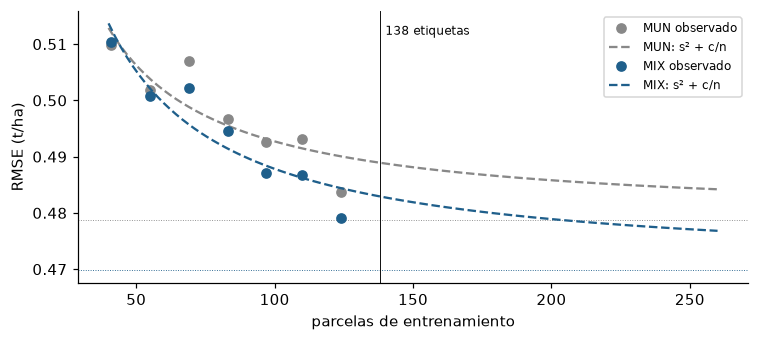

Cifras rápidas de Fortino (11 oct), solo para contraste: MIX con 124 → 0.481; extrapolado a ~220 → 0.474; techo ≈0.465.


In [13]:
rng = np.random.default_rng(20261016)
filas = []
for frac in [0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9]:
    n = int(round(frac * len(ETIQUETADAS)))
    for _ in range(200):
        tr = np.sort(rng.choice(ETIQUETADAS, n, replace=False))
        va = np.setdiff1d(ETIQUETADAS, tr)
        a = T.loc[tr, ["Municipio", "x_m", "y_m"]].assign(**{Y: y.loc[tr].to_numpy()}).reset_index()
        p = referencias(a, T.loc[va, ["Municipio", "x_m", "y_m"]].reset_index())
        vis = T.loc[va, "Municipio"].isin(set(T.loc[tr, "Municipio"])).to_numpy()
        for m in ["MUN", "MIX"]:
            e = (p[m] - y.loc[va].to_numpy())[vis]
            filas.append({"modelo": m, "n": n, "sse": (e ** 2).sum(), "k": len(e)})
curva = pd.DataFrame(filas).groupby(["modelo", "n"]).sum()
curva["RMSE"] = np.sqrt(curva.sse / curva.k)
ajuste = {}
for m in ["MUN", "MIX"]:
    q = curva.loc[m]
    s2, c = np.linalg.lstsq(np.column_stack([np.ones(len(q)), 1 / q.index.to_numpy()]), (q.RMSE ** 2).to_numpy(), rcond=None)[0]
    ajuste[m] = {"RMSE con 124 (observado)": q.RMSE.loc[124], "con 138": np.sqrt(s2 + c / 138), "con 197": np.sqrt(s2 + c / 197),
                 "con 220": np.sqrt(s2 + c / 220), "techo s": np.sqrt(s2), "s2": s2, "c": c}
ajuste = pd.DataFrame(ajuste).T
display(curva.RMSE.unstack("modelo").round(4).T)
display(ajuste.drop(columns=["s2", "c"]).round(4))
fig, ax = plt.subplots(figsize=(7, 3.2))
nn = np.linspace(40, 260, 100)
for m, col in [("MUN", "#888888"), ("MIX", "#1f5f8b")]:
    q = curva.loc[m]
    ax.plot(q.index, q.RMSE, "o", color=col, label=f"{m} observado")
    ax.plot(nn, np.sqrt(ajuste.loc[m, "s2"] + ajuste.loc[m, "c"] / nn), "--", color=col, label=f"{m}: s² + c/n")
    ax.axhline(ajuste.loc[m, "techo s"], color=col, lw=0.6, ls=":")
ax.axvline(138, color="k", lw=0.6); ax.text(140, ax.get_ylim()[1] * 0.995, "138 etiquetas", va="top", fontsize=8)
ax.set_xlabel("parcelas de entrenamiento"); ax.set_ylabel("RMSE (t/ha)"); ax.legend(fontsize=8); plt.tight_layout(); plt.show()
mx = ajuste.loc["MIX"]
assert 0.44 < mx["techo s"] < mx["RMSE con 124 (observado)"] < 0.50 and mx["RMSE con 124 (observado)"] - mx["con 220"] < 0.01
print("Cifras rápidas de Fortino (11 oct), solo para contraste: MIX con 124 → 0.481; extrapolado a ~220 → 0.474; techo ≈0.465.")

**Resultado.** La curva es casi plana: pasar de 124 a ~220 parcelas mejoraría MIX en menos de 0.01 t/ha, y el techo estimado (*s*) queda en ≈0.47. Las cifras difieren algo de las que Fortino calculó rápidamente el 11 de octubre (0.481 → 0.474, techo 0.465) por el sorteo y el ajuste, pero la conclusión es la misma: **más parcelas del mismo tipo no resuelven el problema; haría falta información distinta** (sección 9).

### 4.4 ¿Qué RMSE puede salir en las 59? Simulación

**Pregunta.** Si el error esperado es ≈0.48, ¿cuánto puede variar en un conjunto concreto de 59 parcelas? ¿Con qué frecuencia E_JK supera a MIX y a MUN?

**Comprobación.**

* Para cada parcela etiquetada, tomamos su error cuadrático OOF medio por modelo (EXP_11, ambos juegos, FULL138).
* Simulamos 10,000 conjuntos con la **composición municipal de las 59 ocultas**: 29 Chignahuapan, 14 Calpulalpan, 7 Singuilucan, 4 Almoloya, 4 Cuautepec y 1 Nanacamilpa.
* Cada conjunto se obtiene por bootstrap dentro de cada municipio (semilla 20261017).

,MUN,MIX,J,K,E_JK
percentil 2.5,0.389,0.378,0.339,0.371,0.346
mediana,0.507,0.489,0.465,0.482,0.466
percentil 97.5,0.665,0.637,0.629,0.639,0.629


P(E_JK < MIX) = 0.987   P(E_JK < MUN) = 0.994


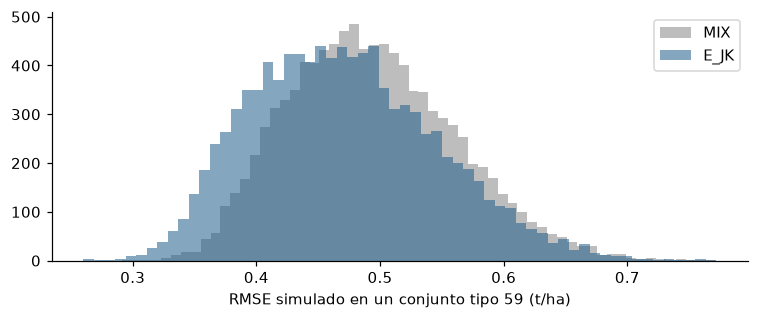

In [14]:
err = w.assign(**{m: (w[m] - w.observado) ** 2 for m in MODELOS}).groupby(ID)[MODELOS].mean()
err["Municipio"] = T.loc[err.index, "Municipio"]
comp59 = T.loc[OCULTAS, "Municipio"].value_counts()
pools = {mu: err[err.Municipio.eq(mu)][MODELOS].to_numpy() for mu in comp59.index}
rng = np.random.default_rng(20261017)
sims = []
for _ in range(10000):
    s = np.vstack([pools[mu][rng.integers(0, len(pools[mu]), k)] for mu, k in comp59.items()])
    sims.append(np.sqrt(s.mean(0)))
sims = pd.DataFrame(sims, columns=MODELOS)
banda = sims.quantile([0.025, 0.5, 0.975]).rename(index={0.025: "percentil 2.5", 0.5: "mediana", 0.975: "percentil 97.5"})
display(banda.round(3))
P_MIX, P_MUN = float((sims.E_JK < sims.MIX).mean()), float((sims.E_JK < sims.MUN).mean())
print(f"P(E_JK < MIX) = {P_MIX:.3f}   P(E_JK < MUN) = {P_MUN:.3f}")
fig, ax = plt.subplots(figsize=(7, 3))
for m, c in [("MIX", "#888888"), ("E_JK", "#1f5f8b")]:
    ax.hist(sims[m], bins=60, alpha=0.55, color=c, label=m)
ax.set_xlabel("RMSE simulado en un conjunto tipo 59 (t/ha)"); ax.legend(); plt.tight_layout(); plt.show()
BANDA_EJK = (float(banda.loc["percentil 2.5", "E_JK"]), float(banda.loc["percentil 97.5", "E_JK"]))
assert 0.30 < BANDA_EJK[0] < 0.40 and 0.55 < BANDA_EJK[1] < 0.70

**Resultado.**

* La mediana simulada de E_JK es ≈0.47, pero **en un conjunto concreto de 59 parcelas su RMSE puede caer entre ≈0.35 y ≈0.63**, solo por cuáles parcelas quedaron ocultas. La banda es más ancha hacia arriba porque Chignahuapan, la zona más difícil, aporta la mitad de las 59.
* Fortino estimó rápidamente ~0.35–0.60. Esta simulación, más completa, alarga el extremo superior a ≈0.63.

**Límite importante.** La probabilidad de que E_JK supere a MIX (≈0.99) está **sobreestimada**:

* Usa los errores de la misma validación cruzada en la que se eligió E_JK, que tiene sesgo de selección.
* Supone que el error de cada parcela es fijo.

En la caja cerrada, la evidencia más limpia que tenemos, E_JK superó a MIX por solo 0.003 t/ha. La lectura correcta es que **E_JK probablemente no será peor que MIX, pero la diferencia esperada es pequeña**.

## 5. Pruebas finales independientes (Opus)

Fueron dos rondas con **caja cerrada**: 35 de las 138 parcelas apartadas por sorteo estratificado por municipio (semilla 20261011) **antes** de leer rendimientos. Todo se registró y congeló antes de abrirla. Aquí solo se resumen y se comprueban sus cifras guardadas; no se reejecutan. Detalle en [`validacion_independiente/`](../validacion_independiente/README.md) y [`ronda2/`](../validacion_independiente/ronda2/README.md).

### Ronda 1 (11 oct, 14:09–14:14 CDMX): siete familias nuevas

Las familias, nombradas como en los registros de Opus:

| Familia | Receta |
| --- | --- |
| F1 | Modelo jerárquico REML con municipio y celda |
| F2 | F1 + K1 |
| F3 | F2 + proceso gaussiano |
| F4 | ⅓(J+K+F2) |
| F5 | F2 + log(área) |
| F6 | Regresión-kriging de J |
| F7 | ½F6 + ½K |

In [15]:
m1 = csv_insumo("r1_metricas").set_index("modelo").sort_values("RMSE")
display(m1[["RMSE", "MAE", "reps_mejor_que_E_JK", "reps_mejor_que_MIX"]].round(4))
c1 = json_insumo("r1_congelado"); rr1 = json_insumo("r1_caja_res")
print("Reality Check (White, 2000) de F1–F7 frente a E_JK: p =", c1["reality_check"]["E_JK"]["p_valor"], "| frente a MIX: p =", round(c1["reality_check"]["MIX"]["p_valor"], 3))
display(pd.DataFrame(rr1["metricas_caja"]).T[["RMSE", "MAE", "R2"]].sort_values("RMSE").round(4))
print("Procedimiento congelado:", c1["procedimiento_final"], "| condiciones:", rr1["condiciones"], "| decisión:", rr1["decision"])
assert c1["reality_check"]["E_JK"]["p_valor"] == 1.0 and rr1["decision"] == "NO FAVORABLE" and c1["procedimiento_final"] == "F7"

,RMSE,MAE,reps_mejor_que_E_JK,reps_mejor_que_MIX
modelo,,,,
E_JK,0.4750,0.3175,0,10
J,0.4752,0.3194,3,10
F7,0.4785,0.3246,3,10
F4,0.4807,0.3192,0,10
F6,0.4825,0.3339,4,9
K,0.4898,0.3373,0,5
MIX,0.4906,0.3375,0,0
MUN,0.5002,0.3270,0,1
F1,0.5004,0.3362,0,1


Reality Check (White, 2000) de F1–F7 frente a E_JK: p = 1.0 | frente a MIX: p = 0.413


,RMSE,MAE,R2
K,0.4717,0.3656,0.6996
MUN,0.4784,0.3460,0.6910
E_JK,0.4822,0.3666,0.6861
MIX,0.4855,0.3734,0.6817
F7,0.4951,0.3914,0.6690
J,0.5047,0.3954,0.6561


Procedimiento congelado: F7 | condiciones: {'C1_caja_RMSE_menor_que_E_JK_y_MIX': False, 'C2_desarrollo_8de10': False, 'C3_caja_MAE_no_peor_que_MIX': False, 'C4_no_se_invierte_sin_2': False, 'C5_nulo_p_le_0.10': False} | decisión: NO FAVORABLE


**Ronda 1.** Ninguna familia superó a E_JK en la CV (p = 1.0). La elegida, F7, quedó peor que E_JK y que MIX en la caja. **Decisión registrada: NO FAVORABLE.**

### Ronda 2 (11 oct, 22:14–22:18 CDMX): información externa que cambie dentro del municipio

* **Fase A:** inventario de datos públicos a escala de parcela (tabla completa en la sección 9).
* **Fase B:** dos hipótesis registradas a las 22:14, antes de calcularlas:
  * **H1:** posición topográfica (TPI a 1 km con Copernicus DEM de 30 m), como indicador de bolsas de aire frío y heladas.
  * **H2:** carbono orgánico del suelo de 0–30 cm (SoilGrids, 250 m).
* Cada una se probó como corrección penalizada sobre E_JK y sobre MIX.

In [16]:
chx = json_insumo("r2_chequeo")
display(pd.DataFrame({h: {k: chx[h][k] for k in ["variable", "sd_dentro_municipio", "R2_municipio", "R2_celda_CHIRPS", "pasa_regla_no_etiqueta"]} for h in ["H1", "H2"]}).T)
m2 = csv_insumo("r2_metricas").set_index("modelo")
display(m2.loc[["E_JK", "H1_E_JK", "H2_E_JK", "MIX", "H2_MIX", "H1_MIX"], ["RMSE", "MAE", "reps_mejor_que_E_JK", "reps_mejor_que_MIX"]].round(4))
c2, rr2 = json_insumo("r2_congelado"), json_insumo("r2_caja_res")
print("Reality Check con 11 familias (F1–F7 + 4 nuevas) frente a E_JK: p =", c2["reality_check"]["E_JK"]["p_valor"])
display(pd.DataFrame(rr2["metricas_caja"]).T[["RMSE", "MAE"]].loc[["E_JK", "H1_E_JK", "MIX", "H1_MIX"]].round(5))
print("Congelado:", c2["procedimiento_final"], "| condiciones:", rr2["condiciones"], "| decisión mecánica:", rr2["decision"])
assert c2["reality_check"]["E_JK"]["p_valor"] == 1.0 and rr2["decision"] == "PARCIAL" and len(c2["reality_check"]["E_JK"]["modelos"]) == 11
assert rr2["metricas_caja"]["H1_E_JK"]["RMSE"] > rr2["metricas_caja"]["E_JK"]["RMSE"] and rr2["congelados_identicos_a_ronda1_dif_max"] == 0.0

,variable,sd_dentro_municipio,R2_municipio,R2_celda_CHIRPS,pasa_regla_no_etiqueta
H1,tpi_1km_m,12.667272,0.375467,0.468492,True
H2,soc_0_30_dgkg,21.798534,0.520796,0.599708,True


,RMSE,MAE,reps_mejor_que_E_JK,reps_mejor_que_MIX
modelo,,,,
E_JK,0.4871,0.3252,0,10
H1_E_JK,0.4887,0.3275,2,10
H2_E_JK,0.4897,0.3264,2,10
MIX,0.5043,0.3452,0,0
H2_MIX,0.5059,0.3451,0,2
H1_MIX,0.5069,0.3481,0,0


Reality Check con 11 familias (F1–F7 + 4 nuevas) frente a E_JK: p = 1.0


,RMSE,MAE
E_JK,0.48217,0.36665
H1_E_JK,0.48277,0.36754
MIX,0.48554,0.37337
H1_MIX,0.48469,0.37259


Congelado: H1_E_JK | condiciones: {'C1': False, 'C2': False, 'C3': True, 'C4': False, 'C5': False} | decisión mecánica: PARCIAL


**Ronda 2.** Ambas variables varían dentro del municipio: la celda CHIRPS explica solo 47 % y 60 % de ellas, así que no son una simple etiqueta de lugar. Pero **ninguna mejora a su base**:

* E_JK + TPI empeora a E_JK en la CV (2 de 10 repeticiones mejores) y en la caja (0.48277 frente a 0.48217).
* La pendiente estimada es ≈0.

La regla mecánica da **PARCIAL** solo porque cumple MAE ≤ MIX, algo que E_JK ya lograba. **En sustancia, el resultado es nulo.**

## 6. La decisión

**Regla fijada de antemano** por Fortino, a las 22:05 (CDMX) del 11 de octubre, antes de conocer la ronda 2:

> Si la ronda 2 sale FAVORABLE según su criterio registrado, se reabre la elección. Si sale PARCIAL o NO FAVORABLE, **E_JK queda sin cambios**, con MIX como referencia.

**Comprobación.** Leemos el extracto registrado de la decisión y las horas de la ronda 2, verificamos el orden y aplicamos la regla.

In [17]:
from zoneinfo import ZoneInfo
cdmx = ZoneInfo("America/Mexico_City")
extracto = texto_insumo("decision_fortino")
assert "(11 oct 2026, 22:05 CDMX)" in extracto and "Modelo de entrega: E_JK" in extracto and "Si sale PARCIAL o NO FAVORABLE, E_JK queda sin cambios" in extracto
reg2 = json_insumo("r2_registro")
horas = pd.DataFrame([
    {"evento": "Decisión y regla de Fortino", "hora CDMX": "2026-10-11 22:05", "fuente": "docs/comprension_fortino_8oct.md"},
    {"evento": "Hipótesis de la ronda 2 registradas", "hora CDMX": datetime.fromisoformat(reg2["registrado_cdmx"]).strftime("%Y-%m-%d %H:%M:%S"), "fuente": "ronda2/registro_previo.json"},
    {"evento": "Ronda 2 congelada (antes de abrir la caja)", "hora CDMX": datetime.fromisoformat(c2["congelado_utc"]).astimezone(cdmx).strftime("%Y-%m-%d %H:%M:%S"), "fuente": "ronda2/congelado.json"},
    {"evento": "Resultado de la ronda 2 (caja, segundo uso)", "hora CDMX": datetime.fromisoformat(rr2["apertura_utc"]).astimezone(cdmx).strftime("%Y-%m-%d %H:%M:%S"), "fuente": "ronda2/resultados_caja/resultado.json"},
])
display(horas)
assert list(horas["hora CDMX"]) == sorted(horas["hora CDMX"])
MODELO_FINAL = "E_JK" if rr2["decision"] != "FAVORABLE" else None
assert MODELO_FINAL == "E_JK"
# Razones verificables
gana_mix = bool((rm["E_JK − MIX"] < 0).all())
cota = all(rm.loc[ev, "E_JK"] <= (rm.loc[ev, "J"] + rm.loc[ev, "K"]) / 2 + 1e-12 for ev in rm.index)
k_mix = bool((rm.K < rm.MIX).all())
assert gana_mix and cota and k_mix
display((rm[["J", "K", "E_JK"]].sub(rm.MIX, axis=0)).rename(columns=lambda c: f"{c} − MIX").round(4))
print(f"Ronda 2: {rr2['decision']} → la regla mantiene {MODELO_FINAL}. E_JK < MIX en las {len(rm)} evaluaciones: {gana_mix}. "
      f"RMSE(E_JK) ≤ promedio de RMSE(J) y RMSE(K) en todas: {cota}.")

,evento,hora CDMX,fuente
0,Decisión y regla de Fortino,2026-10-11 22:05,docs/comprension_fortino_8oct.md
1,Hipótesis de la ronda 2 registradas,2026-10-11 22:14:06,ronda2/registro_previo.json
2,Ronda 2 congelada (antes de abrir la caja),2026-10-11 22:17:44,ronda2/congelado.json
3,"Resultado de la ronda 2 (caja, segundo uso)",2026-10-11 22:18:02,ronda2/resultados_caja/resultado.json


modelo,J − MIX,K − MIX,E_JK − MIX
evaluación,,,
"1 CV histórica (138, SEEN)",-0.0037,-0.0052,-0.0115
"2 CV nueva (138, SEEN)",-0.0035,-0.0047,-0.0113
3 CV desarrollo Opus R1 (103),-0.0154,-0.0008,-0.0155
4 CV desarrollo Opus R2 (103),-0.0204,-0.0001,-0.0172
5 Caja cerrada (35),0.0191,-0.0138,-0.0034


Ronda 2: PARCIAL → la regla mantiene E_JK. E_JK < MIX en las 5 evaluaciones: True. RMSE(E_JK) ≤ promedio de RMSE(J) y RMSE(K) en todas: True.


**Por qué E_JK:**

1. **Supera a MIX en las cinco evaluaciones** (sección 3), con márgenes de 0.003 a 0.017 t/ha. K también queda por debajo de MIX en las cinco, pero con márgenes de 0.0001 a 0.014: en las dos CV de Opus prácticamente empata. J pierde contra MIX en la caja.
2. **Promediar con igual peso acota el error.** Por la desigualdad del triángulo, el RMSE del promedio nunca supera el promedio de los RMSE de J y K, así que E_JK no puede caer al nivel del peor de los dos. Como no sabemos cuál de los dos será mejor en las 59 (en la caja invirtieron su orden), esta es la elección prudente. Además, pesos estimados suelen rendir peor que pesos iguales (Claeskens et al., 2016).
3. **La regla se fijó antes del último resultado**, así que la decisión no se ajustó a él. La hora 22:05 es la que Fortino declaró en su documento; no tiene un sello externo. Las horas de la ronda 2 sí quedaron en los registros JSON.

**Cómo se reporta:**

* RMSE esperado **≈0.47–0.49 t/ha** (rango de las CV y la caja), no el 0.4757 de la CV histórica.
* En las 59 concretas, banda **≈0.35–0.63** (sección 4.4).
* Origen post-hoc de E_JK declarado.
* MIX como referencia.

## 7. Ajuste final y las 59 predicciones

**Pregunta.** ¿Qué predice E_JK para las 59 parcelas, cuánto cambia frente a MIX y con qué incertidumbre?

**Comprobación.** Entrenamos los cinco candidatos con las **138** etiquetas:

* Para los residuos internos de K usamos 4 pliegues con la semilla declarada **20261015**, no usada antes.
* Registramos qué variable eligió J.
* La sensibilidad de β a otras semillas se muestra solo como información; no se elige nada con ella.

In [18]:
SEMILLA_FINAL = 20261015
PRED, INFO = candidatos(ETIQUETADAS, OCULTAS, internas(ETIQUETADAS, SEMILLA_FINAL))
PRED = pd.DataFrame(PRED, index=pd.Index(OCULTAS, name=ID))
print(f"K: β = {INFO['K']['beta']:+.4f} t/ha por desviación de K1 (mediana {INFO['K']['mediana']:.2f}, desviación {INFO['K']['escala']:.2f}, {INFO['K']['n_ajuste']} parcelas con K1)")
print(f"J: variable elegida = {INFO['J_variable']}")
display(pd.Series(INFO["J_coef"], name="coeficiente J").to_frame().round(4))
sens = pd.Series({s: candidatos(ETIQUETADAS, OCULTAS, internas(ETIQUETADAS, s))[1]["K"]["beta"] for s in [SEMILLA_FINAL, 1, 2, 3, 4, 5]}, name="β")
print("β con otras semillas internas (informativo):", sens.round(4).to_dict())
assert INFO["J_variable"] == "anom_precip_pct_d" and INFO["K"]["beta"] < 0 and sens.std() < 0.01

K: β = -0.0944 t/ha por desviación de K1 (mediana 0.37, desviación 9.03, 108 parcelas con K1)
J: variable elegida = anom_precip_pct_d


,coeficiente J
Almoloya,3.7210
Chignahuapan,3.1795
Otros_Hidalgo,3.2434
Singuilucan,1.1707
Tlaxcala,2.8603
pendiente,0.0168


β con otras semillas internas (informativo): {20261015: -0.0944, 1: -0.0907, 2: -0.0893, 3: -0.0858, 4: -0.0939, 5: -0.093}


* **β < 0**, igual que en las 50 particiones de EXP_08: una parcela más verde y más temprana que sus vecinas rinde **menos** de lo que predice su territorio.
* β apenas cambia con la semilla (entre −0.086 y −0.094), así que la elección de la semilla interna no importa.
* J eligió, como en casi todos los pliegues, la **anomalía de lluvia de octubre (% del histórico)**.

### 7.1 Intervalos de predicción

**Receta:**

* Cuantiles empíricos de los residuos OOF de E_JK (observado − predicho), por zona: Chignahuapan contra el resto. Se usan ambos juegos de EXP_11, SEEN.
* Niveles nominales: **80 %** (cuantiles 10–90) y **90 %** (cuantiles 5–95).

**Cobertura empírica**, comprobada en tres pruebas:

* cuantiles de las particiones históricas aplicados a las nuevas, y al revés (mismas etiquetas, no independiente);
* cuantiles de la CV de desarrollo de Opus (103 parcelas) aplicados a la **caja de 35**.

In [19]:
def zona(m):
    return np.where(np.asarray(m) == "Chignahuapan", "Chignahuapan", "resto")

NIVELES = {"80 %": (0.10, 0.90), "90 %": (0.05, 0.95)}
def cuantiles(df):
    return {(z, n): tuple(np.quantile(g.res, q)) for z, g in df.groupby("zona") for n, q in NIVELES.items()}
def cobertura(df, Q):
    return {n: float(np.mean([Q[(z, n)][0] <= r <= Q[(z, n)][1] for z, r in zip(df.zona, df.res)])) for n in NIVELES}

S = w[w.municipio_visto].assign(res=lambda d: d.observado - d.E_JK, zona=lambda d: zona(d.Municipio))
d1 = r1[r1.modelo.eq("E_JK") & r1.municipio_visto].assign(res=lambda d: d.observado - d.predicho, zona=lambda d: zona(d.Municipio))
cj = caja_guardada.assign(res=lambda d: d.observado - d.E_JK, zona=lambda d: zona(d.Municipio))
COB = pd.DataFrame({
    "históricas → nuevas": cobertura(S[S.conjunto.eq("nuevas")], cuantiles(S[S.conjunto.eq("historicas")])),
    "nuevas → históricas": cobertura(S[S.conjunto.eq("historicas")], cuantiles(S[S.conjunto.eq("nuevas")])),
    "CV Opus (103) → caja (35)": cobertura(cj, cuantiles(d1)),
}).T
display(COB.round(3))
Q = cuantiles(S)
display(pd.DataFrame(Q, index=["inferior", "superior"]).T.round(3))
assert all(abs(COB.iloc[i, 0] - 0.80) < 0.02 and abs(COB.iloc[i, 1] - 0.90) < 0.02 for i in range(2))

,80 %,90 %
históricas → nuevas,0.796,0.901
nuevas → históricas,0.805,0.898
CV Opus (103) → caja (35),0.714,0.857


inferior  superior
Chignahuapan 80 %    -0.620     0.622
             90 %    -0.997     0.860
resto        80 %    -0.499     0.480
             90 %    -0.580     0.568

**Resultado.**

* Entre juegos de particiones, la cobertura coincide con la nominal (≈0.80 y ≈0.90), pero esa prueba no es independiente.
* En la caja, con 35 parcelas, cubre **0.71 y 0.86**: algo menos que lo nominal.
* Los intervalos son **aproximados**, por tres razones:
  * los residuos vienen de modelos entrenados con ~110 parcelas, no con 138;
  * suponen que las 59 se parecen a las etiquetadas de su zona;
  * no cubren un cambio de campaña.
* En Chignahuapan el intervalo es más ancho: ±0.62 t/ha al 80 %, frente a ±0.49 en el resto.

### 7.2 Tabla de las 59

,Municipio,MUN,MIX,J,K,E_JK,E_JK − MIX,zona,inferior 80 %,superior 80 %,inferior 90 %,superior 90 %,sin K1 (K = MIX),celda CHIRPS sin etiquetas
ID_POLIGONO,,,,,,,,,,,,,,
AGC_003,Singuilucan,3.081,3.353,3.008,3.413,3.210,-0.143,resto,2.712,3.690,2.630,3.778,False,False
AGC_011,Chignahuapan,4.477,4.607,4.641,4.581,4.611,0.004,Chignahuapan,3.991,5.233,3.614,5.471,False,False
AGC_016,Chignahuapan,4.477,4.527,4.348,4.487,4.417,-0.110,Chignahuapan,3.798,5.039,3.420,5.277,False,False
AGC_025,Calpulalpan,3.000,2.964,3.015,2.985,3.000,0.036,resto,2.501,3.480,2.420,3.568,False,False
AGC_027,Calpulalpan,3.000,2.975,3.015,2.972,2.993,0.019,resto,2.495,3.473,2.413,3.561,False,False
AGC_028,Chignahuapan,4.477,4.518,4.348,4.617,4.482,-0.035,Chignahuapan,3.863,5.104,3.485,5.342,False,False
AGC_029,Calpulalpan,3.000,3.085,2.939,3.139,3.039,-0.046,resto,2.540,3.519,2.459,3.607,False,False
AGC_030,Singuilucan,3.081,3.100,3.211,3.179,3.195,0.095,resto,2.696,3.675,2.615,3.762,False,False
AGC_031,Chignahuapan,4.477,4.184,4.348,4.135,4.241,0.057,Chignahuapan,3.622,4.863,3.244,5.101,False,False


|E_JK − MIX|: media 0.062 t/ha, máximo 0.195 (AGC_129); 12 de 59 difieren más de 0.10 t/ha


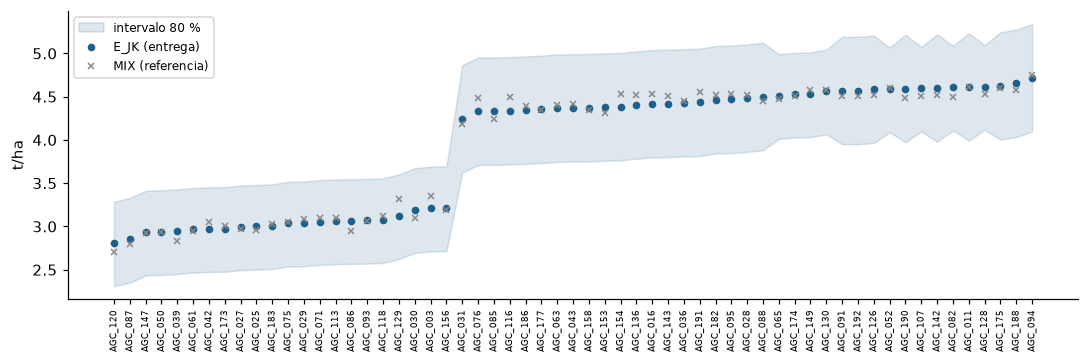

In [20]:
DET = PRED.copy()
DET.insert(0, "Municipio", T.loc[OCULTAS, "Municipio"].to_numpy())
DET["E_JK − MIX"] = DET.E_JK - DET.MIX
DET["zona"] = zona(DET.Municipio)
for n in NIVELES:
    DET[f"inferior {n}"] = DET.E_JK + [Q[(z, n)][0] for z in DET.zona]
    DET[f"superior {n}"] = DET.E_JK + [Q[(z, n)][1] for z in DET.zona]
DET["sin K1 (K = MIX)"] = ~np.isfinite(T.loc[OCULTAS, "K1_corregido"].to_numpy())
celdas_lab = set(T.loc[ETIQUETADAS, "celda"])
DET["celda CHIRPS sin etiquetas"] = ~T.loc[OCULTAS, "celda"].isin(celdas_lab).to_numpy()
pd.set_option("display.max_rows", 80)
display(DET.round(3))
dif = DET["E_JK − MIX"]
print(f"|E_JK − MIX|: media {dif.abs().mean():.3f} t/ha, máximo {dif.abs().max():.3f} ({dif.abs().idxmax()}); "
      f"{int((dif.abs() > 0.10).sum())} de 59 difieren más de 0.10 t/ha")
fig, ax = plt.subplots(figsize=(10, 3.4))
o = DET.sort_values("E_JK")
xs = np.arange(len(o))
ax.fill_between(xs, o["inferior 80 %"], o["superior 80 %"], color="#1f5f8b", alpha=0.15, label="intervalo 80 %")
ax.plot(xs, o.E_JK, "o", color="#1f5f8b", ms=4, label="E_JK (entrega)")
ax.plot(xs, o.MIX, "x", color="#888888", ms=4, label="MIX (referencia)")
ax.set_xticks(xs, o.index, rotation=90, fontsize=6); ax.set_ylabel("t/ha"); ax.legend(fontsize=8); plt.tight_layout(); plt.show()

**Lectura.** E_JK y MIX difieren en promedio 0.06 t/ha y como máximo 0.20 (AGC_129); solo 12 de las 59 cambian más de 0.10. La elección del modelo mueve la entrega mucho menos que la incertidumbre de cada predicción (±0.5–0.6 t/ha al 80 %).

### 7.3 Casos especiales

In [21]:
xy_lab = T.loc[ETIQUETADAS, ["x_m", "y_m"]].to_numpy()
d120 = np.linalg.norm(xy_lab - T.loc["AGC_120", ["x_m", "y_m"]].to_numpy(float), axis=1)
caso = {"municipio": T.loc["AGC_120", "Municipio"], "etiquetas en su municipio": int((T.loc[ETIQUETADAS, "Municipio"] == T.loc["AGC_120", "Municipio"]).sum()),
        "K1": T.loc["AGC_120", "K1_corregido"], "vecina etiquetada más cercana": ETIQUETADAS[d120.argmin()], "distancia (km)": round(d120.min() / 1000, 2),
        "etiquetadas en su celda CHIRPS": int((T.loc[ETIQUETADAS, "celda"] == T.loc["AGC_120", "celda"]).sum()), "grupo de J": T.loc["AGC_120", "grupo"]}
print("AGC_120:", caso)
display(DET.loc[["AGC_120"], MODELOS + ["E_JK − MIX"]].round(3))
SIN_K1 = list(DET.index[DET["sin K1 (K = MIX)"]])
SIN_CELDA = list(DET.index[DET["celda CHIRPS sin etiquetas"]])
vj = FX[INFO["J_variable"]]
print("Sin K1 (K cae a MIX):", SIN_K1)
print("En celdas CHIRPS sin parcelas etiquetadas:", SIN_CELDA, "| valor de la variable de J:", vj.loc[SIN_CELDA].round(2).tolist(),
      f"| rango en las etiquetadas: {vj.loc[ETIQUETADAS].min():.2f}–{vj.loc[ETIQUETADAS].max():.2f}")
assert caso["etiquetas en su municipio"] == 1 and not np.isfinite(caso["K1"]) and caso["distancia (km)"] == 1.26
assert len(SIN_K1) == 9 and np.allclose(DET.loc[SIN_K1, "K"], DET.loc[SIN_K1, "MIX"]) and len(SIN_CELDA) == 2
assert vj.loc[SIN_CELDA].between(vj.loc[ETIQUETADAS].min(), vj.loc[ETIQUETADAS].max()).all()

AGC_120: {'municipio': 'Nanacamilpa de Mariano Arista', 'etiquetas en su municipio': 1, 'K1': np.float64(nan), 'vecina etiquetada más cercana': np.str_('AGC_054'), 'distancia (km)': np.float64(1.26), 'etiquetadas en su celda CHIRPS': 1, 'grupo de J': 'Tlaxcala'}


,MUN,MIX,J,K,E_JK,E_JK − MIX
ID_POLIGONO,,,,,,
AGC_120,2.5,2.708,2.906,2.708,2.807,0.099


Sin K1 (K cae a MIX): ['AGC_061', 'AGC_065', 'AGC_087', 'AGC_118', 'AGC_120', 'AGC_147', 'AGC_173', 'AGC_174', 'AGC_183']
En celdas CHIRPS sin parcelas etiquetadas: ['AGC_147', 'AGC_174'] | valor de la variable de J: [4.77, 76.85] | rango en las etiquetadas: 2.72–121.19


* **AGC_120 (Nanacamilpa)** es el caso más débil de la entrega:
  * MUN usa la única etiqueta de su municipio (AGC_048, 2.5 t/ha);
  * no tiene K1, así que K = MIX;
  * su vecina etiquetada más cercana está a 1.26 km, más allá del alcance donde la vecindad informa (sección 4.2);
  * J usa su grupo regional.

  Los cinco candidatos van de 2.50 a 2.91 t/ha. Su intervalo, tomado del "resto", **probablemente subestima** la incertidumbre.
* **9 parcelas sin K1** (sin capturas Planet suficientes o sin ≥2 vecinas): K = MIX exactamente, y E_JK = ½J + ½MIX.
* **2 parcelas en celdas CHIRPS sin etiquetas** (AGC_147, AGC_174): la variable de J está dentro del rango observado, así que no hay extrapolación. Aun así, el valor de esa celda nunca se contrastó con un rendimiento.

### 7.4 Controles de la entrega

In [22]:
assert list(PRED.index) == list(OCULTAS) and PRED.index.is_unique and len(PRED) == 59
assert set(PRED.index) == set(meta.loc[meta.CONJUNTO.eq("PREDICCION"), ID])
assert np.isfinite(PRED.to_numpy()).all()
assert PRED.E_JK.between(y.min(), y.max()).all()
R2_, I2_ = candidatos(ETIQUETADAS, OCULTAS, internas(ETIQUETADAS, SEMILLA_FINAL))
assert all(np.array_equal(R2_[m], PRED[m].to_numpy()) for m in MODELOS)
# Fuga: (a) ninguna etiqueta de las 59 existe; (b) va nunca recibe rendimientos (assert en referencias);
# (c) si cambiamos las X de las otras ocultas, la selección de J y su coeficiente no cambian (solo usan el entrenamiento).
FX_orig = FX.copy()
FX.loc[OCULTAS] = FX.loc[OCULTAS] * 0 + 999.0
_, I3_ = candidatos(ETIQUETADAS, OCULTAS[:1], internas(ETIQUETADAS, SEMILLA_FINAL))
FX = FX_orig
assert I3_["J_variable"] == INFO["J_variable"] and I3_["J_coef"] == INFO["J_coef"] and I3_["K"] == INFO["K"]
# (d) control positivo: cambiar una etiqueta de entrenamiento sí cambia las predicciones (los controles anteriores no son triviales).
y_alt = y.copy(); y_alt.iloc[0] += 1.0
alt, _ = candidatos(ETIQUETADAS, OCULTAS, internas(ETIQUETADAS, SEMILLA_FINAL), etiquetas_y=y_alt)
assert not np.array_equal(alt["MIX"], PRED.MIX.to_numpy())
print(f"59 IDs únicos = lista PREDICCION; sin NaN; rango {PRED.E_JK.min():.2f}–{PRED.E_JK.max():.2f} dentro de lo observado ({y.min():.2f}–{y.max():.2f}); "
      "réplica idéntica; selección de J y β independientes de las X de las ocultas; el modelo sí responde a las etiquetas de entrenamiento.")

59 IDs únicos = lista PREDICCION; sin NaN; rango 2.81–4.72 dentro de lo observado (2.00–5.59); réplica idéntica; selección de J y β independientes de las X de las ocultas; el modelo sí responde a las etiquetas de entrenamiento.


In [23]:
from pathlib import Path
RAIZ = next((p for p in [Path.cwd(), Path.cwd().parent] if (p / "pyproject.toml").exists() and (p / "notebooks").exists()), Path.cwd())
SAL = RAIZ / "resultados/04_seleccion_modelo_final"
SAL.mkdir(parents=True, exist_ok=True)
salidas = {
    "predicciones_59.csv": PRED[["E_JK"]].rename(columns={"E_JK": Y}).to_csv(float_format="%.4f"),
    "intervalos_59.csv": DET[["Municipio", "zona", "E_JK", "inferior 80 %", "superior 80 %", "inferior 90 %", "superior 90 %"]]
        .rename(columns={"E_JK": "prediccion_t_ha", "inferior 80 %": "inferior_80", "superior 80 %": "superior_80", "inferior 90 %": "inferior_90", "superior 90 %": "superior_90"})
        .to_csv(float_format="%.4f"),
    "detalle_59.csv": DET.to_csv(float_format="%.17g"),
}
salidas["resumen.json"] = json.dumps({
    "modelo_entrega": "E_JK = 0.5*J + 0.5*K", "referencia": "MIX", "semilla_interna_K": SEMILLA_FINAL,
    "K": INFO["K"], "J_variable": INFO["J_variable"], "J_coeficientes": INFO["J_coef"],
    "cuantiles_residuos": {f"{z}|{n}": list(v) for (z, n), v in Q.items()}, "cobertura": COB.to_dict(orient="index"),
    "sin_K1": SIN_K1, "celdas_sin_etiquetas": SIN_CELDA, "caso_AGC_120": {k: (None if isinstance(v, float) and not np.isfinite(v) else v) for k, v in caso.items()},
    "sha256": {k: hashlib.sha256(v.encode()).hexdigest() for k, v in salidas.items()},
}, indent=2, ensure_ascii=False, default=float) + "\n"
for nombre, contenido in salidas.items():
    p = SAL / nombre
    if p.exists():
        assert p.read_text(encoding="utf-8") == contenido, f"{p} ya existe con otro contenido: no se sobrescribe"
        estado = "idéntico al existente"
    else:
        p.write_text(contenido, encoding="utf-8")
        estado = "escrito"
    print(f"{nombre}: {estado} (sha256 {hashlib.sha256(contenido.encode()).hexdigest()[:16]}…)")
print("Carpeta:", SAL)

predicciones_59.csv: idéntico al existente (sha256 1de902406da3d6ba…)
intervalos_59.csv: idéntico al existente (sha256 e78cd374c16b8f87…)
detalle_59.csv: idéntico al existente (sha256 b6eddb16192adfc6…)
resumen.json: idéntico al existente (sha256 fe6d9711dca72206…)
Carpeta: /home/netfoor/Documents/ObsidianVault/agrocebada/agrocebada-uv/resultados/04_seleccion_modelo_final


Las bases del reto no fijan un formato para el archivo de predicciones; lo revisamos en los documentos *Introducción al Reto* y *Descripción general y parcelas*. Por eso `predicciones_59.csv` usa las mismas columnas que el archivo original de etiquetas: `ID_POLIGONO` y `RENDIMIENTO_T_HA`. Los intervalos van aparte, en `intervalos_59.csv`.

Si los archivos ya existen, el notebook **no los sobrescribe**: verifica que sean idénticos. Así, una segunda ejecución en un kernel limpio comprueba el determinismo de la entrega. **Ningún archivo se envía a ningún lado.**

## 8. Preguntas guía de las bases

Las importancias de variables de un modelo sin control territorial son engañosas aquí: cualquier variable que cambie entre regiones parece "importante" porque sustituye al municipio. Por eso respondemos con evidencia que **controla el territorio**.

### 8.1 ¿Cuál es el índice más importante?

**Respuesta.** El **NDVI de Planet**, pero no su valor absoluto, sino su **integral de temporada comparada con la de las parcelas vecinas a menos de 1 km** (K1). Es el único índice que mostró señal *dentro* del municipio. Su efecto es pequeño y no siempre se repite: lo que añade K a MIX en cada evaluación es:

In [24]:
aporte_k = (rm.K - rm.MIX).rename("K − MIX (t/ha)").to_frame()
aporte_k["mejora relativa"] = (1 - rm.K / rm.MIX).map("{:.1%}".format)
display(aporte_k.round(4))
assert (rm.K <= rm.MIX + 1e-12).all()

,K − MIX (t/ha),mejora relativa
evaluación,,
"1 CV histórica (138, SEEN)",-0.0052,1.1%
"2 CV nueva (138, SEEN)",-0.0047,1.0%
3 CV desarrollo Opus R1 (103),-0.0008,0.2%
4 CV desarrollo Opus R2 (103),-0.0001,0.0%
5 Caja cerrada (35),-0.0138,2.8%


El aporte va de ≈0 % (CV de Opus R2) a 2.8 % (caja). El signo es negativo: más verde y más temprana que sus vecinas → menos rendimiento que su territorio. Una explicación plausible, no demostrada, es que siembras o desarrollos más tempranos quedan más expuestos a heladas o déficit en el llenado.

### 8.2 ¿Qué variable climática tiene mayor peso?

**Respuesta.** La que elige J en 97 de 100 pliegues y en el ajuste final: la **anomalía de lluvia de octubre** (`anom_precip_pct_d`), con +0.017 t/ha por punto porcentual. Pero **funciona como ubicación, no como clima**.

In [25]:
je = csv_insumo("j_elegidas")
display(je.groupby(["conjunto", "variable"]).size().rename("pliegues (de 50)").to_frame())
g = T.assign(v=FX["anom_precip_pct_d"])
r2_por = {k: float(1 - ((g.v - g.groupby(k).v.transform("mean")) ** 2).sum() / ((g.v - g.v.mean()) ** 2).sum()) for k in ["celda", "Municipio", "grupo"]}
print("R² de anom_precip_pct_d explicado por:", {k: round(v, 4) for k, v in r2_por.items()}, "| celdas distintas:", T.celda.nunique())
assert r2_por["celda"] >= 0.99

pliegues (de 50)
conjunto   variable                             
historicas anom_precip_pct_d                  48
           satc_ndvi_s2_m04                    1
           satc_ndvi_s2_m05                    1
nuevas     anom_precip_pct_d                  49
           sat_ndti_std_s2_pre                 1

R² de anom_precip_pct_d explicado por: {'celda': 0.9991, 'Municipio': 0.9567, 'grupo': 0.9039} | celdas distintas: 25


La celda CHIRPS de ≈5 km explica **más del 99.9 %** de su variación. Dentro de una celda, todas las parcelas tienen prácticamente el mismo valor. J la usa para distinguir zonas dentro de su grupo regional; no mide la lluvia que recibió cada parcela. **No puede interpretarse como "la lluvia de octubre causa el rendimiento".**

### 8.3 ¿Cuál es la mejor combinación de variables?

**Respuesta.** Ubicación (municipio + vecinas) + contraste NDVI con las vecinas + nivel regional con la anomalía de lluvia, en un promedio de dos modelos. El aporte incremental, con cifras ya calculadas (CV, SEEN135):

In [26]:
gl = csv_insumo("oof_global_hist")
gl = gl[gl.modelo.eq("Media global")].merge(w[w.conjunto.eq("historicas")][["repeticion", "pliegue", ID, "municipio_visto"]], on=["repeticion", "pliegue", ID], validate="1:1")
glob = gl[gl.municipio_visto]
inc = pd.DataFrame({
    "agrega": ["media global", "+ municipio", "+ vecinas (IDW)", "+ contraste NDVI vecinal", "(J solo: grupo + anomalía de lluvia)", "promedio J y K"],
    "modelo": ["GLOBAL", "MUN", "MIX", "K", "J", "E_JK"],
    "RMSE históricas": [metricas(glob.observado, glob.predicho)["RMSE"]] + [rm.loc["1 CV histórica (138, SEEN)", m] for m in ["MUN", "MIX", "K", "J", "E_JK"]],
    "RMSE nuevas": [np.nan] + [rm.loc["2 CV nueva (138, SEEN)", m] for m in ["MUN", "MIX", "K", "J", "E_JK"]],
}).set_index("modelo")
display(inc.round(4))
assert len(glob) == 1350 and inc.loc["GLOBAL", "RMSE históricas"] > 0.8

,agrega,RMSE históricas,RMSE nuevas
modelo,,,
GLOBAL,media global,0.8497,NaN
MUN,+ municipio,0.4934,0.4922
MIX,+ vecinas (IDW),0.4872,0.4857
K,+ contraste NDVI vecinal,0.4820,0.4810
J,(J solo: grupo + anomalía de lluvia),0.4835,0.4821
E_JK,promedio J y K,0.4757,0.4744


El salto grande es **GLOBAL → MUN**: saber el municipio reduce el error de ≈0.85 a ≈0.49. Cada paso siguiente aporta del orden de 0.005 t/ha. Ninguna variable satelital, climática o topográfica por sí sola se acercó al aporte del municipio, porque casi toda su variación también es regional.

## 9. ¿Qué necesitaríamos para un mejor modelo?

### 9.1 Datos públicos: qué existe y a qué escala (Fase A de la ronda 2)

| Dato necesario | ¿Existe público? | Escala | Fuente y licencia |
| --- | --- | --- | --- |
| Rendimiento medido por parcela, con método documentado | **No** | — | Solo hay rendimiento municipal estimado ([SIAP, SIACON](https://www.gob.mx/siap/documentos/siacon-ng-161430)) |
| Varias campañas de las mismas parcelas | **No** | — | Solo series municipales (SIAP) |
| Fecha de siembra, variedad, fertilización, densidad, cultivo anterior | **No** por parcela | Regional | Solo recomendaciones técnicas del INIFAP |
| Riego o temporal | Solo consulta web | Polígonos 1:10,000 | [SIAP, Frontera Agrícola](https://www.gob.mx/siap/acciones-y-programas/frontera-agricola). Sin descarga reproducible encontrada; la capa ya no se publica por WFS en IDEGEO |
| Suelo (carbono, textura) | Sí | 250 m (modelado) | [SoilGrids 2.0](https://www.isric.org/explore/soilgrids), CC-BY 4.0 ([Poggio et al., 2021](https://doi.org/10.5194/soil-7-217-2021)). **Probado en la ronda 2 (H2): sin aporte** |
| Suelo, mapa nacional | Sí | 1:250,000 | [INEGI Edafología](https://www.inegi.org.mx/temas/edafologia/). Demasiado grueso para distinguir parcelas |
| Elevación fina (posición topográfica, heladas) | Sí | 30 m y 15 m | [Copernicus DEM GLO-30](https://registry.opendata.aws/copernicus-dem/), licencia libre con atribución; [INEGI CEM 3.0](https://www.inegi.org.mx/app/geo2/elevacionesmex/). **Probado con 30 m (H1): sin aporte** |
| Temperatura diaria (heladas) | Sí | ≈10 km | [ERA5-Land](https://cds.climate.copernicus.eu/datasets/reanalysis-era5-land), 0.1°. Escala de celda, no de parcela |
| Rendimiento municipal por año | Sí | Municipio | SIAP. No varía dentro del municipio. Además, la cifra del mismo año sería casi una fuga de información, y su servidor de cierre no respondió el 11 de octubre |

**Contexto agronómico verificado:**

* El Altiplano (Hidalgo, Puebla, Tlaxcala y Estado de México) concentra el 75 % de la superficie de cebada maltera, sembrada bajo temporal en verano. Para temporal en el Altiplano se recomienda la variedad Esmeralda, y Adabella en ambientes de buena productividad ([González González et al., 2016](https://www.redalyc.org/pdf/2631/263144153014.pdf)).
* Los Valles Altos presentan irregularidad de lluvia y **heladas tempranas** ([Zamora Díaz et al., 2017](https://cienciasagricolas.inifap.gob.mx/index.php/agricolas/article/download/317/547/1917)).
* Una fecha límite de siembra hacia el 30 de julio–5 de agosto apareció en búsquedas, pero **no la verificamos en una fuente primaria**: no se cita.

### 9.2 ¿Es el rendimiento reportado por el productor?

**No está confirmado.** Las bases solo dicen "rendimiento del cultivo al final de cosecha". Hay un indicio: muchas etiquetas son múltiplos exactos de 0.5 t/ha, algo típico de cifras redondeadas de memoria. Este dato **solo se describe; nunca se usó para modelar**.

In [27]:
multiplos = int((np.abs(y * 2 - np.round(y * 2)) < 1e-9).sum())
print(f"{multiplos} de {len(y)} etiquetas son múltiplos exactos de 0.5 t/ha")
assert multiplos == 45

45 de 138 etiquetas son múltiplos exactos de 0.5 t/ha


### 9.3 Párrafo para el reporte

> Con los 138 rendimientos disponibles, la ubicación explica la mayor parte de lo que se puede predecir: el municipio solo explica ≈69 % de la variación. De lo que queda, nuestro mejor modelo recupera ≈7 %. Parcelas a menos de 250 m todavía difieren ≈0.42 t/ha. La curva de aprendizaje es casi plana: más parcelas del mismo tipo bajarían el error menos de 0.01 t/ha.
>
> Probamos 619 variables propias, fuentes satelitales externas (Sentinel-1/2, AlphaEarth), topografía a 30 m y suelo a 250 m. Ninguna mostró señal dentro del municipio, incluso con una muestra apartada antes del análisis. **Lo que limita al modelo no es el algoritmo, sino la información disponible.**
>
> Cuatro datos podrían moverlo:
>
> 1. Rendimiento **medido** con un método documentado, como la cosecha de subparcelas. En otros contextos, el rendimiento reportado por el productor se desvía sistemáticamente del medido (Desiere y Jolliffe, 2018; Gourlay, Kilic y Lobell, 2019), y los rendimientos satelitales explican tanto o más la cosecha completa de la parcela que el reporte del productor o la cosecha de subparcelas (Lobell et al., 2020). No sabemos si las etiquetas del reto son reportadas o medidas.
> 2. **Manejo** por parcela: fecha de siembra, variedad, fertilización y densidad.
> 3. **Muestreo de suelo** por parcela.
> 4. **Varias campañas** de las mismas parcelas.
>
> Ninguno es público en la zona; obtenerlos requeriría colaborar con FIRA o con las organizaciones de productores. Con varias campañas, además, un modelo jerárquico del tipo de Battese, Harter y Fuller (1988) podría combinar el dato municipal con el de parcela de forma estadísticamente fundada.

### 9.4 Estado de verificación de las referencias

Se verificó, el 11 de octubre de 2026, que cada referencia existe y dice lo que se le atribuye:

| Referencia | Qué se le atribuye | Estado |
| --- | --- | --- |
| Lobell, D. B., Azzari, G., Burke, M., Gourlay, S., Jin, Z., Kilic, T. y Murray, S. (2020). Eyes in the sky, boots on the ground: Assessing satellite- and ground-based approaches to crop yield measurement and analysis. *American Journal of Agricultural Economics*, 102(1). [PDF](https://web.stanford.edu/~mburke/papers/lobell_et_al_AJAE_2019.pdf) | En Uganda, los rendimientos satelitales explican tanto o más la cosecha completa de la parcela que el reporte del productor o la cosecha de subparcelas | Verificada (publicada en línea en 2019) |
| Desiere, S. y Jolliffe, D. (2018). Land productivity and plot size: Is measurement error driving the inverse relationship? *Journal of Development Economics*, 130, 84–98. [IDEAS](https://ideas.repec.org/a/eee/deveco/v130y2018icp84-98.html) | En Etiopía, la relación inversa tamaño–productividad aparece con producción reportada y desaparece con cosecha de subparcelas | Verificada |
| Gourlay, S., Kilic, T. y Lobell, D. B. (2019). A new spin on an old debate: Errors in farmer-reported production and their implications for inverse scale-productivity relationship in Uganda. *Journal of Development Economics*, 141. [IDEAS](https://ideas.repec.org/a/eee/deveco/v141y2019ics0304387818306588.html) | Los productores sobreestiman la producción, sobre todo en parcelas pequeñas | Verificada |
| Battese, G. E., Harter, R. M. y Fuller, W. A. (1988). An error-components model for prediction of county crop areas using survey and satellite data. *JASA*, 83(401), 28–36. [RTI](https://www.rti.org/publication/error-components-model-prediction-county-crop-areas-using-survey-satellite-data) | Modelo de errores anidados (unidad dentro de área) que combina encuesta y satélite | Verificada |
| Claeskens, G., Magnus, J. R., Vasnev, A. L. y Wang, W. (2016). The forecast combination puzzle: A simple theoretical explanation. *International Journal of Forecasting*, 32(3), 754–762. [EUR](https://repub.eur.nl/pub/81568) | Estimar los pesos de una combinación añade varianza y sesgo; por eso los pesos iguales suelen ganar | Verificada |
| White, H. (2000). A reality check for data snooping. *Econometrica*, 68(5), 1097–1126. [Econometric Society](https://www.econometricsociety.org/publications/econometrica/2000/09/01/reality-check-data-snooping) | Prueba de si el mejor de muchos modelos supera a un punto de referencia, descontando la búsqueda | Verificada |
| Hansen, P. R. (2005). A test for superior predictive ability. *Journal of Business & Economic Statistics*, 23(4), 365–380. [IDEAS](https://ideas.repec.org/a/bes/jnlbes/v23y2005p365-380.html) | Versión mejorada (SPA) del Reality Check | Verificada |
| Cawley, G. C. y Talbot, N. L. C. (2010). On over-fitting in model selection and subsequent selection bias in performance evaluation. *JMLR*, 11, 2079–2107. [JMLR](https://www.jmlr.org/papers/v11/cawley10a.html) | Seleccionar modelos con la misma validación sesga optimistamente el error reportado | Verificada |
| Varoquaux, G. (2018). Cross-validation failure: Small sample sizes lead to large error bars. *NeuroImage*, 180, 68–77. [arXiv](https://arxiv.org/abs/1706.07581) | Con ~100 casos, las barras de error de la validación cruzada son grandes (≈±10 %) | Verificada |
| Poggio, L. et al. (2021). SoilGrids 2.0. *SOIL*, 7, 217–240. [DOI](https://doi.org/10.5194/soil-7-217-2021) | Fuente y licencia del suelo de la ronda 2 | Verificada (enlace resuelve) |
| González González, M., Zamora Díaz, M. y Solano Hernández, S. (2016). *Revista Mexicana de Ciencias Agrícolas*, 7(1), 159–171. [Redalyc](https://www.redalyc.org/pdf/2631/263144153014.pdf) | Altiplano: 75 % de la superficie de cebada maltera, de temporal; variedades Esmeralda y Adabella | Verificada |
| Zamora Díaz, M. R. et al. (2017). Maravilla: variedad de cebada forrajera para Valles Altos de México. *Revista Mexicana de Ciencias Agrícolas*, 8(6), 1449–1454. [INIFAP](https://cienciasagricolas.inifap.gob.mx/index.php/agricolas/article/download/317/547/1917) | Valles Altos: lluvia irregular y heladas tempranas | Verificada |
| Fecha límite de siembra 30 de julio–5 de agosto | — | **No verificada**: no se cita |

## 10. Límites: lo que esta evidencia no permite afirmar

* **Causalidad.** Ni K1 ni la anomalía de lluvia demuestran un mecanismo. Son asociaciones predictivas en una campaña, y la anomalía de lluvia actúa como etiqueta de lugar.
* **Otras campañas.** Todo es abril–octubre de 2025. Un año con otro régimen de lluvias o de heladas puede cambiar el orden de los modelos y el nivel de error.
* **Municipios nuevos.** Las 59 están en municipios con etiquetas. Para un municipio sin etiquetas, MUN cae a la media global y el error sería mucho mayor (FULL138, EXP_11).
* **AGC_120.** Su predicción descansa en una sola etiqueta municipal y en vecinas a más de 1 km; su intervalo probablemente subestima la incertidumbre.
* **Superioridad de E_JK.** No está demostrada estadísticamente: ningún nulo descartó el azar frente a MIX. Lo que sí se sostiene es que E_JK no fue peor que MIX en ninguna evaluación.
* **Independencia de las evaluaciones.** Todas usan las mismas 138 etiquetas. La caja de 35 es la más limpia, pero se apartó después de EXP_08–11, que ya habían visto esas etiquetas, y la ronda 2 la reutilizó.
* **Colab.** Este notebook se probó en dos kernels limpios locales con Python 3.13. **No se probó en Colab real.**

In [28]:
resumen = {"id": "NB04", "modo": "seleccion_final_y_59_predicciones", "modelo_final": MODELO_FINAL, "referencia": "MIX",
           "predicciones_59": int(len(PRED)), "componentes_reproducidos": n_filas, "caja_reproducida": dif_caja < 1e-12,
           "decision_ronda2": rr2["decision"], "J_variable": INFO["J_variable"], "beta_K": round(INFO["K"]["beta"], 10),
           "rmse_E_JK": {ev: round(float(rm.loc[ev, "E_JK"]), 6) for ev in rm.index}, "banda_59_E_JK": [round(v, 3) for v in BANDA_EJK],
           "cobertura": {k: {n: round(v, 3) for n, v in d.items()} for k, d in COB.to_dict(orient="index").items()},
           "sha256_salidas": {k: hashlib.sha256(v.encode()).hexdigest() for k, v in salidas.items()}, "colab_real_probado": False}
print("RESUMEN_04_JSON=" + json.dumps(resumen, ensure_ascii=False, sort_keys=True))

RESUMEN_04_JSON={"J_variable": "anom_precip_pct_d", "banda_59_E_JK": [0.346, 0.629], "beta_K": -0.094379089, "caja_reproducida": true, "cobertura": {"CV Opus (103) → caja (35)": {"80 %": 0.714, "90 %": 0.857}, "históricas → nuevas": {"80 %": 0.796, "90 %": 0.901}, "nuevas → históricas": {"80 %": 0.805, "90 %": 0.898}}, "colab_real_probado": false, "componentes_reproducidos": 2760, "decision_ronda2": "PARCIAL", "id": "NB04", "modelo_final": "E_JK", "modo": "seleccion_final_y_59_predicciones", "predicciones_59": 59, "referencia": "MIX", "rmse_E_JK": {"1 CV histórica (138, SEEN)": 0.475655, "2 CV nueva (138, SEEN)": 0.474404, "3 CV desarrollo Opus R1 (103)": 0.475034, "4 CV desarrollo Opus R2 (103)": 0.487079, "5 Caja cerrada (35)": 0.482168}, "sha256_salidas": {"detalle_59.csv": "b6eddb16192adfc6acb6bd12dc5177eec628a9cd5b5b2042269c7d373ea98787", "intervalos_59.csv": "e78cd374c16b8f879001be26b324fe908b57ffa46c549ec3c322e4a906b87fda", "predicciones_59.csv": "1de902406da3d6ba1f623914f2839b2